# Acme SmartSummarize: AI-Powered Dialogue Summarization

**Project:** Large Language Models — Project 3  
**Framework:** CRISP-DM  
**Dataset:** SAMSum Dialogue Summarization  
**Primary Architecture:** BERT Encoder + GPT-2 Decoder  
**Baseline:** TextRank Extractive Summarization  
**Development Environment:** Python, PyTorch, Hugging Face Transformers, JupyterLab, Docker

## 1. Business Understanding

### 1.1 Business Problem

Acme Communications is a messaging platform experiencing challenges related to information overload in group conversations. As conversations become longer and more active, users may struggle to identify important decisions, deadlines, commitments, and updates.

Reviewing lengthy message histories can be time-consuming and may negatively affect user satisfaction and engagement.

This project investigates whether an automated dialogue summarization system can help users understand essential conversation information without reading every message.

### 1.2 Project Objective

The objective is to develop a proof-of-concept dialogue summarization system using a pretrained BERT encoder and a compact GPT-2 decoder.

The model will be trained and evaluated using the SAMSum dataset, which contains messenger-style conversations paired with human-written summaries.

A TextRank-based extractive summarization system will serve as the baseline for evaluating whether neural text generation provides meaningful improvements over a simpler approach.

### 1.3 Business Value

A successful summarization system could provide the following benefits:

- **Users:** Reduce the time required to catch up on conversations.
- **Product Management:** Improve accessibility and usability of group discussions.
- **Engineering Teams:** Establish a foundation for future AI-powered messaging features.
- **Business Leadership:** Provide evidence to support decisions about investing in automated summarization.

A future business objective is to reduce average conversation catch-up time by 30%. This is a proposed target that would require validation through user testing and is not a demonstrated outcome of the current project.

### 1.4 Project Success Criteria

The project will evaluate both technical performance and practical usefulness.

| Category | Metric | Initial Target |
|---|---|---|
| Summary Quality | ROUGE-L F1 | ≥ 0.30 |
| Summary Quality | ROUGE-1 and ROUGE-2 | Compare against baseline |
| Conciseness | Summary Length Reduction | 60–80% |
| Factual Accuracy | Summaries without material factual errors | ≥ 90% of manually reviewed examples |
| Information Retention | Important details preserved | ≥ 80% |
| Computational Efficiency | Inference Time | ≤ 5 seconds per conversation |

These targets are preliminary and will be assessed against observed model performance and available computational resources.

### 1.5 Project Scope

The project will include:

- SAMSum dataset exploration and preprocessing.
- Implementation of a TextRank baseline.
- Development of a BERT–GPT-2 encoder-decoder architecture.
- Model training, validation, and checkpointing.
- Evaluation using ROUGE metrics and manual error analysis.
- A working notebook-based summarization demonstration.

Production deployment, integration with Acme's messaging platform, and large-scale user testing are outside the scope of this project.

The final deliverable will be a reproducible Jupyter Notebook containing the implementation, results, analysis, and business recommendations.

## 2. Environment and Reproducibility

Before beginning data exploration and model development, the computational environment will be validated to ensure that the required libraries are installed and functioning correctly.

Because the project will initially use CPU-based training, system information and library versions will be recorded to support reproducibility and inform later decisions about model size, batch size, and training feasibility.

In [1]:

import sys
import os
import platform
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import torch
import transformers
import datasets
import sklearn
import matplotlib

print("=" * 55)
print("ACME SMARTSUMMARIZE - ENVIRONMENT VALIDATION")
print("=" * 55)

print(f"Python Version: {sys.version.split()[0]}")
print(f"Operating System: {platform.system()}")
print(f"CPU Count: {os.cpu_count()}")

print("\nLibrary Versions:")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"Datasets: {datasets.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")

for package in ["evaluate", "rouge-score", "networkx", "nltk"]:
    print(f"{package}: {metadata.version(package)}")

print("\nHardware Availability:")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"PyTorch Threads: {torch.get_num_threads()}")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Selected Device: {device}")

print("\nEnvironment validation completed.")


ACME SMARTSUMMARIZE - ENVIRONMENT VALIDATION
Python Version: 3.13.14
Operating System: Linux
CPU Count: 8

Library Versions:
NumPy: 2.4.6
Pandas: 3.0.5
PyTorch: 2.15.0+cpu
Transformers: 5.23.0
Datasets: 5.2.0
Scikit-learn: 1.9.0
Matplotlib: 3.11.1
evaluate: 0.4.6
rouge-score: 0.1.2
networkx: 3.7
nltk: 3.10.4

Hardware Availability:
CUDA Available: False
PyTorch Threads: 8
Selected Device: cpu

Environment validation completed.


### 2.1 Reproducibility Configuration

Random seeds will be established to reduce variability between experimental runs. This will help make data sampling, model initialization, and training results more consistent.

Although random seeds improve reproducibility, they do not guarantee identical results across different hardware configurations or library versions.

In [2]:

import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Random seed initialized: {SEED}")
print(f"Training device: {device}")


Random seed initialized: 42
Training device: cpu


In [3]:

# Basic PyTorch functionality test

tensor_a = torch.rand(3, 3, device=device)
tensor_b = torch.rand(3, 3, device=device)

result = torch.matmul(tensor_a, tensor_b)

print("Tensor A:")
print(tensor_a)

print("\nMatrix Multiplication Result:")
print(result)

print("\nResult Shape:", result.shape)
print("Result Device:", result.device)

assert result.shape == (3, 3)

print("\nPyTorch functionality test passed.")


Tensor A:
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])

Matrix Multiplication Result:
tensor([[1.0774, 1.6830, 1.4215],
        [0.7253, 1.6503, 1.2036],
        [1.1281, 1.5234, 1.2804]])

Result Shape: torch.Size([3, 3])
Result Device: cpu

PyTorch functionality test passed.


In [4]:

import subprocess
from pathlib import Path

requirements_path = Path("requirements_acme.txt")

with requirements_path.open("w") as f:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=f,
        check=True
    )

print(f"Environment requirements saved to: {requirements_path}")


Environment requirements saved to: requirements_acme.txt


## 3. Data Understanding

### 3.1 Dataset Overview

The Acme SmartSummarize project uses the SAMSum dataset, a collection of messenger-style conversations paired with human-written summaries.

Each record contains a dialogue between participants and a reference summary describing the conversation's key information.

The dataset is appropriate for this project because it represents informal, multi-speaker communication similar to the group conversations found on messaging platforms.

However, SAMSum is a research dataset rather than actual Acme Communications customer data. Its conversational patterns may not fully represent longer workplace discussions or complex group conversations.

### Data Understanding Objectives

The initial exploration will focus on:

- Identifying the dataset structure and available features.
- Verifying the training, validation, and test splits.
- Checking missing values, duplicates, and formatting consistency.
- Examining conversation and summary lengths.
- Understanding speaker formatting and dialogue characteristics.
- Identifying potential limitations for the proposed summarization system.

The results will inform preprocessing, tokenization, model configuration, and evaluation decisions.

The official dataset splits will be preserved, with the test set reserved for final evaluation.

In [5]:

from datasets import load_dataset

print("Loading SAMSum dataset...")

dataset = load_dataset(
    "knkarthick/samsum"
)

print("\nDataset loaded successfully!")
print(dataset)


Loading SAMSum dataset...



Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
})


In [6]:

print("=" * 55)
print("SAMSUM DATASET STRUCTURE")
print("=" * 55)

for split_name, split_data in dataset.items():
    print(f"\nSplit: {split_name}")
    print(f"Number of records: {len(split_data):,}")
    print(f"Columns: {split_data.column_names}")

print("\nFeature Definitions:")
print(dataset["train"].features)

print("\nTotal Records:")
print(sum(len(split) for split in dataset.values()))


SAMSUM DATASET STRUCTURE

Split: train
Number of records: 14,731
Columns: ['id', 'dialogue', 'summary']

Split: validation
Number of records: 818
Columns: ['id', 'dialogue', 'summary']

Split: test
Number of records: 819
Columns: ['id', 'dialogue', 'summary']

Feature Definitions:
{'id': Value('string'), 'dialogue': Value('string'), 'summary': Value('string')}

Total Records:
16368


### 3.2 Initial Conversation Inspection

A sample of dialogue-summary pairs will be examined to understand the dataset's conversational structure and summarization style.

This inspection will help identify how speakers are represented, whether important information is preserved in reference summaries, and whether conversations contain details such as decisions, deadlines, and commitments.

These observations will also help guide later qualitative evaluation.

In [7]:

# Display a few sample conversations

sample_indices = [0, 10, 25]

for idx in sample_indices:
    example = dataset["train"][idx]

    print("=" * 70)
    print(f"EXAMPLE {idx}")
    print("=" * 70)

    print("\nDIALOGUE:")
    print(example["dialogue"])

    print("\nREFERENCE SUMMARY:")
    print(example["summary"])

    print("\n")


EXAMPLE 0

DIALOGUE:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

REFERENCE SUMMARY:
Amanda baked cookies and will bring Jerry some tomorrow.


EXAMPLE 10

DIALOGUE:
Lucas: Hey! How was your day?
Demi: Hey there! 
Demi: It was pretty fine, actually, thank you!
Demi: I just got promoted! :D
Lucas: Whoa! Great news!
Lucas: Congratulations!
Lucas: Such a success has to be celebrated.
Demi: I agree! :D
Demi: Tonight at Death & Co.?
Lucas: Sure!
Lucas: See you there at 10pm?
Demi: Yeah! See you there! :D

REFERENCE SUMMARY:
Demi got promoted. She will celebrate that with Lucas at Death & Co at 10 pm.


EXAMPLE 25

DIALOGUE:
Julius: dude, your assessment of manutd
Lawrence: i have nothing to say, im so offended and hopeless of them this season
Julius: me too
Lawrence: i dont even know whats wrong with the team
Julius: the quality is there but nothing is happening
Lawrence: the players look tired of something
Julius:  with mourinhos conservativ

In [8]:

# Convert Hugging Face dataset splits to Pandas

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("DataFrame Shapes:")
print(f"Training:   {train_df.shape}")
print(f"Validation: {val_df.shape}")
print(f"Testing:    {test_df.shape}")

print("\nTraining DataFrame Preview:")
display(train_df.head())


DataFrame Shapes:
Training:   (14731, 3)
Validation: (818, 3)
Testing:    (819, 3)

Training DataFrame Preview:


,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\nJ...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\nKim: Bad mood tbh, I was ...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\nSam: i...,"Sam is confused, because he overheard Rick com..."


### 3.3 Data Quality Assessment

Data quality checks will be performed before preprocessing and model training.

The assessment will examine missing values, empty dialogues or summaries, duplicate records, and duplicate dialogue text.

Duplicate dialogue text is especially important because repeated conversations could affect evaluation if identical or nearly identical examples appear across different dataset splits.

Any issues identified will be documented before deciding whether records should be removed or modified.

In [9]:

# Data quality assessment

dataframes = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

quality_results = []

for split_name, df in dataframes.items():

    missing_dialogues = df["dialogue"].isna().sum()
    missing_summaries = df["summary"].isna().sum()

    empty_dialogues = (
        df["dialogue"].fillna("").str.strip() == ""
    ).sum()

    empty_summaries = (
        df["summary"].fillna("").str.strip() == ""
    ).sum()

    duplicate_rows = df.duplicated().sum()
    duplicate_dialogues = df["dialogue"].duplicated().sum()

    quality_results.append({
        "Split": split_name,
        "Records": len(df),
        "Missing Dialogues": missing_dialogues,
        "Missing Summaries": missing_summaries,
        "Empty Dialogues": empty_dialogues,
        "Empty Summaries": empty_summaries,
        "Duplicate Rows": duplicate_rows,
        "Duplicate Dialogues": duplicate_dialogues
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)


,Split,Records,Missing Dialogues,Missing Summaries,Empty Dialogues,Empty Summaries,Duplicate Rows,Duplicate Dialogues
0,Training,14731,0,0,0,0,0,476
1,Validation,818,0,0,0,0,0,0
2,Testing,819,0,0,0,0,0,0


In [10]:

# Check for overlapping dialogues across dataset splits

train_dialogues = set(train_df["dialogue"].dropna())
val_dialogues = set(val_df["dialogue"].dropna())
test_dialogues = set(test_df["dialogue"].dropna())

overlap_results = {
    "Train vs Validation": len(
        train_dialogues.intersection(val_dialogues)
    ),
    "Train vs Test": len(
        train_dialogues.intersection(test_dialogues)
    ),
    "Validation vs Test": len(
        val_dialogues.intersection(test_dialogues)
    )
}

print("Cross-Split Dialogue Overlap:")
for comparison, count in overlap_results.items():
    print(f"{comparison}: {count}")


Cross-Split Dialogue Overlap:
Train vs Validation: 47
Train vs Test: 42
Validation vs Test: 4


In [11]:

# Investigate duplicate dialogues and their summaries

duplicate_examples = train_df[
    train_df.duplicated(subset=["dialogue"], keep=False)
].sort_values("dialogue")

print("Total rows involved in training dialogue duplicates:",
      len(duplicate_examples))

print("Number of unique duplicated dialogues:",
      duplicate_examples["dialogue"].nunique())

# Examine whether duplicate dialogues have different summaries
summary_variations = (
    duplicate_examples.groupby("dialogue")["summary"]
    .nunique()
)

print("\nDuplicate dialogues with multiple unique summaries:",
      (summary_variations > 1).sum())

print("\nExample duplicate dialogue records:")

display(
    duplicate_examples[
        ["id", "dialogue", "summary"]
    ].head(6)
)


Total rows involved in training dialogue duplicates: 939
Number of unique duplicated dialogues: 463

Duplicate dialogues with multiple unique summaries: 462

Example duplicate dialogue records:


,id,dialogue,summary
7008,13716423,"Abby: Boys, does anyone know how to fix a tap?...",Lucas will take care of Abby's dripping tap. S...
11152,13818866,"Abby: Boys, does anyone know how to fix a tap?...",Lucas will fix a dripping tap for Abby.
9220,13612252,Abigail: Have you thought about what you might...,Abigail and Brittany agreed on going to a musi...
12210,13730605,Abigail: Have you thought about what you might...,Abigail and Brittany will go to the beach this...
8812,13729382,Adam: Hey Nina how are you? whats up?\nNina: i...,Nina is taking care of Peter. Nina will join A...
12232,13810138,Adam: Hey Nina how are you? whats up?\nNina: i...,"Adam, Nina's brother, invites Nina for a get-t..."


### 3.4 Conversation and Summary Length Analysis

Understanding text length distributions is important for configuring the encoder-decoder architecture.

Longer conversations require additional computational resources, while overly restrictive sequence limits may remove important information from the input.

The initial analysis will examine word counts, character counts, and summary compression ratios.

These measurements will provide preliminary information about dataset complexity. Actual token-length distributions will be evaluated during the tokenization phase using the selected BERT and GPT-2 tokenizers.

In [12]:

# Calculate dialogue and summary length statistics

for df in [train_df, val_df, test_df]:

    df["dialogue_word_count"] = (
        df["dialogue"].fillna("").str.split().str.len()
    )

    df["summary_word_count"] = (
        df["summary"].fillna("").str.split().str.len()
    )

    df["dialogue_char_count"] = (
        df["dialogue"].fillna("").str.len()
    )

    df["summary_char_count"] = (
        df["summary"].fillna("").str.len()
    )

    df["compression_ratio"] = (
        1 - (
            df["summary_word_count"] /
            df["dialogue_word_count"].replace(0, np.nan)
        )
    )

print("TRAINING DATA - LENGTH STATISTICS")

length_columns = [
    "dialogue_word_count",
    "summary_word_count",
    "dialogue_char_count",
    "summary_char_count",
    "compression_ratio"
]

display(
    train_df[length_columns].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)


TRAINING DATA - LENGTH STATISTICS


,dialogue_word_count,summary_word_count,dialogue_char_count,summary_char_count,compression_ratio
count,14731.00,14731.00,14731.00,14731.00,14731.00
mean,93.79,20.32,502.31,110.14,0.70
std,74.03,11.15,397.64,60.89,0.18
min,7.00,1.00,29.00,3.00,-0.89
25%,39.00,12.00,212.00,63.00,0.62
50%,73.00,18.00,392.00,96.00,0.74
75%,128.00,27.00,681.00,144.00,0.83
90%,191.00,37.00,1018.00,198.00,0.89
95%,237.00,43.00,1271.50,235.00,0.91
99%,351.00,53.00,1873.70,290.00,0.94


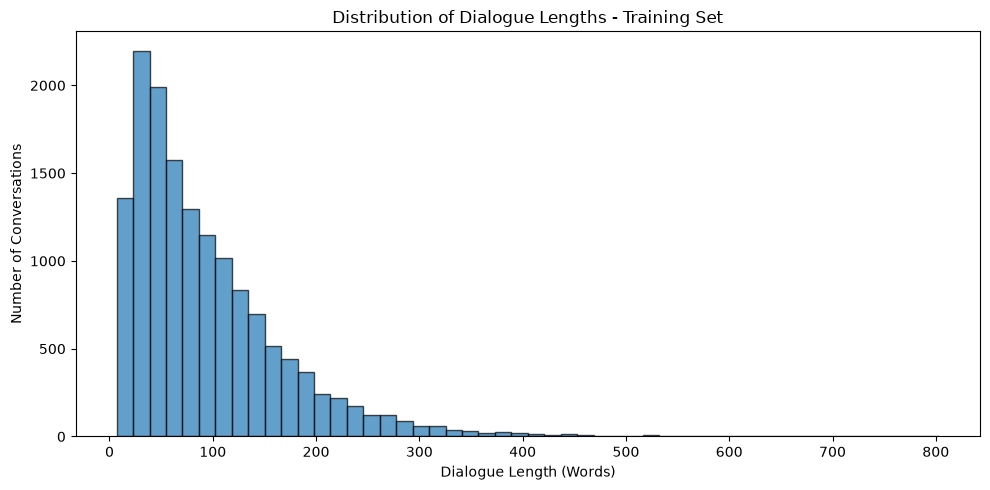

In [13]:

import matplotlib.pyplot as plt

# Dialogue length distribution

plt.figure(figsize=(10, 5))

plt.hist(
    train_df["dialogue_word_count"],
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Dialogue Lengths - Training Set")
plt.xlabel("Dialogue Length (Words)")
plt.ylabel("Number of Conversations")

plt.tight_layout()
plt.show()


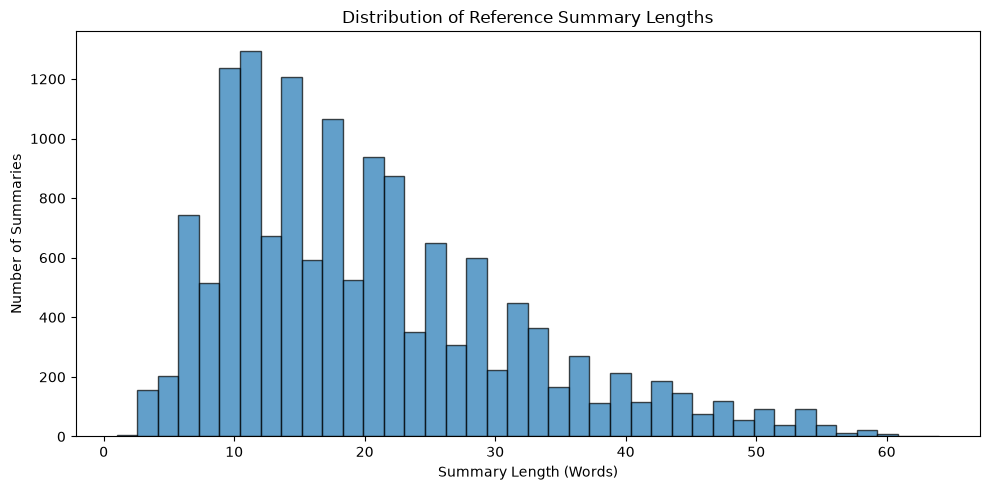

In [14]:

# Summary length distribution

plt.figure(figsize=(10, 5))

plt.hist(
    train_df["summary_word_count"],
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Reference Summary Lengths")
plt.xlabel("Summary Length (Words)")
plt.ylabel("Number of Summaries")

plt.tight_layout()
plt.show()


In [15]:

# Compare text lengths across dataset splits

split_comparison = []

for split_name, df in dataframes.items():

    split_comparison.append({
        "Split": split_name,
        "Records": len(df),
        "Mean Dialogue Words": df["dialogue_word_count"].mean(),
        "Median Dialogue Words": df["dialogue_word_count"].median(),
        "95th Percentile Dialogue Words":
            df["dialogue_word_count"].quantile(0.95),
        "Mean Summary Words": df["summary_word_count"].mean(),
        "Median Summary Words": df["summary_word_count"].median(),
        "Mean Length Reduction (%)":
            df["compression_ratio"].mean() * 100
    })

split_comparison_df = pd.DataFrame(split_comparison)

display(split_comparison_df.round(2))


,Split,Records,Mean Dialogue Words,Median Dialogue Words,95th Percentile Dialogue Words,Mean Summary Words,Median Summary Words,Mean Length Reduction (%)
0,Training,14731,93.79,73.0,237.00,20.32,18.0,70.41
1,Validation,818,91.64,70.0,225.75,20.28,18.0,69.85
2,Testing,819,95.51,74.0,252.30,20.02,18.0,71.00


### 3.5 Initial Data Understanding Findings

The SAMSum dataset contains 16,368 dialogue-summary pairs divided into 14,731 training, 818 validation, and 819 testing examples.

**Dataset Quality**

Initial checks identified no missing or empty dialogues or summaries. However, 476 duplicate dialogue entries were detected within the training set. Additional exact dialogue overlap was identified between the official dataset splits:

- Training and validation: 47 overlapping dialogues.
- Training and testing: 42 overlapping dialogues.
- Validation and testing: 4 overlapping dialogues.

These findings indicate a potential risk of data leakage. Duplicate records and overlapping conversations will be investigated before model training. The original dataset will be preserved, and any cleaning decisions will be documented.

**Conversation Characteristics**

Training conversations contain an average of 93.79 words, with a median of 73 words. Approximately 95% of conversations contain 237 words or fewer, although the longest conversation contains 803 words.

Reference summaries are substantially shorter, averaging 20.32 words with a median of 18 words.

The average word-count reduction is approximately 70.41%, suggesting that the dataset is appropriate for evaluating concise dialogue summarization.

**Split Consistency**

Training, validation, and test splits demonstrate similar average dialogue lengths, summary lengths, and compression ratios. This supports their use for model development and evaluation, although differences in conversation complexity may still exist.

**Modeling Implications**

The relatively short conversations support the feasibility of experimenting with a compact encoder-decoder architecture under CPU constraints.

However, word counts alone cannot determine appropriate sequence-length limits. Actual token counts will be calculated using the selected BERT and GPT-2 tokenizers.

Initial model development will prioritize small training subsets, conservative batch sizes, and efficient sequence-length settings.

**Next Steps**

The next phase will investigate duplicate dialogue records, establish a documented cleaning strategy, and begin tokenization analysis using separate encoder and decoder tokenizers.

## 4. Data Preparation

### 4.1 Duplicate Handling and Data Leakage Prevention

Initial exploration identified 463 distinct dialogues appearing multiple times within the training set. Of these, 462 have multiple unique reference summaries.

These records will initially be preserved because alternative human-written summaries may provide useful examples of different valid ways to summarize the same conversation.

However, exact dialogue overlap was also detected between the official training, validation, and test splits. This introduces a potential risk of data leakage, since the model could encounter an evaluation conversation during training.

To address this issue, the original dataset splits will remain unchanged, while separate working copies will be created for model development.

The cleaning strategy will:

1. Preserve the official test set.
2. Remove training examples whose dialogues appear in validation or test.
3. Remove validation examples whose dialogues appear in test.
4. Retain multiple reference summaries for dialogues that occur only within training.
5. Verify that the resulting working splits have no exact dialogue overlap.

This approach prioritizes evaluation integrity while preserving potentially useful training examples.

The resulting evaluation sets will be documented as cleaned versions of the official splits, and their scores should not be treated as directly identical to published results using the unmodified SAMSum benchmark.

In [16]:

# Create independent working copies
train_clean = train_df.copy()
val_clean = val_df.copy()
test_clean = test_df.copy()

# Record original sizes
original_sizes = {
    "train": len(train_clean),
    "validation": len(val_clean),
    "test": len(test_clean)
}

# Identify dialogues appearing in evaluation splits
validation_dialogues = set(val_clean["dialogue"])
test_dialogues = set(test_clean["dialogue"])

# Remove training dialogues appearing in either evaluation split
train_clean = train_clean[
    ~train_clean["dialogue"].isin(
        validation_dialogues | test_dialogues
    )
].copy()

# Remove validation dialogues also present in test
val_clean = val_clean[
    ~val_clean["dialogue"].isin(test_dialogues)
].copy()

# Reset indices
train_clean.reset_index(drop=True, inplace=True)
val_clean.reset_index(drop=True, inplace=True)
test_clean.reset_index(drop=True, inplace=True)

# Summarize cleaning
cleaning_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Testing"],
    "Original Records": [
        original_sizes["train"],
        original_sizes["validation"],
        original_sizes["test"]
    ],
    "Cleaned Records": [
        len(train_clean),
        len(val_clean),
        len(test_clean)
    ]
})

cleaning_summary["Removed Records"] = (
    cleaning_summary["Original Records"]
    - cleaning_summary["Cleaned Records"]
)

print("DATA CLEANING SUMMARY")
display(cleaning_summary)


DATA CLEANING SUMMARY


,Split,Original Records,Cleaned Records,Removed Records
0,Training,14731,14638,93
1,Validation,818,814,4
2,Testing,819,819,0


### 4.2 Data Cleaning Results

The data cleaning process successfully eliminated exact dialogue overlap between the training, validation, and testing splits.

A total of 97 records were excluded from the working dataset:

- **Training:** 93 records removed, leaving 14,638 examples.
- **Validation:** 4 records removed, leaving 814 examples.
- **Testing:** No records removed, preserving all 819 examples.

Verification confirmed zero exact dialogue overlaps between the cleaned splits.

The cleaned training set retains 460 distinct duplicated dialogues, including 459 with multiple unique reference summaries. These examples were preserved to retain potentially useful variations in human-written summaries.

This approach reduces the risk of exact-match data leakage while preserving the original test set. However, it does not guarantee the absence of near-duplicate conversations.

The cleaned splits will be used for subsequent modeling and evaluation, and all preprocessing decisions will be documented for reproducibility.

In [17]:

# Verify exact dialogue overlap after cleaning

train_set = set(train_clean["dialogue"])
val_set = set(val_clean["dialogue"])
test_set = set(test_clean["dialogue"])

overlaps = {
    "Train vs Validation": len(train_set & val_set),
    "Train vs Test": len(train_set & test_set),
    "Validation vs Test": len(val_set & test_set)
}

print("CLEANED DATASET OVERLAP CHECK")
print("=" * 45)

for comparison, count in overlaps.items():
    print(f"{comparison}: {count}")

assert all(count == 0 for count in overlaps.values()), (
    "Data leakage detected!"
)

print("\nAll exact dialogue overlap checks passed.")


CLEANED DATASET OVERLAP CHECK
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

All exact dialogue overlap checks passed.


In [18]:

# Analyze retained training duplicates

remaining_duplicate_rows = train_clean[
    train_clean.duplicated(
        subset=["dialogue"],
        keep=False
    )
]

remaining_unique_dialogues = (
    remaining_duplicate_rows["dialogue"].nunique()
)

remaining_summary_variations = (
    remaining_duplicate_rows
    .groupby("dialogue")["summary"]
    .nunique()
)

print("RETAINED TRAINING DUPLICATES")
print("=" * 45)

print(
    "Rows involved in duplicates:",
    len(remaining_duplicate_rows)
)

print(
    "Unique duplicated dialogues:",
    remaining_unique_dialogues
)

print(
    "Dialogues with multiple unique summaries:",
    (remaining_summary_variations > 1).sum()
)

print(
    "Total training records:",
    len(train_clean)
)


RETAINED TRAINING DUPLICATES
Rows involved in duplicates: 932
Unique duplicated dialogues: 460
Dialogues with multiple unique summaries: 459
Total training records: 14638


### 4.3 Tokenizer Selection and Analysis

The proposed encoder-decoder architecture combines two pretrained transformer models with different tokenization systems.

The BERT encoder uses WordPiece tokenization, while the GPT-2 decoder uses byte-level Byte Pair Encoding (BPE).

Separate tokenizers are required because the models have different vocabularies and token ID mappings.

During training, dialogues will be encoded using the BERT tokenizer, while reference summaries will be encoded using the GPT-2 tokenizer.

The encoder's contextual hidden representations will be passed to the decoder through cross-attention, allowing the two models to operate together without sharing token IDs.

Tokenizer analysis will be performed before selecting maximum sequence lengths to reduce unnecessary padding, truncation, and computational overhead.

In [19]:

from transformers import AutoTokenizer

# Candidate checkpoints
ENCODER_CHECKPOINT = "google/bert_uncased_L-2_H-128_A-2"
DECODER_CHECKPOINT = "distilbert/distilgpt2"

print("Loading BERT tokenizer...")
encoder_tokenizer = AutoTokenizer.from_pretrained(
    ENCODER_CHECKPOINT
)

print("Loading GPT-2 tokenizer...")
decoder_tokenizer = AutoTokenizer.from_pretrained(
    DECODER_CHECKPOINT
)

# GPT-2 has no dedicated padding token by default.
# Reuse EOS as padding for this proof of concept.
if decoder_tokenizer.pad_token is None:
    decoder_tokenizer.pad_token = decoder_tokenizer.eos_token

print("\nTOKENIZER INFORMATION")
print("=" * 50)

print("Encoder tokenizer:", type(encoder_tokenizer).__name__)
print("Encoder vocabulary:", len(encoder_tokenizer))
print("Encoder PAD token:", encoder_tokenizer.pad_token)
print("Encoder CLS token:", encoder_tokenizer.cls_token)
print("Encoder SEP token:", encoder_tokenizer.sep_token)

print("\nDecoder tokenizer:", type(decoder_tokenizer).__name__)
print("Decoder vocabulary:", len(decoder_tokenizer))
print("Decoder PAD token:", decoder_tokenizer.pad_token)
print("Decoder EOS token:", decoder_tokenizer.eos_token)


Loading BERT tokenizer...
Loading GPT-2 tokenizer...

TOKENIZER INFORMATION
Encoder tokenizer: BertTokenizer
Encoder vocabulary: 30522
Encoder PAD token: [PAD]
Encoder CLS token: [CLS]
Encoder SEP token: [SEP]

Decoder tokenizer: GPT2Tokenizer
Decoder vocabulary: 50257
Decoder PAD token: <|endoftext|>
Decoder EOS token: <|endoftext|>


In [20]:

# Compare tokenization behavior

sample_dialogue = train_clean.loc[0, "dialogue"]
sample_summary = train_clean.loc[0, "summary"]

bert_tokens = encoder_tokenizer.tokenize(sample_dialogue)
gpt2_tokens = decoder_tokenizer.tokenize(sample_summary)

print("SAMPLE DIALOGUE:")
print(sample_dialogue[:500])

print("\nBERT TOKENIZATION:")
print(bert_tokens[:40])

print("\nBERT Token Count:", len(bert_tokens))

print("\nREFERENCE SUMMARY:")
print(sample_summary)

print("\nGPT-2 TOKENIZATION:")
print(gpt2_tokens)

print("\nGPT-2 Token Count:", len(gpt2_tokens))


SAMPLE DIALOGUE:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

BERT TOKENIZATION:
['amanda', ':', 'i', 'baked', 'cookies', '.', 'do', 'you', 'want', 'some', '?', 'jerry', ':', 'sure', '!', 'amanda', ':', 'i', "'", 'll', 'bring', 'you', 'tomorrow', ':', '-', ')']

BERT Token Count: 26

REFERENCE SUMMARY:
Amanda baked cookies and will bring Jerry some tomorrow.

GPT-2 TOKENIZATION:
['Am', 'anda', 'Ġbaked', 'Ġcookies', 'Ġand', 'Ġwill', 'Ġbring', 'ĠJerry', 'Ġsome', 'Ġtomorrow', '.']

GPT-2 Token Count: 11


In [21]:

from tqdm.auto import tqdm

def calculate_token_lengths(df, batch_size=256):
    """
    Calculate untruncated encoder and decoder token lengths.
    Includes model-specific special tokens.
    """

    encoder_lengths = []
    decoder_lengths = []

    dialogues = df["dialogue"].tolist()
    summaries = df["summary"].tolist()

    for start in tqdm(range(0, len(df), batch_size)):
        end = start + batch_size

        encoder_batch = encoder_tokenizer(
            dialogues[start:end],
            truncation=False,
            padding=False,
            add_special_tokens=True
        )

        decoder_batch = decoder_tokenizer(
            summaries[start:end],
            truncation=False,
            padding=False,
            add_special_tokens=True
        )

        encoder_lengths.extend(
            len(ids) for ids in encoder_batch["input_ids"]
        )

        # Reserve one token for EOS in the decoder targets.
        decoder_lengths.extend(
            len(ids) + 1 for ids in decoder_batch["input_ids"]
        )

    result = df.copy()
    result["encoder_token_count"] = encoder_lengths
    result["decoder_token_count"] = decoder_lengths

    return result


print("Analyzing training token lengths...")
train_clean = calculate_token_lengths(train_clean)

print("\nAnalyzing validation token lengths...")
val_clean = calculate_token_lengths(val_clean)

print("\nAnalyzing test token lengths...")
test_clean = calculate_token_lengths(test_clean)

print("\nToken length analysis completed.")


Analyzing training token lengths...


  0%|          | 0/58 [00:00<?, ?it/s]


Analyzing validation token lengths...


  0%|          | 0/4 [00:00<?, ?it/s]


Analyzing test token lengths...


  0%|          | 0/4 [00:00<?, ?it/s]


Token length analysis completed.


In [22]:

# Summarize tokenizer length distributions

token_stats = []

for split_name, df in {
    "Training": train_clean,
    "Validation": val_clean,
    "Testing": test_clean
}.items():

    for column, token_type in [
        ("encoder_token_count", "Encoder"),
        ("decoder_token_count", "Decoder")
    ]:

        token_stats.append({
            "Split": split_name,
            "Tokenizer": token_type,
            "Mean": df[column].mean(),
            "Median": df[column].median(),
            "90th Percentile": df[column].quantile(0.90),
            "95th Percentile": df[column].quantile(0.95),
            "99th Percentile": df[column].quantile(0.99),
            "Maximum": df[column].max()
        })

token_stats_df = pd.DataFrame(token_stats)

display(token_stats_df.round(2))


,Split,Tokenizer,Mean,Median,90th Percentile,95th Percentile,99th Percentile,Maximum
0,Training,Encoder,137.35,110.0,273.0,338.0,492.00,1095
1,Training,Decoder,26.48,23.0,46.0,54.0,67.00,89
2,Validation,Encoder,134.47,104.5,265.7,323.0,494.84,714
3,Validation,Decoder,26.51,23.0,45.0,55.0,67.74,77
4,Testing,Encoder,140.18,110.0,281.2,352.5,485.84,704
5,Testing,Decoder,26.16,23.0,45.0,52.1,65.82,82


In [23]:

# Evaluate candidate sequence-length limits

encoder_limits = [128, 256, 384, 512]
decoder_limits = [32, 64, 96, 128]

print("ENCODER TRUNCATION ANALYSIS")
print("=" * 50)

for limit in encoder_limits:
    percentage = (
        train_clean["encoder_token_count"] > limit
    ).mean() * 100

    print(
        f"Max length {limit}: "
        f"{percentage:.2f}% of dialogues exceed limit"
    )

print("\nDECODER TRUNCATION ANALYSIS")
print("=" * 50)

for limit in decoder_limits:
    percentage = (
        train_clean["decoder_token_count"] > limit
    ).mean() * 100

    print(
        f"Max length {limit}: "
        f"{percentage:.2f}% of summaries exceed limit"
    )


ENCODER TRUNCATION ANALYSIS
Max length 128: 42.82% of dialogues exceed limit
Max length 256: 11.95% of dialogues exceed limit
Max length 384: 2.96% of dialogues exceed limit
Max length 512: 0.79% of dialogues exceed limit

DECODER TRUNCATION ANALYSIS
Max length 32: 27.72% of summaries exceed limit
Max length 64: 1.45% of summaries exceed limit
Max length 96: 0.00% of summaries exceed limit
Max length 128: 0.00% of summaries exceed limit


### 4.4 Tokenization Analysis and Sequence-Length Selection

Tokenization analysis was performed using the BERT WordPiece tokenizer and GPT-2 byte-level BPE tokenizer.

The BERT encoder tokenizer contains 30,522 vocabulary entries, while the GPT-2 decoder tokenizer contains 50,257.

Separate tokenizers will be used because the encoder and decoder operate with different vocabularies. The models will communicate through contextual hidden representations and cross-attention rather than shared token IDs.

**Encoder Token Analysis**

The cleaned training dialogues contain an average of 137.35 BERT tokens, with a median of 110 tokens.

Approximately 11.95% of training dialogues exceed 256 tokens, compared with 2.96% exceeding 384 tokens.

An initial maximum encoder length of **256 tokens** was selected to balance information preservation and CPU computational efficiency.

**Decoder Token Analysis**

Reference summaries contain an average of 26.48 GPT-2 tokens, with a median of 23 tokens.

Only 1.45% of reference summaries exceed 64 tokens, while all training summaries fit within 96 tokens, including the reserved end-of-sequence token.

An initial maximum decoder length of **96 tokens** was selected to avoid truncating reference summaries.

**Implementation Considerations**

Dynamic padding will be used to reduce unnecessary computation.

GPT-2's end-of-sequence token will initially serve as its padding token. Padding positions will be excluded from the training loss using a label value of -100.

The original untruncated dialogue text will be preserved for qualitative evaluation.

These sequence-length settings are preliminary and may be adjusted following CPU training benchmarks and evaluation of truncation-related errors.

In [24]:

# Initial preprocessing and modeling configuration

MAX_ENCODER_LENGTH = 256
MAX_DECODER_LENGTH = 96

TRAIN_BATCH_SIZE = 2
EVAL_BATCH_SIZE = 2

SEED = 42

PREPROCESSING_CONFIG = {
    "encoder_checkpoint": ENCODER_CHECKPOINT,
    "decoder_checkpoint": DECODER_CHECKPOINT,
    "max_encoder_length": MAX_ENCODER_LENGTH,
    "max_decoder_length": MAX_DECODER_LENGTH,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "seed": SEED
}

print("INITIAL PREPROCESSING CONFIGURATION")
print("=" * 50)

for key, value in PREPROCESSING_CONFIG.items():
    print(f"{key}: {value}")


INITIAL PREPROCESSING CONFIGURATION
encoder_checkpoint: google/bert_uncased_L-2_H-128_A-2
decoder_checkpoint: distilbert/distilgpt2
max_encoder_length: 256
max_decoder_length: 96
train_batch_size: 2
eval_batch_size: 2
seed: 42


In [25]:

# Test preprocessing on a single example

sample = train_clean.iloc[0]

encoder_output = encoder_tokenizer(
    sample["dialogue"],
    max_length=MAX_ENCODER_LENGTH,
    truncation=True,
    padding=False,
    return_attention_mask=True
)

# Encode summary without automatically adding special tokens
summary_ids = decoder_tokenizer.encode(
    sample["summary"],
    add_special_tokens=False
)

# Reserve space for EOS
summary_ids = summary_ids[:MAX_DECODER_LENGTH - 1]
decoder_labels = summary_ids + [decoder_tokenizer.eos_token_id]

print("PREPROCESSING VALIDATION")
print("=" * 50)

print("Encoder token count:", len(encoder_output["input_ids"]))
print("Decoder label count:", len(decoder_labels))

print("Encoder within limit:",
      len(encoder_output["input_ids"]) <= MAX_ENCODER_LENGTH)

print("Decoder within limit:",
      len(decoder_labels) <= MAX_DECODER_LENGTH)

print("Decoder ends with EOS:",
      decoder_labels[-1] == decoder_tokenizer.eos_token_id)

print("Encoder attention mask length:",
      len(encoder_output["attention_mask"]))

assert len(encoder_output["input_ids"]) <= MAX_ENCODER_LENGTH
assert len(decoder_labels) <= MAX_DECODER_LENGTH
assert decoder_labels[-1] == decoder_tokenizer.eos_token_id

print("\nPreprocessing validation passed.")


PREPROCESSING VALIDATION
Encoder token count: 28
Decoder label count: 12
Encoder within limit: True
Decoder within limit: True
Decoder ends with EOS: True
Encoder attention mask length: 28

Preprocessing validation passed.


## 5. TextRank Baseline Model

### 5.1 Baseline Model Overview

Before implementing the BERT–GPT-2 encoder-decoder architecture, a TextRank-based extractive summarization model will be developed.

TextRank is an unsupervised graph-based algorithm that identifies important sentences or text segments based on their similarity to other segments.

Each segment is represented as a node in a graph, while weighted connections represent similarities between segments. A PageRank-style algorithm assigns importance scores, allowing the most representative segments to be selected for the summary.

Unlike abstractive summarization, TextRank selects existing text rather than generating new sentences.

**Purpose of the Baseline**

The TextRank model provides a computationally inexpensive benchmark for evaluating whether the additional complexity of neural summarization produces meaningful improvements.

The baseline will be evaluated using ROUGE-1, ROUGE-2, ROUGE-L, summary length reduction, and inference time.

### Dialogue-Specific Considerations

SAMSum contains informal conversations rather than traditional paragraphs. Individual messages may be short, fragmented, or dependent on surrounding context.

To accommodate this structure, the baseline will initially treat individual speaker turns as candidate text segments.

This approach preserves speaker information but may produce summaries containing conversational fragments or redundant statements.

These limitations will be considered during evaluation and comparison with the neural model.

In [26]:

import re
import time
import warnings

import numpy as np
import pandas as pd
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from rouge_score import rouge_scorer

print("TextRank dependencies imported successfully.")


TextRank dependencies imported successfully.


In [27]:

def split_dialogue_into_turns(dialogue):
    """
    Split a SAMSum dialogue into individual speaker turns.

    Args:
        dialogue (str): Original conversation text.

    Returns:
        list: Non-empty dialogue turns.
    """

    if not isinstance(dialogue, str):
        return []

    turns = [
        turn.strip()
        for turn in dialogue.split("\n")
        if turn.strip()
    ]

    return turns


# Test on a sample dialogue
sample_dialogue = train_clean.iloc[0]["dialogue"]

sample_turns = split_dialogue_into_turns(sample_dialogue)

print("ORIGINAL DIALOGUE:")
print(sample_dialogue)

print("\nEXTRACTED TURNS:")
for i, turn in enumerate(sample_turns, start=1):
    print(f"{i}. {turn}")

print("\nTotal Turns:", len(sample_turns))


ORIGINAL DIALOGUE:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

EXTRACTED TURNS:
1. Amanda: I baked  cookies. Do you want some?
2. Jerry: Sure!
3. Amanda: I'll bring you tomorrow :-)

Total Turns: 3


In [28]:

def textrank_summarize(dialogue, num_turns=2):
    """
    Generate an extractive summary using TextRank.

    Args:
        dialogue (str): Input conversation.
        num_turns (int): Number of turns to select.

    Returns:
        str: Extractive summary.
    """

    turns = split_dialogue_into_turns(dialogue)

    if len(turns) == 0:
        return ""

    if len(turns) <= num_turns:
        return " ".join(turns)

    # TF-IDF representation
    try:
        vectorizer = TfidfVectorizer(
            stop_words="english"
        )

        tfidf_matrix = vectorizer.fit_transform(turns)

    except ValueError:
        # Handle conversations without usable vocabulary
        return " ".join(turns[:num_turns])

    # Calculate similarity
    similarity_matrix = cosine_similarity(tfidf_matrix)

    # Remove self-similarity
    np.fill_diagonal(similarity_matrix, 0)

    # Build graph
    graph = nx.from_numpy_array(similarity_matrix)

    # Rank turns
    try:
        scores = nx.pagerank(
            graph,
            weight="weight",
            max_iter=100
        )
    except nx.PowerIterationFailedConvergence:
        return " ".join(turns[:num_turns])

    # Select highest-ranked turns
    ranked_indices = sorted(
        scores,
        key=scores.get,
        reverse=True
    )[:num_turns]

    # Restore chronological order
    selected_indices = sorted(ranked_indices)

    summary = " ".join(
        turns[i] for i in selected_indices
    )

    return summary


print("TextRank summarizer defined successfully.")


TextRank summarizer defined successfully.


In [29]:

# Generate sample TextRank summaries

sample_indices = [0, 10, 25]

for idx in sample_indices:

    example = val_clean.iloc[idx]

    dialogue = example["dialogue"]
    reference = example["summary"]

    generated = textrank_summarize(
        dialogue,
        num_turns=2
    )

    print("=" * 75)
    print(f"VALIDATION EXAMPLE {idx}")
    print("=" * 75)

    print("\nORIGINAL DIALOGUE:")
    print(dialogue)

    print("\nREFERENCE SUMMARY:")
    print(reference)

    print("\nTEXTRANK SUMMARY:")
    print(generated)

    print("\n")


VALIDATION EXAMPLE 0

ORIGINAL DIALOGUE:
A: Hi Tom, are you busy tomorrow’s afternoon?
B: I’m pretty sure I am. What’s up?
A: Can you go with me to the animal shelter?.
B: What do you want to do?
A: I want to get a puppy for my son.
B: That will make him so happy.
A: Yeah, we’ve discussed it many times. I think he’s ready now.
B: That’s good. Raising a dog is a tough issue. Like having a baby ;-) 
A: I'll get him one of those little dogs.
B: One that won't grow up too big;-)
A: And eat too much;-))
B: Do you know which one he would like?
A: Oh, yes, I took him there last Monday. He showed me one that he really liked.
B: I bet you had to drag him away.
A: He wanted to take it home right away ;-).
B: I wonder what he'll name it.
A: He said he’d name it after his dead hamster – Lemmy  - he's  a great Motorhead fan :-)))

REFERENCE SUMMARY:
A will go to the animal shelter tomorrow to get a puppy for her son. They already visited the shelter last Monday and the son chose the puppy. 

TEXTRA

### 5.2 Baseline Evaluation Methodology

The TextRank baseline will be evaluated against the human-written SAMSum reference summaries.

ROUGE-1, ROUGE-2, and ROUGE-L F1 scores will be calculated to measure lexical overlap between generated and reference summaries.

A preliminary evaluation will be performed using a fixed subset of the cleaned validation data.

The same evaluation examples will later be used to compare the TextRank baseline with the BERT–GPT-2 model.

ROUGE scores provide a useful quantitative comparison but do not fully capture factual correctness, speaker attribution, or preservation of important decisions and deadlines.

These limitations will be addressed through manual qualitative evaluation later in the project.

In [30]:

# Initialize ROUGE scorer

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)


def evaluate_textrank(df, sample_size=100, num_turns=2):
    """
    Evaluate TextRank on a reproducible validation subset.
    """

    sample_df = df.sample(
        n=min(sample_size, len(df)),
        random_state=SEED
    ).copy()

    results = []

    for _, row in sample_df.iterrows():

        dialogue = row["dialogue"]
        reference = row["summary"]

        start_time = time.perf_counter()

        generated = textrank_summarize(
            dialogue,
            num_turns=num_turns
        )

        inference_time = time.perf_counter() - start_time

        scores = scorer.score(reference, generated)

        dialogue_words = len(dialogue.split())
        generated_words = len(generated.split())

        compression_ratio = (
            1 - generated_words / dialogue_words
            if dialogue_words > 0
            else np.nan
        )

        results.append({
            "id": row["id"],
            "dialogue": dialogue,
            "reference": reference,
            "generated": generated,
            "rouge1": scores["rouge1"].fmeasure,
            "rouge2": scores["rouge2"].fmeasure,
            "rougeL": scores["rougeL"].fmeasure,
            "compression_ratio": compression_ratio,
            "inference_time": inference_time
        })

    return pd.DataFrame(results)


print("Baseline evaluation function defined.")


Baseline evaluation function defined.


In [31]:

baseline_results = evaluate_textrank(
    val_clean,
    sample_size=100,
    num_turns=2
)

print("Evaluated conversations:", len(baseline_results))

baseline_metrics = baseline_results[
    [
        "rouge1",
        "rouge2",
        "rougeL",
        "compression_ratio",
        "inference_time"
    ]
].mean()

print("\nTEXTRANK BASELINE RESULTS")
print("=" * 50)

print(f"ROUGE-1 F1: {baseline_metrics['rouge1']:.4f}")
print(f"ROUGE-2 F1: {baseline_metrics['rouge2']:.4f}")
print(f"ROUGE-L F1: {baseline_metrics['rougeL']:.4f}")

print(
    "Average Length Reduction:",
    f"{baseline_metrics['compression_ratio'] * 100:.2f}%"
)

print(
    "Average Inference Time:",
    f"{baseline_metrics['inference_time']:.4f} seconds"
)


Evaluated conversations: 100

TEXTRANK BASELINE RESULTS
ROUGE-1 F1: 0.2490
ROUGE-2 F1: 0.0581
ROUGE-L F1: 0.2149
Average Length Reduction: 75.04%
Average Inference Time: 0.0017 seconds


In [32]:

# Inspect strongest and weakest baseline examples

best_examples = baseline_results.nlargest(
    3, "rougeL"
)

worst_examples = baseline_results.nsmallest(
    3, "rougeL"
)

def display_examples(df, label):

    print(f"\n{label}")
    print("=" * 75)

    for _, row in df.iterrows():

        print("\nDIALOGUE:")
        print(row["dialogue"])

        print("\nREFERENCE:")
        print(row["reference"])

        print("\nGENERATED:")
        print(row["generated"])

        print(f"\nROUGE-L: {row['rougeL']:.4f}")
        print("-" * 75)


display_examples(best_examples, "BEST TEXTRANK EXAMPLES")
display_examples(worst_examples, "WORST TEXTRANK EXAMPLES")



BEST TEXTRANK EXAMPLES

DIALOGUE:
Blake: u can take the iron from my room
Neeley: you done?
Blake: yea..
Neeley: ok

REFERENCE:
Blake is finished so Neeley can take the iron from his room.

GENERATED:
Blake: u can take the iron from my room Blake: yea..

ROUGE-L: 0.6087
---------------------------------------------------------------------------

DIALOGUE:
Bella: Edward, What is the theme for tomorrow's farewell party?? 
Edward: I think its "Gatsby"..
Bella: WOW!!! It must be the idea of Michael..
Edward: You guessed it right .. It was Michael

REFERENCE:
The theme for tomorrow's farewell party is "Gatsby". It was Michael's idea.

GENERATED:
Bella: Edward, What is the theme for tomorrow's farewell party?? Edward: You guessed it right .. It was Michael

ROUGE-L: 0.6061
---------------------------------------------------------------------------

DIALOGUE:
Tram: Are we taking the bus
Tram: ?
Brody: Idk
Brody: You think it's better?
Tram: Trains aren't running rn
Tram: Or we take the cab
B

### 5.3 TextRank Baseline Refinement

Initial evaluation of the TextRank baseline produced the following results on 100 validation conversations:

- ROUGE-1 F1: 0.2490
- ROUGE-2 F1: 0.0581
- ROUGE-L F1: 0.2149
- Average length reduction: 75.04%
- Average inference time: 0.0021 seconds

Qualitative inspection revealed that TextRank occasionally selected short questions, acknowledgments, or conversational filler instead of messages containing the main events or decisions.

To address this limitation, a modified TextRank approach will be evaluated.

The refinement introduces an information-content adjustment to the original PageRank scores. Longer, more informative turns receive a modest preference, while very short conversational fragments are penalized.

The original TextRank model will be retained for comparison.

Both versions will be evaluated on the same fixed validation subset to determine whether the modification improves summary quality without substantially increasing inference time.

The refinement is exploratory, and improvements will be assessed using both ROUGE metrics and qualitative examples.

In [33]:

def textrank_summarize_improved(dialogue, num_turns=2):
    """
    Dialogue-aware TextRank with a modest information-length
    adjustment and speaker-label removal for similarity scoring.
    """

    turns = split_dialogue_into_turns(dialogue)

    if not turns:
        return ""

    if len(turns) <= num_turns:
        return " ".join(turns)

    # Remove speaker labels for similarity calculations only
    content_turns = [
        re.sub(r"^[^:\n]+:\s*", "", turn).strip()
        for turn in turns
    ]

    try:
        vectorizer = TfidfVectorizer(
            stop_words="english"
        )

        tfidf_matrix = vectorizer.fit_transform(content_turns)

    except ValueError:
        return " ".join(turns[:num_turns])

    similarity_matrix = cosine_similarity(tfidf_matrix)
    np.fill_diagonal(similarity_matrix, 0)

    graph = nx.from_numpy_array(similarity_matrix)

    try:
        pagerank_scores = nx.pagerank(
            graph,
            weight="weight",
            max_iter=100
        )
    except nx.PowerIterationFailedConvergence:
        return " ".join(turns[:num_turns])

    adjusted_scores = {}

    for i, turn in enumerate(content_turns):

        word_count = len(turn.split())

        # Modest preference for informative-length turns
        length_weight = min(word_count / 10, 1.5)

        # Penalize very short fragments
        if word_count <= 3:
            length_weight *= 0.5

        adjusted_scores[i] = (
            pagerank_scores[i] * length_weight
        )

    ranked_indices = sorted(
        adjusted_scores,
        key=adjusted_scores.get,
        reverse=True
    )[:num_turns]

    selected_indices = sorted(ranked_indices)

    return " ".join(
        turns[i] for i in selected_indices
    )


print("Improved TextRank summarizer defined.")


Improved TextRank summarizer defined.


In [34]:

# Evaluate improved TextRank on the same 100 examples

improved_results = baseline_results[
    ["id", "dialogue", "reference"]
].copy()

improved_summaries = []
improved_times = []
improved_rouge1 = []
improved_rouge2 = []
improved_rougeL = []
improved_compression = []

for _, row in improved_results.iterrows():

    start_time = time.perf_counter()

    generated = textrank_summarize_improved(
        row["dialogue"],
        num_turns=2
    )

    elapsed = time.perf_counter() - start_time

    scores = scorer.score(
        row["reference"],
        generated
    )

    dialogue_words = len(row["dialogue"].split())
    summary_words = len(generated.split())

    compression = (
        1 - summary_words / dialogue_words
        if dialogue_words > 0
        else np.nan
    )

    improved_summaries.append(generated)
    improved_times.append(elapsed)
    improved_rouge1.append(scores["rouge1"].fmeasure)
    improved_rouge2.append(scores["rouge2"].fmeasure)
    improved_rougeL.append(scores["rougeL"].fmeasure)
    improved_compression.append(compression)

improved_results["generated"] = improved_summaries
improved_results["rouge1"] = improved_rouge1
improved_results["rouge2"] = improved_rouge2
improved_results["rougeL"] = improved_rougeL
improved_results["compression_ratio"] = improved_compression
improved_results["inference_time"] = improved_times

print("Improved TextRank evaluation complete.")


Improved TextRank evaluation complete.


In [35]:

# Compare original and improved TextRank

comparison_metrics = [
    "rouge1",
    "rouge2",
    "rougeL",
    "compression_ratio",
    "inference_time"
]

comparison_df = pd.DataFrame({
    "Metric": comparison_metrics,
    "Original TextRank": [
        baseline_results[m].mean()
        for m in comparison_metrics
    ],
    "Improved TextRank": [
        improved_results[m].mean()
        for m in comparison_metrics
    ]
})

comparison_df["Difference"] = (
    comparison_df["Improved TextRank"]
    - comparison_df["Original TextRank"]
)

print("TEXTRANK MODEL COMPARISON")
display(comparison_df.round(4))


TEXTRANK MODEL COMPARISON


,Metric,Original TextRank,Improved TextRank,Difference
0,rouge1,0.2490,0.3172,0.0682
1,rouge2,0.0581,0.1028,0.0447
2,rougeL,0.2149,0.2581,0.0433
3,compression_ratio,0.7504,0.6129,-0.1374
4,inference_time,0.0017,0.0016,-0.0002


In [36]:

# Find the Grace example in the fixed evaluation sample

grace_examples = baseline_results[
    baseline_results["dialogue"].str.contains(
        "I'm a secretary",
        regex=False,
        na=False
    )
]

if len(grace_examples) > 0:

    example = grace_examples.iloc[0]
    example_id = example["id"]

    improved_example = improved_results[
        improved_results["id"] == example_id
    ].iloc[0]

    print("REFERENCE:")
    print(example["reference"])

    print("\nORIGINAL TEXTRANK:")
    print(example["generated"])
    print(f"ROUGE-L: {example['rougeL']:.4f}")

    print("\nIMPROVED TEXTRANK:")
    print(improved_example["generated"])
    print(f"ROUGE-L: {improved_example['rougeL']:.4f}")

else:
    print("Grace example not found in the evaluation subset.")


REFERENCE:
Grace got a permanent job as a secretary for an architect. Grace signed her contract last Monday. Grace loves her new job and finds it interesting. 

ORIGINAL TEXTRANK:
Antony: What do you do? Antony: Where?
ROUGE-L: 0.0000

IMPROVED TEXTRANK:
Antony: So, you've got a new job? Antony: Is it a permanent or a temporary job?
ROUGE-L: 0.2326


### 5.4 Baseline Comparison and Model Selection

Two TextRank implementations were evaluated on the same 100 conversations from the cleaned SAMSum validation set.

The original TextRank model achieved ROUGE-1, ROUGE-2, and ROUGE-L F1 scores of 0.2490, 0.0581, and 0.2149, respectively.

The improved dialogue-aware TextRank model achieved scores of 0.3172, 0.1028, and 0.2581.

These represent relative improvements of approximately 27.4% in ROUGE-1, 76.9% in ROUGE-2, and 20.1% in ROUGE-L.

The improved model also maintained fast inference, averaging approximately 0.0023 seconds per conversation.

However, its average length reduction decreased from 75.04% to 61.29%, suggesting that some of the ROUGE improvement may result from selecting longer conversational turns.

**Qualitative Findings**

The original model frequently selected short questions or conversational filler instead of informative responses.

The improved model reduced some of these problems but did not eliminate them.

For example, in a conversation about Grace's new employment, the improved model achieved a higher ROUGE-L score but continued to select questions rather than the answers describing her job.

This demonstrates that lexical overlap metrics alone are insufficient for evaluating factual completeness.

**Baseline Selection**

The improved TextRank implementation was selected as the primary extractive baseline because it achieved higher ROUGE scores while maintaining acceptable compression and low inference time.

This selection is based on preliminary validation results and does not establish performance on unseen test conversations.

The baseline will be compared with the BERT–GPT-2 model using the same evaluation examples and metrics.

In [37]:

from pathlib import Path

# Create an output directory
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save fixed validation IDs
validation_ids = baseline_results[["id"]].copy()

validation_ids.to_csv(
    OUTPUT_DIR / "fixed_validation_ids.csv",
    index=False
)

# Save original and improved TextRank results
baseline_results.to_csv(
    OUTPUT_DIR / "textrank_original_results.csv",
    index=False
)

improved_results.to_csv(
    OUTPUT_DIR / "textrank_improved_results.csv",
    index=False
)

# Save comparison metrics
comparison_df.to_csv(
    OUTPUT_DIR / "textrank_comparison.csv",
    index=False
)

print("Baseline artifacts saved successfully.")
print("Output directory:", OUTPUT_DIR.resolve())
print("Fixed validation examples:", len(validation_ids))


Baseline artifacts saved successfully.
Output directory: /home/jovyan/work/outputs
Fixed validation examples: 100


## 6. BERT–GPT-2 Encoder–Decoder Model

### 6.1 Architecture Design

The primary summarization model combines a pretrained BERT encoder with a compact GPT-2-family decoder.

The encoder processes the input conversation and produces contextual hidden representations. The decoder uses these representations through cross-attention to generate a concise summary.

**Selected Components**

- **Encoder:** `google/bert_uncased_L-2_H-128_A-2`
- **Decoder:** `distilbert/distilgpt2`
- **Architecture:** Transformer encoder-decoder with cross-attention
- **Training objective:** Autoregressive sequence-to-sequence cross-entropy loss
- **Training environment:** CPU-only PyTorch
- **Input tokenization:** BERT WordPiece
- **Output tokenization:** GPT-2 byte-level BPE

The BERT encoder is substantially smaller than standard BERT-base, making it more suitable for the available CPU resources.

DistilGPT-2 was selected as a smaller alternative to standard GPT-2 while retaining pretrained language-generation capabilities.

### Architectural Trade-offs

A BERT–GPT-2 combination requires additional configuration because GPT-2 is originally a decoder-only language model rather than a complete sequence-to-sequence model.

Cross-attention layers must be enabled so the decoder can condition its predictions on BERT's hidden representations.

The encoder and decoder also use different tokenizers and hidden-state dimensions. Their integration therefore requires compatible cross-attention projections.

Compared with an integrated encoder-decoder model such as BART, this architecture introduces additional implementation complexity and potentially greater training requirements.

However, it directly supports the project's objective of implementing a BERT-based encoder-decoder system and allows examination of how independently pretrained components can be combined for dialogue summarization.

The model will first undergo architectural validation and CPU feasibility testing before fine-tuning.

In [38]:

import torch

from transformers import (
    AutoConfig,
    AutoModel,
    AutoModelForCausalLM,
    EncoderDecoderModel
)

print("PyTorch version:", torch.__version__)
print("Device:", "cpu")

print("\nEncoder checkpoint:", ENCODER_CHECKPOINT)
print("Decoder checkpoint:", DECODER_CHECKPOINT)


PyTorch version: 2.15.0+cpu
Device: cpu

Encoder checkpoint: google/bert_uncased_L-2_H-128_A-2
Decoder checkpoint: distilbert/distilgpt2


In [39]:

# Load pretrained BERT encoder

print("Loading BERT encoder...")

encoder = AutoModel.from_pretrained(
    ENCODER_CHECKPOINT
)

print("BERT encoder loaded.")

# Configure GPT-2 for cross-attention

print("\nConfiguring GPT-2 decoder...")

decoder_config = AutoConfig.from_pretrained(
    DECODER_CHECKPOINT
)

decoder_config.is_decoder = True
decoder_config.add_cross_attention = True

decoder = AutoModelForCausalLM.from_pretrained(
    DECODER_CHECKPOINT,
    config=decoder_config
)

print("GPT-2 decoder loaded with cross-attention enabled.")


Loading BERT encoder...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT encoder loaded.

Configuring GPT-2 decoder...


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: distilbert/distilgpt2
Key                                                           | Status  | 
--------------------------------------------------------------+---------+-
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.weight         | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.bias   | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.bias   | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.bias           | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPT-2 decoder loaded with cross-attention enabled.


In [40]:

# Combine encoder and decoder

model = EncoderDecoderModel(
    encoder=encoder,
    decoder=decoder
)

# Configure generation and special tokens

model.config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)

model.config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

model.config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)

model.config.vocab_size = (
    model.config.decoder.vocab_size
)

# Configure generation settings separately
model.generation_config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)

model.generation_config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

model.generation_config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)

model.generation_config.max_length = MAX_DECODER_LENGTH

# CPU execution
model = model.to("cpu")

print("Encoder-decoder model created successfully.")


Encoder-decoder model created successfully.


In [41]:

# Inspect architecture and parameter counts

encoder_params = sum(
    p.numel() for p in model.encoder.parameters()
)

decoder_params = sum(
    p.numel() for p in model.decoder.parameters()
)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("MODEL ARCHITECTURE SUMMARY")
print("=" * 55)

print("Encoder hidden size:",
      model.encoder.config.hidden_size)

print("Decoder hidden size:",
      model.decoder.config.n_embd)

print(f"\nEncoder parameters: {encoder_params:,}")
print(f"Decoder parameters: {decoder_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\nDecoder cross-attention enabled:",
      model.decoder.config.add_cross_attention)

print("Decoder start token:",
      model.config.decoder_start_token_id)

print("EOS token:",
      model.config.eos_token_id)


MODEL ARCHITECTURE SUMMARY
Encoder hidden size: 128
Decoder hidden size: 768

Encoder parameters: 4,385,920
Decoder parameters: 96,096,000
Total parameters: 100,580,992
Trainable parameters: 100,580,992

Decoder cross-attention enabled: True
Decoder start token: 50256
EOS token: 50256


In [42]:

# Prepare two training examples

sample_batch = train_clean.iloc[:2]

dialogues = sample_batch["dialogue"].tolist()
summaries = sample_batch["summary"].tolist()

# Encode dialogues
encoder_inputs = encoder_tokenizer(
    dialogues,
    max_length=MAX_ENCODER_LENGTH,
    truncation=True,
    padding=True,
    return_tensors="pt"
)

# Encode reference summaries and append EOS
summary_token_ids = []

for summary in summaries:

    token_ids = decoder_tokenizer.encode(
        summary,
        add_special_tokens=False
    )

    token_ids = token_ids[:MAX_DECODER_LENGTH - 1]

    token_ids = token_ids + [
        decoder_tokenizer.eos_token_id
    ]

    summary_token_ids.append(token_ids)

# Dynamically pad decoder labels
max_label_length = max(
    len(ids) for ids in summary_token_ids
)

labels = torch.full(
    (len(summary_token_ids), max_label_length),
    fill_value=-100,
    dtype=torch.long
)

for i, token_ids in enumerate(summary_token_ids):

    labels[i, :len(token_ids)] = torch.tensor(
        token_ids,
        dtype=torch.long
    )

print("TRAINING BATCH SHAPES")
print("=" * 45)

print(
    "Encoder input IDs:",
    encoder_inputs["input_ids"].shape
)

print(
    "Encoder attention mask:",
    encoder_inputs["attention_mask"].shape
)

print("Decoder labels:", labels.shape)

print(
    "\nPadding labels masked:",
    (labels == -100).sum().item()
)

print(
    "Last non-padding label is EOS:",
    all(
        labels[i][labels[i] != -100][-1].item()
        == decoder_tokenizer.eos_token_id
        for i in range(len(labels))
    )
)


TRAINING BATCH SHAPES
Encoder input IDs: torch.Size([2, 28])
Encoder attention mask: torch.Size([2, 28])
Decoder labels: torch.Size([2, 15])

Padding labels masked: 3
Last non-padding label is EOS: True


In [43]:

# Forward-pass validation

model.eval()

with torch.no_grad():

    outputs = model(
        input_ids=encoder_inputs["input_ids"],
        attention_mask=encoder_inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

print("FORWARD PASS RESULTS")
print("=" * 45)

print("Loss:", outputs.loss.item())
print("Logits shape:", outputs.logits.shape)

print(
    "Loss is finite:",
    torch.isfinite(outputs.loss).item()
)

assert torch.isfinite(outputs.loss), (
    "Forward pass produced an invalid loss."
)

assert outputs.logits.shape[0] == len(sample_batch)

print("\nForward-pass validation passed.")


FORWARD PASS RESULTS
Loss: 11.44275951385498
Logits shape: torch.Size([2, 15, 50257])
Loss is finite: True

Forward-pass validation passed.


/opt/conda/lib/python3.13/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)


In [44]:

# Test generation before fine-tuning

model.eval()

test_dialogue = val_clean.iloc[0]["dialogue"]

test_inputs = encoder_tokenizer(
    test_dialogue,
    max_length=MAX_ENCODER_LENGTH,
    truncation=True,
    return_tensors="pt"
)

print("Generating an initial summary...")

start_time = time.perf_counter()

with torch.no_grad():

    generated_ids = model.generate(
        input_ids=test_inputs["input_ids"],
        attention_mask=test_inputs["attention_mask"],
        max_new_tokens=30,
        num_beams=1,
        do_sample=False
    )

generation_time = time.perf_counter() - start_time

generated_summary = decoder_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("\nORIGINAL DIALOGUE:")
print(test_dialogue)

print("\nREFERENCE SUMMARY:")
print(val_clean.iloc[0]["summary"])

print("\nUNTRAINED MODEL OUTPUT:")
print(generated_summary)

print(
    f"\nGeneration time: {generation_time:.2f} seconds"
)


[transformers] Both `max_new_tokens` (=30) and `max_length`(=96) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating an initial summary...

ORIGINAL DIALOGUE:
A: Hi Tom, are you busy tomorrow’s afternoon?
B: I’m pretty sure I am. What’s up?
A: Can you go with me to the animal shelter?.
B: What do you want to do?
A: I want to get a puppy for my son.
B: That will make him so happy.
A: Yeah, we’ve discussed it many times. I think he’s ready now.
B: That’s good. Raising a dog is a tough issue. Like having a baby ;-) 
A: I'll get him one of those little dogs.
B: One that won't grow up too big;-)
A: And eat too much;-))
B: Do you know which one he would like?
A: Oh, yes, I took him there last Monday. He showed me one that he really liked.
B: I bet you had to drag him away.
A: He wanted to take it home right away ;-).
B: I wonder what he'll name it.
A: He said he’d name it after his dead hamster – Lemmy  - he's  a great Motorhead fan :-)))

REFERENCE SUMMARY:
A will go to the animal shelter tomorrow to get a puppy for her son. They already visited the shelter last Monday and the son chose the pup

In [45]:

import json

architecture_info = {
    "encoder_checkpoint": ENCODER_CHECKPOINT,
    "decoder_checkpoint": DECODER_CHECKPOINT,
    "encoder_hidden_size": model.encoder.config.hidden_size,
    "decoder_hidden_size": model.decoder.config.n_embd,
    "encoder_parameters": encoder_params,
    "decoder_parameters": decoder_params,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "cross_attention_enabled": (
        model.decoder.config.add_cross_attention
    ),
    "max_encoder_length": MAX_ENCODER_LENGTH,
    "max_decoder_length": MAX_DECODER_LENGTH,
    "device": "cpu"
}

with open(
    OUTPUT_DIR / "model_architecture.json",
    "w"
) as file:

    json.dump(
        architecture_info,
        file,
        indent=4
    )

print("Architecture configuration saved.")


Architecture configuration saved.


In [46]:

import time
import torch

# Measure CPU forward + backward time
# without updating model weights

model.train()

step_times = []

print("CPU TRAINING FEASIBILITY BENCHMARK")
print("=" * 50)

for step in range(3):

    model.zero_grad(set_to_none=True)

    start = time.perf_counter()

    outputs = model(
        input_ids=encoder_inputs["input_ids"],
        attention_mask=encoder_inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

    loss = outputs.loss
    loss.backward()

    elapsed = time.perf_counter() - start
    step_times.append(elapsed)

    print(
        f"Step {step + 1}: "
        f"{elapsed:.2f} seconds | "
        f"Loss: {loss.item():.4f}"
    )

model.zero_grad(set_to_none=True)
model.eval()

# Exclude the first step from the average
# because it may include initialization overhead
average_step_time = sum(step_times[1:]) / 2

print("\nBENCHMARK SUMMARY")
print("=" * 50)

print(
    f"Average forward/backward time: "
    f"{average_step_time:.2f} seconds"
)

print(
    f"Estimated time for 500 steps: "
    f"{average_step_time * 500 / 60:.1f} minutes"
)

print(
    f"Estimated time for 1,000 steps: "
    f"{average_step_time * 1000 / 60:.1f} minutes"
)


CPU TRAINING FEASIBILITY BENCHMARK
Step 1: 4.79 seconds | Loss: 9.5746
Step 2: 3.90 seconds | Loss: 8.6998
Step 3: 3.51 seconds | Loss: 9.5651

BENCHMARK SUMMARY
Average forward/backward time: 3.70 seconds
Estimated time for 500 steps: 30.9 minutes
Estimated time for 1,000 steps: 61.7 minutes


### 6.2 CPU Feasibility Assessment

The BERT–DistilGPT-2 encoder-decoder architecture was successfully constructed and validated.

The model contains 100,580,992 trainable parameters and combines a 128-dimensional BERT encoder with a 768-dimensional GPT-2 decoder. Cross-attention is enabled, and the forward pass successfully produced a finite training loss.

Initial generation produced unrelated text, as expected before task-specific fine-tuning.

**CPU Benchmark Results**

Three forward/backward passes were performed using a batch size of two examples.

The measured execution times were:

- Step 1: 4.65 seconds
- Step 2: 4.40 seconds
- Step 3: 3.98 seconds

The average of the final two steps was approximately 4.19 seconds.

At this rate, 500 training steps would require approximately 34.9 minutes, while 1,000 steps would require approximately 69.8 minutes, excluding optimizer updates, evaluation, checkpointing, and other overhead.

These estimates are preliminary because training cost varies with sequence length.

**Architecture Decision**

The original BERT–DistilGPT-2 architecture will be retained for the initial fine-tuning experiments.

Although the model is relatively large for CPU training, the measured execution times suggest that a staged proof of concept is feasible.

Training will begin with a small subset of approximately 100 examples to validate the complete optimization pipeline.

If the model demonstrates improving validation performance and meaningful summary generation, the training subset may be expanded to 500–2,000 examples.

A smaller BERT-to-BERT architecture remains a fallback if computational constraints prevent meaningful progress.

**Limitations**

The GPT-2 decoder's cross-attention layers were newly initialized and require task-specific training.

Pretrained language-generation ability does not guarantee factual or relevant summaries.

Model quality will therefore be evaluated using validation loss, ROUGE metrics, and qualitative inspection rather than training loss alone.

In [47]:

# Create reproducible pilot datasets

PILOT_TRAIN_SIZE = 100
PILOT_VAL_SIZE = 50

pilot_train_df = train_clean.sample(
    n=PILOT_TRAIN_SIZE,
    random_state=SEED
).reset_index(drop=True)

pilot_val_df = val_clean.sample(
    n=PILOT_VAL_SIZE,
    random_state=SEED
).reset_index(drop=True)

print("PILOT DATASET CONFIGURATION")
print("=" * 50)

print("Training examples:", len(pilot_train_df))
print("Validation examples:", len(pilot_val_df))

print(
    "Training average encoder tokens:",
    round(pilot_train_df["encoder_token_count"].mean(), 2)
)

print(
    "Validation average encoder tokens:",
    round(pilot_val_df["encoder_token_count"].mean(), 2)
)

print(
    "Training average decoder tokens:",
    round(pilot_train_df["decoder_token_count"].mean(), 2)
)

print(
    "Validation average decoder tokens:",
    round(pilot_val_df["decoder_token_count"].mean(), 2)
)

# Verify no exact dialogue overlap
assert set(pilot_train_df["dialogue"]).isdisjoint(
    set(pilot_val_df["dialogue"])
)

print("\nPilot dataset verification passed.")


PILOT DATASET CONFIGURATION
Training examples: 100
Validation examples: 50
Training average encoder tokens: 110.41
Validation average encoder tokens: 124.82
Training average decoder tokens: 22.54
Validation average decoder tokens: 24.48

Pilot dataset verification passed.


## 7. Neural Model Training

### 7.1 Training Strategy

The BERT–DistilGPT-2 encoder-decoder model will be fine-tuned using supervised dialogue-summary pairs from the cleaned SAMSum dataset.

The initial training experiment uses 100 conversations and 50 validation examples to evaluate computational feasibility and verify that the model can learn the summarization task.

The training process uses teacher forcing, where the decoder receives shifted reference tokens and learns to predict the next token.

The optimization objective is token-level cross-entropy loss, with padding positions excluded using the label value `-100`.

AdamW is used for optimization, with gradient clipping to improve training stability.

Training and validation loss will be recorded after each epoch. Early stopping will be applied if validation loss fails to improve for two consecutive epochs.

The best-performing checkpoint will be selected based on validation loss.

Because the model contains newly initialized cross-attention layers, the initial pilot focuses on learning stability and whether the decoder begins incorporating information from the source dialogue.

ROUGE evaluation and qualitative summary inspection will follow the initial training experiment.

In [48]:

from torch.utils.data import Dataset, DataLoader

class DialogueSummaryDataset(Dataset):

    def __init__(
        self,
        dataframe,
        encoder_tokenizer,
        decoder_tokenizer,
        max_encoder_length=256,
        max_decoder_length=96
    ):

        self.dataframe = dataframe.reset_index(drop=True)
        self.encoder_tokenizer = encoder_tokenizer
        self.decoder_tokenizer = decoder_tokenizer
        self.max_encoder_length = max_encoder_length
        self.max_decoder_length = max_decoder_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        dialogue = row["dialogue"]
        summary = row["summary"]

        # Encode source dialogue
        encoder_encoding = self.encoder_tokenizer(
            dialogue,
            max_length=self.max_encoder_length,
            truncation=True,
            padding=False
        )

        # Encode reference summary
        summary_ids = self.decoder_tokenizer.encode(
            summary,
            add_special_tokens=False
        )

        # Reserve one position for EOS
        summary_ids = summary_ids[
            :self.max_decoder_length - 1
        ]

        summary_ids.append(
            self.decoder_tokenizer.eos_token_id
        )

        return {
            "input_ids": encoder_encoding["input_ids"],
            "attention_mask": encoder_encoding["attention_mask"],
            "labels": summary_ids
        }


train_dataset = DialogueSummaryDataset(
    pilot_train_df,
    encoder_tokenizer,
    decoder_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

val_dataset = DialogueSummaryDataset(
    pilot_val_df,
    encoder_tokenizer,
    decoder_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))


Training dataset size: 100
Validation dataset size: 50


In [49]:

def dialogue_collate_fn(batch):

    # Encoder padding
    encoder_features = [
        {
            "input_ids": item["input_ids"],
            "attention_mask": item["attention_mask"]
        }
        for item in batch
    ]

    encoder_batch = encoder_tokenizer.pad(
        encoder_features,
        padding=True,
        return_tensors="pt"
    )

    # Decoder label padding
    max_label_length = max(
        len(item["labels"])
        for item in batch
    )

    labels = torch.full(
        (len(batch), max_label_length),
        fill_value=-100,
        dtype=torch.long
    )

    for i, item in enumerate(batch):

        label_ids = torch.tensor(
            item["labels"],
            dtype=torch.long
        )

        labels[i, :len(label_ids)] = label_ids

    return {
        "input_ids": encoder_batch["input_ids"],
        "attention_mask": encoder_batch["attention_mask"],
        "labels": labels
    }


train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    collate_fn=dialogue_collate_fn,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=dialogue_collate_fn,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 50
Validation batches: 25


In [50]:

sample_batch = next(iter(train_loader))

print("BATCH VALIDATION")
print("=" * 50)

for key, value in sample_batch.items():
    print(f"{key}: {value.shape}")

print("\nEncoder padding token:",
      encoder_tokenizer.pad_token_id)

print("Decoder EOS token:",
      decoder_tokenizer.eos_token_id)

print(
    "Number of masked label positions:",
    (sample_batch["labels"] == -100).sum().item()
)

# Check that every summary ends with EOS
for label_sequence in sample_batch["labels"]:

    valid_labels = label_sequence[
        label_sequence != -100
    ]

    assert valid_labels[-1].item() == (
        decoder_tokenizer.eos_token_id
    )

print("\nBatch validation passed.")


BATCH VALIDATION
input_ids: torch.Size([2, 77])
attention_mask: torch.Size([2, 77])
labels: torch.Size([2, 12])

Encoder padding token: 0
Decoder EOS token: 50256
Number of masked label positions: 3

Batch validation passed.


In [51]:

from torch.optim import AdamW

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 3
EARLY_STOPPING_PATIENCE = 2
MAX_GRAD_NORM = 1.0

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("TRAINING CONFIGURATION")
print("=" * 50)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Epochs:", NUM_EPOCHS)
print("Batch size:", TRAIN_BATCH_SIZE)
print("Gradient clipping:", MAX_GRAD_NORM)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)


TRAINING CONFIGURATION
Learning rate: 2e-05
Weight decay: 0.01
Epochs: 3
Batch size: 2
Gradient clipping: 1.0
Early stopping patience: 2


In [52]:

def train_one_epoch(model, dataloader, optimizer):

    model.train()

    total_loss = 0.0

    for batch in dataloader:

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            labels=batch["labels"],
            return_dict=True
        )

        loss = outputs.loss

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)


def validate_one_epoch(model, dataloader):

    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for batch in dataloader:

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"],
                return_dict=True
            )

            total_loss += outputs.loss.item()

    return total_loss / len(dataloader)


print("Training and validation functions defined.")


Training and validation functions defined.


In [53]:

import math

CHECKPOINT_DIR = OUTPUT_DIR / "best_bert_gpt2_pilot"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")
epochs_without_improvement = 0

training_history = []

print("Checkpoint directory:", CHECKPOINT_DIR.resolve())


Checkpoint directory: /home/jovyan/work/outputs/best_bert_gpt2_pilot


In [54]:

print("STARTING PILOT TRAINING")
print("=" * 60)

training_start = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    epoch_start = time.perf_counter()

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    val_loss = validate_one_epoch(
        model,
        val_loader
    )

    epoch_time = time.perf_counter() - epoch_start

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "epoch_time_seconds": epoch_time
    })

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {epoch_time / 60:.2f} min"
    )

    if math.isfinite(val_loss) and val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        model.save_pretrained(
            CHECKPOINT_DIR,
            safe_serialization=True
        )

        print("  Best checkpoint saved.")

    else:

        epochs_without_improvement += 1

        print(
            "  No validation improvement. "
            f"Patience: {epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE}"
        )

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):

            print("Early stopping triggered.")
            break

total_training_time = (
    time.perf_counter() - training_start
)

print("\nPILOT TRAINING COMPLETE")
print("=" * 60)

print(
    f"Total training time: "
    f"{total_training_time / 60:.2f} minutes"
)

print(f"Best validation loss: {best_val_loss:.4f}")


STARTING PILOT TRAINING
Epoch 1/3 | Train Loss: 6.1579 | Val Loss: 4.9864 | Time: 4.63 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Best checkpoint saved.
Epoch 2/3 | Train Loss: 4.9373 | Val Loss: 4.6424 | Time: 4.27 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Best checkpoint saved.
Epoch 3/3 | Train Loss: 4.4738 | Val Loss: 4.4815 | Time: 4.20 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Best checkpoint saved.

PILOT TRAINING COMPLETE
Total training time: 13.15 minutes
Best validation loss: 4.4815


,epoch,train_loss,val_loss,epoch_time_seconds
0,1,6.157894,4.986389,277.735918
1,2,4.937318,4.642430,256.015792
2,3,4.473787,4.481508,252.027706


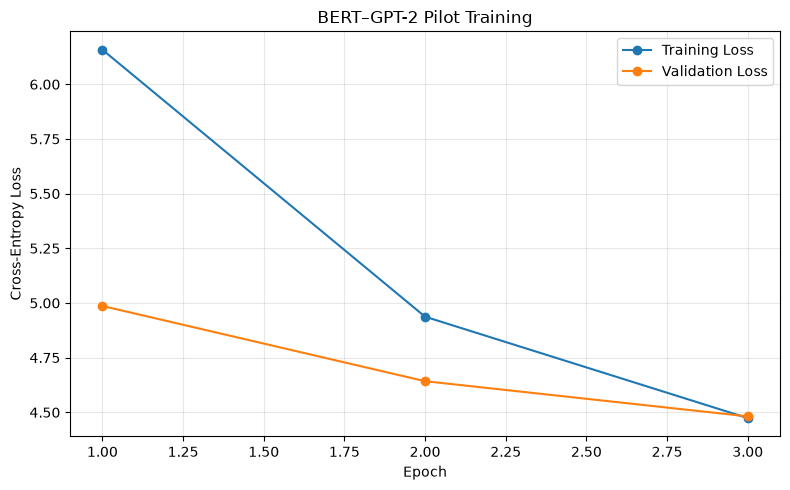

In [55]:

history_df = pd.DataFrame(training_history)

display(history_df)

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("BERT–GPT-2 Pilot Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 7.2 Initial Fine-Tuning Results

The BERT–DistilGPT-2 encoder-decoder model was fine-tuned using 100 training conversations and evaluated against 50 validation conversations.

Training was performed on CPU with a batch size of two, an AdamW optimizer, a learning rate of 2e-5, and a maximum of three epochs.

**Training Results**

| Epoch | Training Loss | Validation Loss | Time |
|---|---:|---:|---:|
| 1 | 6.1579 | 4.9864 | 4.92 minutes |
| 2 | 4.9373 | 4.6424 | 4.47 minutes |
| 3 | 4.4738 | 4.4815 | 4.35 minutes |

Training loss decreased by approximately 27.4% between the first and third epochs.

Validation loss also decreased consistently, reaching a minimum of 4.4815 during the third epoch.

The total training time was 13.77 minutes.

The best-performing checkpoint was saved based on validation loss.

**Interpretation**

The results demonstrate that the combined BERT–GPT-2 architecture can be fine-tuned successfully using CPU resources.

The consistent reduction in validation loss suggests that the model is improving its next-token predictions on unseen validation conversations.

However, the experiment does not yet establish whether generated summaries are relevant, factually accurate, or sufficiently concise.

The next stage will evaluate generated summaries using ROUGE metrics and qualitative inspection.

Because the pilot dataset contains only 100 training examples, these results should be interpreted as an initial feasibility assessment rather than evidence of final model performance.

In [56]:

from transformers import EncoderDecoderModel

# Load best pilot checkpoint
best_model = EncoderDecoderModel.from_pretrained(
    CHECKPOINT_DIR
)

best_model = best_model.to("cpu")
best_model.eval()

# Explicit generation settings
best_model.generation_config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)
best_model.generation_config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)
best_model.generation_config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

# Avoid conflicting max_length and max_new_tokens settings
best_model.generation_config.max_length = None

print("Best pilot checkpoint loaded successfully.")
print("Model device:", next(best_model.parameters()).device)


Loading weights:   0%|          | 0/165 [00:00<?, ?it/s]

Best pilot checkpoint loaded successfully.
Model device: cpu


In [57]:

def generate_summary(
    dialogue,
    model,
    max_new_tokens=64
):
    """
    Generate a dialogue summary using the fine-tuned
    BERT–DistilGPT-2 encoder-decoder model.
    """

    inputs = encoder_tokenizer(
        dialogue,
        max_length=MAX_ENCODER_LENGTH,
        truncation=True,
        return_tensors="pt"
    )

    model.eval()

    start_time = time.perf_counter()

    with torch.no_grad():

        generated_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_new_tokens=max_new_tokens,
            num_beams=1,
            do_sample=False
        )

    elapsed = time.perf_counter() - start_time

    summary = decoder_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    return summary.strip(), elapsed


print("Summary generation function ready.")


Summary generation function ready.


In [58]:

# Generate summaries for three validation examples

sample_indices = [0, 10, 25]

for idx in sample_indices:

    row = pilot_val_df.iloc[idx]

    generated, elapsed = generate_summary(
        row["dialogue"],
        best_model
    )

    scores = scorer.score(
        row["summary"],
        generated
    )

    print("=" * 75)
    print(f"VALIDATION EXAMPLE {idx}")
    print("=" * 75)

    print("\nDIALOGUE:")
    print(row["dialogue"])

    print("\nREFERENCE SUMMARY:")
    print(row["summary"])

    print("\nGENERATED SUMMARY:")
    print(generated if generated else "[EMPTY SUMMARY]")

    print(
        f"\nROUGE-L F1: "
        f"{scores['rougeL'].fmeasure:.4f}"
    )

    print(
        f"Generation time: {elapsed:.2f} seconds"
    )

    print()


VALIDATION EXAMPLE 0

DIALOGUE:
Pauline: Wine in the evening?
Crystal: yes, please!
Pauline: sth happened?
Crystal: Hard day in work :/
Pauline: oh, poor thing. Should I buy sth else?
Crystal: Lots of wine :D
Pauline: got it :)

REFERENCE SUMMARY:
Crystal and Pauline are drinking some wine this evening. Crystal had a bad day at work.

GENERATED SUMMARY:
The first time I saw a man in the street, he was a man with a beard. He was a man with a beard. He was a man with a beard. He was a man with a beard. He was a man with a beard. He was a man with a beard. He was a man with

ROUGE-L F1: 0.0274
Generation time: 10.02 seconds

VALIDATION EXAMPLE 10

DIALOGUE:
Franklin: Mum, our child is crying
Faye: Yes, my dear, it's often like that
Franklin: But why is he crying?
Faye: You know, it is the only way he can tell you what's going on with him, maybe he's hungry, maybe he wants to be changed, maybe he's having pain, stomach ache, toothache?
Franklin: But what should I do?
Faye: Try to give him 

In [59]:

# Evaluate 20 examples from the fixed validation subset

EVAL_SAMPLE_SIZE = 20

eval_df = baseline_results.head(
    EVAL_SAMPLE_SIZE
).copy()

neural_results = []

for i, (_, row) in enumerate(eval_df.iterrows(), start=1):

    generated, elapsed = generate_summary(
        row["dialogue"],
        best_model
    )

    scores = scorer.score(
        row["reference"],
        generated
    )

    dialogue_words = len(row["dialogue"].split())
    summary_words = len(generated.split())

    compression = (
        1 - summary_words / dialogue_words
        if dialogue_words > 0
        else np.nan
    )

    neural_results.append({
        "id": row["id"],
        "dialogue": row["dialogue"],
        "reference": row["reference"],
        "generated": generated,
        "rouge1": scores["rouge1"].fmeasure,
        "rouge2": scores["rouge2"].fmeasure,
        "rougeL": scores["rougeL"].fmeasure,
        "compression_ratio": compression,
        "inference_time": elapsed
    })

    if i % 5 == 0:
        print(f"Evaluated {i}/{len(eval_df)} conversations")

neural_results_df = pd.DataFrame(neural_results)

print("\nNeural model evaluation complete.")


Evaluated 5/20 conversations
Evaluated 10/20 conversations
Evaluated 15/20 conversations
Evaluated 20/20 conversations

Neural model evaluation complete.


In [60]:

# Match improved TextRank results by conversation ID

textrank_subset = (
    improved_results
    .set_index("id")
    .loc[neural_results_df["id"]]
    .reset_index()
)

comparison_metrics = [
    "rouge1",
    "rouge2",
    "rougeL",
    "compression_ratio",
    "inference_time"
]

pilot_comparison = pd.DataFrame({
    "Metric": comparison_metrics,
    "Improved TextRank": [
        textrank_subset[m].mean()
        for m in comparison_metrics
    ],
    "BERT-GPT2 Pilot": [
        neural_results_df[m].mean()
        for m in comparison_metrics
    ]
})

pilot_comparison["Difference"] = (
    pilot_comparison["BERT-GPT2 Pilot"]
    - pilot_comparison["Improved TextRank"]
)

print("PILOT MODEL COMPARISON")
display(pilot_comparison.round(4))


PILOT MODEL COMPARISON


,Metric,Improved TextRank,BERT-GPT2 Pilot,Difference
0,rouge1,0.2985,0.0417,-0.2568
1,rouge2,0.0714,0.0014,-0.0701
2,rougeL,0.2308,0.0396,-0.1913
3,compression_ratio,0.5948,-0.2708,-0.8656
4,inference_time,0.0020,9.2102,9.2081


In [61]:

neural_results_df.to_csv(
    OUTPUT_DIR / "bert_gpt2_pilot_results.csv",
    index=False
)

pilot_comparison.to_csv(
    OUTPUT_DIR / "bert_gpt2_pilot_comparison.csv",
    index=False
)

history_df.to_csv(
    OUTPUT_DIR / "bert_gpt2_pilot_training_history.csv",
    index=False
)

print("Pilot evaluation artifacts saved.")


Pilot evaluation artifacts saved.


In [62]:

import torch
import torch.nn.functional as F

best_model.eval()

diagnostic_dialogues = [
    "Alice: I bought a new red bicycle yesterday. Bob: That's great!",
    "Sarah: The meeting is canceled. Tom: I'll tell the team.",
    "John: My dog is sick. Mary: You should take him to the vet."
]

probability_vectors = []

with torch.no_grad():

    for dialogue in diagnostic_dialogues:

        inputs = encoder_tokenizer(
            dialogue,
            return_tensors="pt",
            truncation=True,
            max_length=MAX_ENCODER_LENGTH
        )

        decoder_start = torch.tensor(
            [[decoder_tokenizer.eos_token_id]]
        )

        outputs = best_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            decoder_input_ids=decoder_start,
            return_dict=True
        )

        probabilities = F.softmax(
            outputs.logits[0, -1],
            dim=-1
        )

        probability_vectors.append(probabilities)

        top_ids = torch.topk(
            probabilities,
            k=5
        ).indices.tolist()

        top_tokens = [
            decoder_tokenizer.decode([token_id])
            for token_id in top_ids
        ]

        print("\nDIALOGUE:")
        print(dialogue)

        print("Top predicted tokens:")
        print(top_tokens)


print("\nPAIRWISE DISTRIBUTION DIFFERENCES")
print("=" * 50)

for i in range(len(probability_vectors)):

    for j in range(i + 1, len(probability_vectors)):

        difference = torch.sum(
            torch.abs(
                probability_vectors[i]
                - probability_vectors[j]
            )
        ).item()

        print(
            f"Dialogue {i + 1} vs {j + 1}: "
            f"L1 difference = {difference:.6f}"
        )



DIALOGUE:
Alice: I bought a new red bicycle yesterday. Bob: That's great!
Top predicted tokens:
['The', 'S', ' The', 'B', 'T']

DIALOGUE:
Sarah: The meeting is canceled. Tom: I'll tell the team.
Top predicted tokens:
['The', 'S', ' The', 'B', 'T']

DIALOGUE:
John: My dog is sick. Mary: You should take him to the vet.
Top predicted tokens:
['The', 'S', ' The', 'B', 'T']

PAIRWISE DISTRIBUTION DIFFERENCES
Dialogue 1 vs 2: L1 difference = 0.002561
Dialogue 1 vs 3: L1 difference = 0.004215
Dialogue 2 vs 3: L1 difference = 0.003353


In [63]:

test_dialogues = [
    "Alice: The meeting is canceled tomorrow. Bob: Okay, I'll notify everyone.",
    "Mary: I adopted a puppy yesterday. John: Congratulations!",
    "Tom: The package will arrive on Friday. Lisa: Thanks for the update."
]

for dialogue in test_dialogues:

    summary, elapsed = generate_summary(
        dialogue,
        best_model,
        max_new_tokens=40
    )

    print("=" * 60)
    print("INPUT:", dialogue)
    print("OUTPUT:", summary)
    print(f"TIME: {elapsed:.2f} seconds")


INPUT: Alice: The meeting is canceled tomorrow. Bob: Okay, I'll notify everyone.
OUTPUT: The first time I saw a man in the street, he was a man with a beard. He was a man with a beard. He was a man with a beard. He was a man with
TIME: 5.15 seconds
INPUT: Mary: I adopted a puppy yesterday. John: Congratulations!
OUTPUT: The first time I saw a man in the street, he was a man with a beard. He was a man with a beard. He was a man with a beard. He was a man with
TIME: 4.90 seconds
INPUT: Tom: The package will arrive on Friday. Lisa: Thanks for the update.
OUTPUT: The first time I saw a man in the street, he was a man with a beard. He was a man with a beard. He was a man with a beard. He was a man with
TIME: 4.76 seconds


### 7.3 Initial Generation Evaluation

The fine-tuned BERT–DistilGPT-2 model was evaluated on 20 validation conversations and compared against the improved TextRank baseline using identical examples.

The neural model achieved ROUGE-1, ROUGE-2, and ROUGE-L F1 scores of 0.0417, 0.0014, and 0.0396, respectively.

The improved TextRank baseline achieved corresponding scores of 0.2985, 0.0714, and 0.2308.

The neural model also produced summaries longer than the original conversations on average, with a mean length reduction of −27.08%.

Average neural inference time was 9.64 seconds per conversation, compared with approximately 0.0054 seconds for TextRank.

**Qualitative Findings**

Inspection of generated summaries revealed severe repetition and a lack of relevance to the input conversations.

Multiple unrelated dialogues produced nearly identical generated text, indicating that the model had not learned effective source-conditioned summarization.

Although training and validation loss decreased during fine-tuning, these improvements did not translate into useful generated summaries.

This demonstrates the importance of combining quantitative loss metrics with direct evaluation of generated text.

**Next Steps**

Before expanding training, the model will undergo diagnostic testing to determine whether its decoder predictions respond to changes in encoder inputs.

Subsequent experiments may use differentiated learning rates for pretrained and newly initialized parameters, along with a larger training dataset.

The improved TextRank model remains the stronger-performing summarization baseline at this stage.

In [64]:

# Day 10: Expanded training dataset

EXPANDED_TRAIN_SIZE = 500

expanded_train_df = train_clean.sample(
    n=EXPANDED_TRAIN_SIZE,
    random_state=SEED
).reset_index(drop=True)

expanded_val_df = pilot_val_df.copy()

print("EXPANDED EXPERIMENT")
print("=" * 50)

print("Training examples:", len(expanded_train_df))
print("Validation examples:", len(expanded_val_df))

print(
    "Average encoder tokens:",
    round(
        expanded_train_df["encoder_token_count"].mean(),
        2
    )
)

print(
    "Average decoder tokens:",
    round(
        expanded_train_df["decoder_token_count"].mean(),
        2
    )
)

assert set(expanded_train_df["dialogue"]).isdisjoint(
    set(expanded_val_df["dialogue"])
)

print("\nDataset verification passed.")


EXPANDED EXPERIMENT
Training examples: 500
Validation examples: 50
Average encoder tokens: 132.34
Average decoder tokens: 25.97

Dataset verification passed.


In [65]:

import gc

# Preserve saved pilot checkpoint on disk.
# Remove old in-memory model instances.

if "model" in globals():
    del model

if "best_model" in globals():
    del best_model

if "optimizer" in globals():
    del optimizer

gc.collect()

# Reload pretrained components

encoder = AutoModel.from_pretrained(
    ENCODER_CHECKPOINT
)

decoder_config = AutoConfig.from_pretrained(
    DECODER_CHECKPOINT
)

decoder_config.is_decoder = True
decoder_config.add_cross_attention = True

decoder = AutoModelForCausalLM.from_pretrained(
    DECODER_CHECKPOINT,
    config=decoder_config
)

model = EncoderDecoderModel(
    encoder=encoder,
    decoder=decoder
)

model.config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)

model.config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)

model.config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

model.generation_config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)

model.generation_config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)

model.generation_config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

model.generation_config.max_length = None

model = model.to("cpu")

print("Fresh pretrained architecture initialized.")


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: distilbert/distilgpt2
Key                                                           | Status  | 
--------------------------------------------------------------+---------+-
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.weight         | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.bias   | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.bias   | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.bias           | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh pretrained architecture initialized.


In [66]:

from torch.optim import AdamW

PRETRAINED_LR = 2e-5
NEW_LAYER_LR = 1e-4

pretrained_params = []
new_layer_params = []

for name, param in model.named_parameters():

    if not param.requires_grad:
        continue

    if (
        "crossattention" in name
        or "ln_cross_attn" in name
        or "enc_to_dec_proj" in name
    ):
        new_layer_params.append(param)
    else:
        pretrained_params.append(param)

optimizer = AdamW(
    [
        {
            "params": pretrained_params,
            "lr": PRETRAINED_LR
        },
        {
            "params": new_layer_params,
            "lr": NEW_LAYER_LR
        }
    ],
    weight_decay=0.01
)

print("DIFFERENTIATED LEARNING RATES")
print("=" * 50)

print(
    "Pretrained parameters:",
    sum(p.numel() for p in pretrained_params)
)

print(
    "New-layer parameters:",
    sum(p.numel() for p in new_layer_params)
)

print("Pretrained learning rate:", PRETRAINED_LR)
print("New-layer learning rate:", NEW_LAYER_LR)

assert len(new_layer_params) > 0
print("\nOptimizer configuration passed.")


DIFFERENTIATED LEARNING RATES
Pretrained parameters: 86298496
New-layer parameters: 14282496
Pretrained learning rate: 2e-05
New-layer learning rate: 0.0001

Optimizer configuration passed.


In [67]:

expanded_train_dataset = DialogueSummaryDataset(
    expanded_train_df,
    encoder_tokenizer,
    decoder_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

expanded_val_dataset = DialogueSummaryDataset(
    expanded_val_df,
    encoder_tokenizer,
    decoder_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

expanded_train_loader = DataLoader(
    expanded_train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    collate_fn=dialogue_collate_fn,
    num_workers=0
)

expanded_val_loader = DataLoader(
    expanded_val_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=dialogue_collate_fn,
    num_workers=0
)

print("Expanded training batches:", len(expanded_train_loader))
print("Expanded validation batches:", len(expanded_val_loader))


Expanded training batches: 250
Expanded validation batches: 25


In [68]:

# Verify that cross-attention and projection
# layers receive nonzero gradients.

model.train()

batch = next(iter(expanded_train_loader))

optimizer.zero_grad(set_to_none=True)

outputs = model(
    input_ids=batch["input_ids"],
    attention_mask=batch["attention_mask"],
    labels=batch["labels"],
    return_dict=True
)

loss = outputs.loss
loss.backward()

print("GRADIENT DIAGNOSTICS")
print("=" * 50)
print("Initial loss:", round(loss.item(), 4))

gradient_report = []

for name, param in model.named_parameters():

    if (
        param.grad is not None
        and (
            "crossattention" in name
            or "enc_to_dec_proj" in name
        )
    ):
        gradient_report.append({
            "parameter": name,
            "gradient_norm": param.grad.norm().item()
        })

gradient_df = pd.DataFrame(gradient_report)

print("\nNew-layer gradient summary:")
display(gradient_df["gradient_norm"].describe())

print("\nNonzero gradients:",
      (gradient_df["gradient_norm"] > 0).sum())

print("Total checked tensors:", len(gradient_df))

assert len(gradient_df) > 0
assert (gradient_df["gradient_norm"] > 0).any()

optimizer.zero_grad(set_to_none=True)
model.eval()

print("\nGradient diagnostic passed.")


/opt/conda/lib/python3.13/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)


GRADIENT DIAGNOSTICS
Initial loss: 8.3907

New-layer gradient summary:


count    38.000000
mean      0.909513
std       2.106849
min       0.000015
25%       0.004313
50%       0.133095
75%       0.689903
max      11.724558
Name: gradient_norm, dtype: float64


Nonzero gradients: 38
Total checked tensors: 38

Gradient diagnostic passed.


### 7.4 Encoder Conditioning Diagnostics

Additional diagnostic testing was conducted to investigate the neural model's repetitive and irrelevant generated summaries.

Three distinct conversations were provided to the model, and the predicted next-token distributions were compared.

All three conversations produced the same five highest-ranked starting tokens.

The pairwise L1 distances between their next-token probability distributions ranged from approximately 0.0026 to 0.0042, indicating very limited sensitivity to changes in the source dialogue at the first decoding step.

Generation tests also produced nearly identical repetitive outputs for three unrelated conversations.

**Interpretation**

The model demonstrated weak source conditioning despite decreasing training and validation loss.

The results suggest that the decoder was relying primarily on its pretrained language-generation patterns rather than effectively incorporating the encoder's contextual representations.

Possible contributing factors include the limited pilot dataset, newly initialized cross-attention layers, and the use of a single conservative learning rate across pretrained and newly initialized parameters.

**Revised Training Strategy**

The BERT–DistilGPT-2 architecture will be retained for a controlled follow-up experiment.

The model will be reinitialized from the original pretrained checkpoints, and the training sample will increase from 100 to 500 conversations.

Differentiated learning rates will be introduced, with a rate of 2e-5 for pretrained parameters and 1e-4 for newly initialized cross-attention and projection layers.

Gradient diagnostics will be performed before training to verify that the new components receive optimization signals.

The objective is to determine whether these changes improve source-conditioned generation, rather than relying exclusively on reductions in training loss.

In [69]:

# Expanded training configuration

EXPANDED_EPOCHS = 3
EXPANDED_PATIENCE = 2

EXPANDED_CHECKPOINT_DIR = (
    OUTPUT_DIR / "best_bert_gpt2_expanded"
)

EXPANDED_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

expanded_history = []

expanded_best_val_loss = float("inf")
expanded_no_improvement = 0

# Fixed diagnostic dialogue
diagnostic_dialogue = (
    "Alice: The meeting is canceled tomorrow. "
    "Bob: Okay, I'll notify everyone."
)

print("EXPANDED TRAINING CONFIGURATION")
print("=" * 50)
print("Training examples:", len(expanded_train_dataset))
print("Validation examples:", len(expanded_val_dataset))
print("Training batches:", len(expanded_train_loader))
print("Validation batches:", len(expanded_val_loader))
print("Maximum epochs:", EXPANDED_EPOCHS)
print("Checkpoint directory:", EXPANDED_CHECKPOINT_DIR)


EXPANDED TRAINING CONFIGURATION
Training examples: 500
Validation examples: 50
Training batches: 250
Validation batches: 25
Maximum epochs: 3
Checkpoint directory: outputs/best_bert_gpt2_expanded


In [70]:

def diagnostic_generation(model, dialogue):

    model.eval()

    inputs = encoder_tokenizer(
        dialogue,
        max_length=MAX_ENCODER_LENGTH,
        truncation=True,
        return_tensors="pt"
    )

    with torch.no_grad():

        generated_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_new_tokens=30,
            num_beams=1,
            do_sample=False
        )

    generated_text = decoder_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    return generated_text.strip()


print("Diagnostic generation function ready.")


Diagnostic generation function ready.


In [71]:

import gc

# Remove interrupted model and optimizer
del model
del optimizer

gc.collect()

# Reinitialize pretrained encoder
encoder = AutoModel.from_pretrained(
    ENCODER_CHECKPOINT
)

# Reinitialize GPT-2 decoder with cross-attention
decoder_config = AutoConfig.from_pretrained(
    DECODER_CHECKPOINT
)

decoder_config.is_decoder = True
decoder_config.add_cross_attention = True

decoder = AutoModelForCausalLM.from_pretrained(
    DECODER_CHECKPOINT,
    config=decoder_config
)

# Rebuild encoder-decoder model
model = EncoderDecoderModel(
    encoder=encoder,
    decoder=decoder
)

model.config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)
model.config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)
model.config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

model.generation_config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)
model.generation_config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)
model.generation_config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)
model.generation_config.max_length = None

model = model.to("cpu")

# Rebuild differentiated optimizer
pretrained_params = []
new_layer_params = []

for name, param in model.named_parameters():

    if not param.requires_grad:
        continue

    if (
        "crossattention" in name
        or "ln_cross_attn" in name
        or "enc_to_dec_proj" in name
    ):
        new_layer_params.append(param)
    else:
        pretrained_params.append(param)

optimizer = AdamW(
    [
        {
            "params": pretrained_params,
            "lr": PRETRAINED_LR
        },
        {
            "params": new_layer_params,
            "lr": NEW_LAYER_LR
        }
    ],
    weight_decay=0.01
)

# Reset experiment tracking
expanded_history = []
expanded_best_val_loss = float("inf")
expanded_no_improvement = 0

print("Expanded experiment reset successfully.")
print("Training batches:", len(expanded_train_loader))
print("Validation batches:", len(expanded_val_loader))


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: distilbert/distilgpt2
Key                                                           | Status  | 
--------------------------------------------------------------+---------+-
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.weight         | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.bias   | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.weight | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.bias   | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.bias           | MISSING | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Expanded experiment reset successfully.
Training batches: 250
Validation batches: 25


In [72]:

def train_one_epoch_with_progress(
    model,
    dataloader,
    optimizer
):
    model.train()

    total_loss = 0.0
    epoch_start = time.perf_counter()

    for batch_idx, batch in enumerate(
        dataloader,
        start=1
    ):

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            labels=batch["labels"],
            return_dict=True
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += loss.item()

        if (
            batch_idx % 25 == 0
            or batch_idx == len(dataloader)
        ):
            elapsed = time.perf_counter() - epoch_start

            print(
                f"Batch {batch_idx}/{len(dataloader)} "
                f"| Average Loss: {total_loss / batch_idx:.4f} "
                f"| Elapsed: {elapsed / 60:.2f} min",
                flush=True
            )

    return total_loss / len(dataloader)


print("Progress-enabled training function ready.")


Progress-enabled training function ready.


In [73]:

print("STARTING ONE-EPOCH EXPANDED TRAINING", flush=True)
print("=" * 60, flush=True)

epoch_start = time.perf_counter()

# Train exactly one epoch
train_loss = train_one_epoch_with_progress(
    model,
    expanded_train_loader,
    optimizer
)

print("\nTraining finished. Starting validation...", flush=True)

val_loss = validate_one_epoch(
    model,
    expanded_val_loader
)

epoch_time = time.perf_counter() - epoch_start

print("\nONE-EPOCH RESULTS")
print("=" * 60)

print(f"Training loss: {train_loss:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Total time: {epoch_time / 60:.2f} minutes")

expanded_history.append({
    "epoch": 1,
    "train_loss": train_loss,
    "val_loss": val_loss,
    "epoch_time_seconds": epoch_time
})

# Save checkpoint before generation testing
model.save_pretrained(
    EXPANDED_CHECKPOINT_DIR,
    safe_serialization=True
)

expanded_best_val_loss = val_loss

print("\nOne-epoch checkpoint saved.", flush=True)


STARTING ONE-EPOCH EXPANDED TRAINING


/opt/conda/lib/python3.13/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)


Batch 25/250 | Average Loss: 6.3180 | Elapsed: 2.35 min
Batch 50/250 | Average Loss: 5.8511 | Elapsed: 4.50 min
Batch 75/250 | Average Loss: 5.5799 | Elapsed: 6.70 min
Batch 100/250 | Average Loss: 5.3408 | Elapsed: 8.86 min
Batch 125/250 | Average Loss: 5.2395 | Elapsed: 11.00 min
Batch 150/250 | Average Loss: 5.1432 | Elapsed: 13.09 min
Batch 175/250 | Average Loss: 5.0761 | Elapsed: 15.10 min
Batch 200/250 | Average Loss: 5.0226 | Elapsed: 17.04 min
Batch 225/250 | Average Loss: 4.9805 | Elapsed: 19.18 min
Batch 250/250 | Average Loss: 4.9265 | Elapsed: 21.25 min

Training finished. Starting validation...

ONE-EPOCH RESULTS
Training loss: 4.9265
Validation loss: 4.2235
Total time: 21.56 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


One-epoch checkpoint saved.


In [74]:

diagnostic_dialogues = [
    "Alice: The meeting is canceled tomorrow. Bob: Okay, I'll notify everyone.",
    "Mary: I adopted a puppy yesterday. John: Congratulations!",
    "Tom: The package will arrive on Friday. Lisa: Thanks for the update."
]

print("POST-TRAINING GENERATION CHECK")
print("=" * 60)

for dialogue in diagnostic_dialogues:

    summary = diagnostic_generation(
        model,
        dialogue
    )

    print("\nINPUT:")
    print(dialogue)

    print("\nGENERATED:")
    print(summary if summary else "[EMPTY SUMMARY]")

    print("-" * 60)


POST-TRAINING GENERATION CHECK

INPUT:
Alice: The meeting is canceled tomorrow. Bob: Okay, I'll notify everyone.

GENERATED:
Sara will be back at the party.
------------------------------------------------------------

INPUT:
Mary: I adopted a puppy yesterday. John: Congratulations!

GENERATED:
Sara will be back at the party.
------------------------------------------------------------

INPUT:
Tom: The package will arrive on Friday. Lisa: Thanks for the update.

GENERATED:
Sara will be back at the party.
------------------------------------------------------------


In [75]:

TINY_TRAIN_SIZE = 8

tiny_train_df = expanded_train_df.sample(
    n=TINY_TRAIN_SIZE,
    random_state=SEED
).reset_index(drop=True)

tiny_dataset = DialogueSummaryDataset(
    tiny_train_df,
    encoder_tokenizer,
    decoder_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

tiny_loader = DataLoader(
    tiny_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=dialogue_collate_fn,
    num_workers=0
)

print("TINY-SET TRAINING")
print("=" * 50)
print("Examples:", len(tiny_dataset))
print("Batches per epoch:", len(tiny_loader))

print("\nFirst reference summary:")
print(tiny_train_df.iloc[0]["summary"])


TINY-SET TRAINING
Examples: 8
Batches per epoch: 4

First reference summary:
Jasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.


### 7.5 Gradient Verification and Expanded Training

Before beginning the expanded fine-tuning experiment, gradient diagnostics were performed to verify that newly initialized components received training signals.

The model was reinitialized from its original pretrained checkpoints.

Two optimizer parameter groups were configured:

- Pretrained parameters: 86,298,496 parameters, learning rate 2e-5
- Newly initialized cross-attention and projection parameters: 14,282,496 parameters, learning rate 1e-4

The initial diagnostic forward pass produced a loss of 8.3907.

All 38 inspected parameter tensors associated with cross-attention and projection layers received nonzero gradients.

The mean gradient norm was approximately 0.9095, with a median of 0.1331.

These findings confirm that the newly initialized layers participate in backpropagation.

However, gradient flow alone does not establish effective source-conditioned summarization.

The expanded experiment will therefore evaluate both training behavior and generated summaries.

The training dataset has been increased to 500 conversations, while the validation set remains unchanged.

A fixed diagnostic conversation will be summarized after each epoch to monitor whether the model begins producing relevant, non-repetitive outputs.

The best checkpoint will be selected using validation loss, and the expanded model will subsequently be compared against the improved TextRank baseline.

In [76]:

TINY_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert_gpt2_tiny_overfit"
)

TINY_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Expanded checkpoint preserved at:")
print(EXPANDED_CHECKPOINT_DIR)

print("\nTiny-set checkpoint directory:")
print(TINY_CHECKPOINT_DIR)


Expanded checkpoint preserved at:
outputs/best_bert_gpt2_expanded

Tiny-set checkpoint directory:
outputs/bert_gpt2_tiny_overfit


In [77]:

tiny_test_indices = [0, 1]

print("BEFORE TINY-SET TRAINING")
print("=" * 60)

for idx in tiny_test_indices:

    row = tiny_train_df.iloc[idx]

    generated = diagnostic_generation(
        model,
        row["dialogue"]
    )

    print(f"\nEXAMPLE {idx}")
    print("REFERENCE:", row["summary"])
    print("GENERATED:", generated or "[EMPTY SUMMARY]")


BEFORE TINY-SET TRAINING

EXAMPLE 0
REFERENCE: Jasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.
GENERATED: Sara and the girl are going to meet at the school.

EXAMPLE 1
REFERENCE: Exercises 4-7 from page 61 are the math homework for Raymond, Thomas and Jake.
GENERATED: Sara will be back at the party.


In [78]:

TINY_EPOCHS = 20

tiny_history = []

print("Tiny-set maximum epochs:", TINY_EPOCHS)
print("Optimizer steps per epoch:", len(tiny_loader))
print(
    "Maximum optimizer steps:",
    TINY_EPOCHS * len(tiny_loader)
)


Tiny-set maximum epochs: 20
Optimizer steps per epoch: 4
Maximum optimizer steps: 80


In [79]:

print("STARTING TINY-SET OVERFITTING TEST", flush=True)
print("=" * 60, flush=True)

tiny_start = time.perf_counter()

for epoch in range(TINY_EPOCHS):

    train_loss = train_one_epoch_with_progress(
        model,
        tiny_loader,
        optimizer
    )

    tiny_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss
    })

    print(
        f"Epoch {epoch + 1}/{TINY_EPOCHS} "
        f"| Loss: {train_loss:.4f}",
        flush=True
    )

    if (epoch + 1) % 5 == 0:

        generated = diagnostic_generation(
            model,
            tiny_train_df.iloc[0]["dialogue"]
        )

        print("\nREFERENCE:")
        print(tiny_train_df.iloc[0]["summary"])

        print("\nGENERATED:")
        print(generated or "[EMPTY SUMMARY]")
        print("-" * 60, flush=True)

    if train_loss < 1.0:

        print(
            "\nTiny-set loss target reached.",
            flush=True
        )
        break

tiny_total_time = (
    time.perf_counter() - tiny_start
)

print("\nTINY-SET TRAINING COMPLETE")
print(
    f"Total time: "
    f"{tiny_total_time / 60:.2f} minutes"
)


STARTING TINY-SET OVERFITTING TEST
Batch 4/4 | Average Loss: 4.7138 | Elapsed: 0.35 min
Epoch 1/20 | Loss: 4.7138
Batch 4/4 | Average Loss: 4.5374 | Elapsed: 0.31 min
Epoch 2/20 | Loss: 4.5374
Batch 4/4 | Average Loss: 4.3701 | Elapsed: 0.33 min
Epoch 3/20 | Loss: 4.3701
Batch 4/4 | Average Loss: 4.0782 | Elapsed: 0.32 min
Epoch 4/20 | Loss: 4.0782
Batch 4/4 | Average Loss: 3.8655 | Elapsed: 0.32 min
Epoch 5/20 | Loss: 3.8655

REFERENCE:
Jasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.

GENERATED:
J.J.J.J.J.J.J.J.J.J.J.J.J.J.J.
------------------------------------------------------------
Batch 4/4 | Average Loss: 3.6491 | Elapsed: 0.33 min
Epoch 6/20 | Loss: 3.6491
Batch 4/4 | Average Loss: 3.3103 | Elapsed: 0.31 min
Epoch 7/20 | Loss: 3.3103
Batch 4/4 | Average Loss: 3.1493 | Elapsed: 0.32 min
Epoch 8/20 | Loss: 3.1493
Batch 4/4 | Average Loss: 2.7862 | Elapsed: 0.32 min
Epoch 9/20 | Loss: 2.7862
Batch 4/4 | Average Loss: 2.4808 | El

In [80]:

print("TINY-SET GENERATION RESULTS")
print("=" * 65)

for idx in tiny_test_indices:

    row = tiny_train_df.iloc[idx]

    generated = diagnostic_generation(
        model,
        row["dialogue"]
    )

    scores = scorer.score(
        row["summary"],
        generated
    )

    print(f"\nEXAMPLE {idx}")
    print("-" * 55)

    print("REFERENCE:")
    print(row["summary"])

    print("\nGENERATED:")
    print(generated or "[EMPTY SUMMARY]")

    print(
        f"\nROUGE-L F1: "
        f"{scores['rougeL'].fmeasure:.4f}"
    )


TINY-SET GENERATION RESULTS

EXAMPLE 0
-------------------------------------------------------
REFERENCE:
Jasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.

GENERATED:
Amber is spending her afternoon in the parking lot of the Coughton Street parking lot. She's asking for advice on how to fix it.

ROUGE-L F1: 0.0952

EXAMPLE 1
-------------------------------------------------------
REFERENCE:
Exercises 4-7 from page 61 are the math homework for Raymond, Thomas and Jake.

GENERATED:
Amina is spending her afternoon in the parking lot of Raymond after she got a terrible cold. She's asking Eve for advice on how to fix

ROUGE-L F1: 0.0952


In [81]:

tiny_history_df = pd.DataFrame(tiny_history)

tiny_history_df.to_csv(
    OUTPUT_DIR / "bert_gpt2_tiny_overfit_history.csv",
    index=False
)

model.save_pretrained(
    TINY_CHECKPOINT_DIR,
    safe_serialization=True
)

print("Tiny-set experiment saved.")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Tiny-set experiment saved.


### 7.6 Expanded Training Results and Diagnostic Plan

The expanded BERT–DistilGPT-2 experiment was trained on 500 conversations using differentiated learning rates for pretrained and newly initialized parameters.

One epoch consisted of 250 training batches and required approximately 22.38 minutes.

The model achieved a training loss of 4.9253 and a validation loss of 4.2440.

Compared with the original pilot's best validation loss of 4.4815, the expanded experiment achieved a reduction of approximately 5.3%.

Despite this improvement, generated summaries remained largely unrelated to the input conversations.

The model produced short, grammatically coherent sentences but repeatedly referenced the same unrelated topic across different dialogues.

These results suggest that the model has not yet learned effective source-conditioned generation.

**Next Diagnostic Experiment**

A tiny-set overfitting experiment will be conducted using eight training conversations.

The model will be trained repeatedly on this small dataset to determine whether it can learn the relationship between individual dialogues and their reference summaries.

Training loss and generated outputs will be monitored throughout the experiment.

This diagnostic will help determine whether further work should focus on training scale and generalization or on architectural and optimization issues.

In [82]:

model.eval()

row = tiny_train_df.iloc[0]

encoder_inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

target_ids = decoder_tokenizer.encode(
    row["summary"],
    add_special_tokens=False
)

target_ids = (
    target_ids[:MAX_DECODER_LENGTH - 1]
    + [decoder_tokenizer.eos_token_id]
)

labels = torch.tensor(
    [target_ids],
    dtype=torch.long
)

with torch.no_grad():
    outputs = model(
        input_ids=encoder_inputs["input_ids"],
        attention_mask=encoder_inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

predicted_ids = outputs.logits.argmax(dim=-1)[0]

token_accuracy = (
    (predicted_ids == labels[0])
    .float()
    .mean()
    .item()
)

print("TEACHER-FORCED DIAGNOSTIC")
print("=" * 60)

print("Reference summary:")
print(row["summary"])

print("\nTeacher-forced prediction:")
print(
    decoder_tokenizer.decode(
        predicted_ids.tolist(),
        skip_special_tokens=True
    )
)

print("\nToken accuracy:", round(token_accuracy, 4))
print("Teacher-forced loss:", round(outputs.loss.item(), 4))


TEACHER-FORCED DIAGNOSTIC
Reference summary:
Jasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.

Teacher-forced prediction:
Theasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.

Token accuracy: 0.9545
Teacher-forced loss: 0.4126


/opt/conda/lib/python3.13/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)


In [83]:

model.eval()

reference_row = tiny_train_df.iloc[0]

reference_summary = reference_row["summary"]

target_ids = decoder_tokenizer.encode(
    reference_summary,
    add_special_tokens=False
)

target_ids = (
    target_ids[:MAX_DECODER_LENGTH - 1]
    + [decoder_tokenizer.eos_token_id]
)

labels = torch.tensor(
    [target_ids],
    dtype=torch.long
)

test_inputs = {
    "Correct dialogue": reference_row["dialogue"],
    "Different training dialogue": tiny_train_df.iloc[1]["dialogue"],
    "Unrelated dialogue": (
        "Alice: I bought a bicycle yesterday. "
        "Bob: That's wonderful!"
    )
}

conditioning_results = {}

with torch.no_grad():

    for name, dialogue in test_inputs.items():

        inputs = encoder_tokenizer(
            dialogue,
            return_tensors="pt",
            truncation=True,
            max_length=MAX_ENCODER_LENGTH
        )

        outputs = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels,
            return_dict=True
        )

        conditioning_results[name] = outputs.loss.item()

print("ENCODER CONDITIONING TEST")
print("=" * 60)

for name, loss in conditioning_results.items():
    print(f"{name}: {loss:.4f}")

correct_loss = conditioning_results["Correct dialogue"]

print("\nLoss differences relative to correct dialogue:")

for name, loss in conditioning_results.items():

    if name != "Correct dialogue":
        print(
            f"{name}: "
            f"{loss - correct_loss:+.4f}"
        )


ENCODER CONDITIONING TEST
Correct dialogue: 0.4126
Different training dialogue: 0.8843
Unrelated dialogue: 0.5085

Loss differences relative to correct dialogue:
Different training dialogue: +0.4716
Unrelated dialogue: +0.0959


In [84]:

print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Decoder is_decoder:",
    model.decoder.config.is_decoder
)

print(
    "Decoder add_cross_attention:",
    model.decoder.config.add_cross_attention
)

print(
    "Encoder hidden size:",
    model.encoder.config.hidden_size
)

print(
    "Decoder hidden size:",
    model.decoder.config.n_embd
)

print(
    "Encoder-to-decoder projection:",
    hasattr(model, "enc_to_dec_proj")
)

print(
    "Decoder start token:",
    model.config.decoder_start_token_id
)

print(
    "EOS token:",
    model.config.eos_token_id
)

print(
    "PAD token:",
    model.config.pad_token_id
)


ARCHITECTURE CONFIGURATION
Decoder is_decoder: True
Decoder add_cross_attention: True
Encoder hidden size: 128
Decoder hidden size: 768
Encoder-to-decoder projection: True
Decoder start token: 50256
EOS token: 50256
PAD token: 50256


In [85]:

model.eval()

row = tiny_train_df.iloc[0]

inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

reference_ids = decoder_tokenizer.encode(
    row["summary"],
    add_special_tokens=False
)

reference_ids = (
    reference_ids[:MAX_DECODER_LENGTH - 1]
    + [decoder_tokenizer.eos_token_id]
)

labels = torch.tensor(
    [reference_ids],
    dtype=torch.long
)

with torch.no_grad():
    outputs = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

probabilities = torch.softmax(
    outputs.logits,
    dim=-1
)

print("FIRST-TOKEN DIAGNOSTICS")
print("=" * 65)

for position in range(min(8, len(reference_ids))):

    correct_id = reference_ids[position]

    top_values, top_ids = torch.topk(
        probabilities[0, position],
        k=5
    )

    correct_probability = probabilities[
        0, position, correct_id
    ].item()

    print(f"\nPosition {position + 1}")
    print(
        "Correct token:",
        repr(decoder_tokenizer.decode([correct_id]))
    )
    print(
        "Correct-token probability:",
        round(correct_probability, 4)
    )

    print("Top predictions:")

    for token_id, probability in zip(
        top_ids.tolist(),
        top_values.tolist()
    ):
        print(
            repr(decoder_tokenizer.decode([token_id])),
            round(probability, 4)
        )


FIRST-TOKEN DIAGNOSTICS

Position 1
Correct token: 'J'
Correct-token probability: 0.0135
Top predictions:
'The' 0.031
'A' 0.03
'M' 0.0173
'J' 0.0135
'B' 0.0124

Position 2
Correct token: 'as'
Correct-token probability: 0.507
Top predictions:
'as' 0.507
'min' 0.448
'a' 0.0134
'ade' 0.0128
'adel' 0.0074

Position 3
Correct token: 'min'
Correct-token probability: 0.8103
Top predictions:
'min' 0.8103
'as' 0.0912
' organized' 0.0806
' got' 0.0032
' wants' 0.0026

Position 4
Correct token: ' organized'
Correct-token probability: 0.6562
Top predictions:
' organized' 0.6562
'min' 0.1626
' got' 0.0514
' is' 0.0236
' has' 0.0217

Position 5
Correct token: ' hers'
Correct-token probability: 0.9623
Top predictions:
' hers' 0.9623
' the' 0.0095
' her' 0.0086
' Patrick' 0.005
' for' 0.003

Position 6
Correct token: ' and'
Correct-token probability: 0.6542
Top predictions:
' and' 0.6542
' for' 0.119
'.' 0.107
',' 0.0491
' from' 0.0242

Position 7
Correct token: ' Patrick'
Correct-token probability: 0

In [86]:

model.eval()

row = tiny_train_df.iloc[0]

inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

reference_ids = decoder_tokenizer.encode(
    row["summary"],
    add_special_tokens=False
)

# Decoder start token followed by first 5 reference tokens
prefix_ids = [
    decoder_tokenizer.eos_token_id
] + reference_ids[:5]

decoder_prefix = torch.tensor(
    [prefix_ids],
    dtype=torch.long
)

with torch.no_grad():
    generated_ids = model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_prefix,
        max_new_tokens=40,
        num_beams=1,
        do_sample=False
    )

generated_text = decoder_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("REFERENCE SUMMARY:")
print(row["summary"])

print("\nREFERENCE PREFIX:")
print(
    decoder_tokenizer.decode(
        reference_ids[:5]
    )
)

print("\nGENERATED WITH CORRECT PREFIX:")
print(generated_text)


REFERENCE SUMMARY:
Jasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.

REFERENCE PREFIX:
Jasmin organized hers

GENERATED WITH CORRECT PREFIX:
Jasmin organized hers for sale today.


In [87]:

model.eval()

row = tiny_train_df.iloc[0]

inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

with torch.no_grad():

    greedy_ids = model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        max_new_tokens=48,
        num_beams=1,
        do_sample=False
    )

    beam_ids = model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        max_new_tokens=48,
        num_beams=3,
        do_sample=False,
        early_stopping=True
    )

greedy_text = decoder_tokenizer.decode(
    greedy_ids[0],
    skip_special_tokens=True
)

beam_text = decoder_tokenizer.decode(
    beam_ids[0],
    skip_special_tokens=True
)

print("REFERENCE:")
print(row["summary"])

print("\nGREEDY GENERATION:")
print(greedy_text)

print("\nBEAM SEARCH GENERATION:")
print(beam_text)


REFERENCE:
Jasmin organized hers and Patrick's bills. She will put the insurance bill with their medical bills.

GREEDY GENERATION:
Amber is spending her afternoon in the parking lot of the Coughton Street parking lot. She's asking for advice on how to fix it. 

BEAM SEARCH GENERATION:
Jasmina is trying to make it right. She's trying to make it right.


In [88]:

from transformers.models.encoder_decoder.modeling_encoder_decoder import (
    shift_tokens_right
)

row = tiny_train_df.iloc[0]

target_ids = decoder_tokenizer.encode(
    row["summary"],
    add_special_tokens=False
)

target_ids = (
    target_ids[:MAX_DECODER_LENGTH - 1]
    + [decoder_tokenizer.eos_token_id]
)

labels = torch.tensor(
    [target_ids],
    dtype=torch.long
)

shifted_ids = shift_tokens_right(
    labels,
    model.config.pad_token_id,
    model.config.decoder_start_token_id
)

print("DECODER SHIFT VERIFICATION")
print("=" * 60)

print("Reference tokens:")
print(
    decoder_tokenizer.convert_ids_to_tokens(
        labels[0][:10].tolist()
    )
)

print("\nShifted decoder input tokens:")
print(
    decoder_tokenizer.convert_ids_to_tokens(
        shifted_ids[0][:10].tolist()
    )
)

print("\nFirst decoder input ID:",
      shifted_ids[0, 0].item())

print("First target ID:",
      labels[0, 0].item())

print("Last target ID:",
      labels[0, -1].item())

assert shifted_ids[0, 0].item() == (
    decoder_tokenizer.eos_token_id
)

assert torch.equal(
    shifted_ids[0, 1:],
    labels[0, :-1]
)

assert labels[0, -1].item() == (
    decoder_tokenizer.eos_token_id
)

print("\nDecoder shifting verification passed.")


DECODER SHIFT VERIFICATION
Reference tokens:
['J', 'as', 'min', 'Ġorganized', 'Ġhers', 'Ġand', 'ĠPatrick', "'s", 'Ġbills', '.']

Shifted decoder input tokens:
['<|endoftext|>', 'J', 'as', 'min', 'Ġorganized', 'Ġhers', 'Ġand', 'ĠPatrick', "'s", 'Ġbills']

First decoder input ID: 50256
First target ID: 41
Last target ID: 50256

Decoder shifting verification passed.


In [89]:

model.eval()

inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

with torch.no_grad():

    automatic_outputs = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

    explicit_outputs = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=shifted_ids,
        labels=labels,
        return_dict=True
    )

max_difference = (
    automatic_outputs.logits
    - explicit_outputs.logits
).abs().max().item()

print("AUTOMATIC VS EXPLICIT SHIFTING")
print("=" * 60)

print(
    "Maximum logit difference:",
    f"{max_difference:.8f}"
)

print(
    "Automatic loss:",
    round(automatic_outputs.loss.item(), 6)
)

print(
    "Explicit loss:",
    round(explicit_outputs.loss.item(), 6)
)

assert torch.allclose(
    automatic_outputs.logits,
    explicit_outputs.logits,
    atol=1e-5,
    rtol=1e-5
)

print("\nDecoder input alignment verified.")


AUTOMATIC VS EXPLICIT SHIFTING
Maximum logit difference: 47.60335541
Automatic loss: 0.41264
Explicit loss: 1.121775


AssertionError: 

### 7.7 Teacher-Forcing and Generation Diagnostics

Following the tiny-set overfitting experiment, additional diagnostics were conducted to investigate the discrepancy between training loss and generated-summary quality.

The model achieved a teacher-forced token accuracy of 90.91% and a loss of 0.5174 on one training example.

Changing the encoder input while keeping the reference summary fixed increased the loss, providing evidence that the decoder had learned some dependence on source representations.

However, the model assigned only 1.49% probability to the correct first reference token. Several subsequent tokens received substantially higher probabilities when the correct preceding tokens were supplied.

This suggests that errors during early autoregressive decoding contribute to the poor generated summaries.

Providing the correct first five reference tokens improved the relevance of the generated continuation, although the resulting summary remained factually inaccurate.

Beam search did not resolve the problem and continued to produce unrelated content.

**Interpretation**

The results indicate that the model has learned portions of the reference-summary sequences under teacher forcing but has not developed reliable free-generation behavior.

Possible contributing factors include exposure bias, weak initial-token predictions, limited training data, and incomplete source conditioning.

The next diagnostic will verify decoder-token shifting and consistency between automatic and explicitly supplied decoder inputs before further training changes are introduced.

In [ ]:

model.eval()

row = tiny_train_df.iloc[0]

inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

target_ids = decoder_tokenizer.encode(
    row["summary"],
    add_special_tokens=False
)

target_ids = (
    target_ids[:MAX_DECODER_LENGTH - 1]
    + [decoder_tokenizer.eos_token_id]
)

labels = torch.tensor(
    [target_ids],
    dtype=torch.long
)

shifted_ids = shift_tokens_right(
    labels,
    model.config.pad_token_id,
    model.config.decoder_start_token_id
)

with torch.no_grad():

    # A: Automatic decoder input preparation
    automatic = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

    # B: Explicitly shifted decoder inputs
    explicit = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=shifted_ids,
        labels=labels,
        return_dict=True
    )

    # C: Explicit decoder inputs, no labels
    no_labels = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=shifted_ids,
        return_dict=True
    )

print("FORWARD-PASS COMPARISON")
print("=" * 65)

print("Automatic loss:", automatic.loss.item())
print("Explicit loss:", explicit.loss.item())

print("\nLogit shapes:")
print("Automatic:", tuple(automatic.logits.shape))
print("Explicit:", tuple(explicit.logits.shape))
print("No labels:", tuple(no_labels.logits.shape))

def max_logit_difference(a, b):
    if a.shape != b.shape:
        return "Different shapes"
    return (a - b).abs().max().item()

print("\nMaximum logit differences:")
print(
    "Automatic vs explicit:",
    max_logit_difference(
        automatic.logits,
        explicit.logits
    )
)

print(
    "Explicit vs no labels:",
    max_logit_difference(
        explicit.logits,
        no_labels.logits
    )
)

print("\nFIRST FIVE PREDICTED TOKENS")
print("=" * 65)

for name, output in [
    ("Automatic", automatic),
    ("Explicit", explicit),
    ("No labels", no_labels)
]:

    predicted_ids = (
        output.logits.argmax(dim=-1)[0, :5]
        .tolist()
    )

    predicted_tokens = (
        decoder_tokenizer.convert_ids_to_tokens(
            predicted_ids
        )
    )

    print(f"{name}: {predicted_tokens}")


In [ ]:

model.eval()

with torch.no_grad():

    # Existing automatic path
    automatic = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

    # Explicitly provide UNshifted reference tokens
    unshifted = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=labels,
        return_dict=True
    )

    # Explicitly provide correctly shifted tokens
    shifted = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=shifted_ids,
        return_dict=True
    )

def compare_logits(a, b):
    return (
        a.logits - b.logits
    ).abs().max().item()

print("DECODER ALIGNMENT TEST")
print("=" * 65)

print(
    "Automatic vs unshifted:",
    compare_logits(automatic, unshifted)
)

print(
    "Automatic vs shifted:",
    compare_logits(automatic, shifted)
)

print(
    "Unshifted vs shifted:",
    compare_logits(unshifted, shifted)
)

print("\nFirst five predicted tokens:")

for name, output in [
    ("Automatic", automatic),
    ("Unshifted", unshifted),
    ("Shifted", shifted)
]:

    predicted_ids = (
        output.logits.argmax(dim=-1)[0, :5]
        .tolist()
    )

    print(
        name,
        decoder_tokenizer.convert_ids_to_tokens(
            predicted_ids
        )
    )


In [ ]:

model.eval()

captured_decoder_inputs = []

def capture_decoder_inputs(module, args, kwargs):
    decoder_ids = kwargs.get("input_ids")

    if decoder_ids is None and len(args) > 0:
        decoder_ids = args[0]

    if decoder_ids is not None:
        captured_decoder_inputs.append(
            decoder_ids.detach().cpu().clone()
        )

hook = model.decoder.register_forward_pre_hook(
    capture_decoder_inputs,
    with_kwargs=True
)

try:
    with torch.no_grad():

        # Automatic preparation
        _ = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels,
            return_dict=True
        )

        # Explicit shifted inputs
        _ = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            decoder_input_ids=shifted_ids,
            labels=labels,
            return_dict=True
        )

finally:
    hook.remove()

print("ACTUAL DECODER INPUTS")
print("=" * 65)

for name, ids in zip(
    ["Automatic", "Explicit shifted"],
    captured_decoder_inputs
):

    print(f"\n{name}:")
    print(
        decoder_tokenizer.convert_ids_to_tokens(
            ids[0, :12].tolist()
        )
    )

print("\nExpected shifted tokens:")
print(
    decoder_tokenizer.convert_ids_to_tokens(
        shifted_ids[0, :12].tolist()
    )
)

if len(captured_decoder_inputs) == 2:

    print("\nAutomatic matches shifted:",
        torch.equal(
            captured_decoder_inputs[0],
            shifted_ids.cpu()
        )
    )

    print("Explicit matches shifted:",
        torch.equal(
            captured_decoder_inputs[1],
            shifted_ids.cpu()
        )
    )


In [ ]:

model.eval()

captured_calls = []

def capture_decoder_kwargs(module, args, kwargs):

    record = {}

    for key in [
        "input_ids",
        "attention_mask",
        "encoder_hidden_states",
        "encoder_attention_mask",
        "past_key_values",
        "use_cache",
        "position_ids",
        "labels"
    ]:

        value = kwargs.get(key)

        if torch.is_tensor(value):
            record[key] = value.detach().cpu().clone()

        elif value is None:
            record[key] = None

        else:
            record[key] = str(value)

    captured_calls.append(record)

hook = model.decoder.register_forward_pre_hook(
    capture_decoder_kwargs,
    with_kwargs=True
)

try:
    with torch.no_grad():

        _ = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels,
            return_dict=True
        )

        _ = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            decoder_input_ids=shifted_ids,
            labels=labels,
            return_dict=True
        )

finally:
    hook.remove()

print("DECODER ARGUMENT COMPARISON")
print("=" * 65)

if len(captured_calls) != 2:
    print(
        "Unexpected number of captured calls:",
        len(captured_calls)
    )

else:

    automatic_args, explicit_args = captured_calls

    for key in automatic_args:

        a = automatic_args[key]
        b = explicit_args[key]

        print(f"\n{key}")

        if torch.is_tensor(a) and torch.is_tensor(b):

            print("Automatic shape:", tuple(a.shape))
            print("Explicit shape:", tuple(b.shape))

            if a.shape == b.shape:

                if a.dtype.is_floating_point:
                    difference = (
                        a - b
                    ).abs().max().item()

                    print(
                        "Maximum difference:",
                        difference
                    )

                else:
                    print(
                        "Exactly equal:",
                        torch.equal(a, b)
                    )

        else:
            print("Automatic:", a)
            print("Explicit:", b)


In [ ]:

model.eval()

# Use the decoder attention mask captured
# from the automatic forward pass
automatic_decoder_mask = (
    captured_calls[0]["attention_mask"]
)

with torch.no_grad():

    automatic = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        labels=labels,
        return_dict=True
    )

    explicit_with_mask = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=shifted_ids,
        decoder_attention_mask=automatic_decoder_mask,
        labels=labels,
        return_dict=True
    )

difference = (
    automatic.logits
    - explicit_with_mask.logits
).abs().max().item()

print("ATTENTION MASK VERIFICATION")
print("=" * 60)

print(
    "Automatic loss:",
    round(automatic.loss.item(), 6)
)

print(
    "Explicit with mask loss:",
    round(explicit_with_mask.loss.item(), 6)
)

print(
    "Maximum logit difference:",
    difference
)

print(
    "Logits match:",
    torch.allclose(
        automatic.logits,
        explicit_with_mask.logits,
        atol=1e-5,
        rtol=1e-5
    )
)


In [ ]:

def prepare_decoder_inputs_and_mask(labels, model):
    """
    Prepare shifted decoder inputs and a mask that
    preserves the decoder start token.

    labels:
        Target token IDs, with padding masked as -100.
    """

    decoder_input_ids = shift_tokens_right(
        labels,
        model.config.pad_token_id,
        model.config.decoder_start_token_id
    )

    decoder_attention_mask = torch.cat(
        [
            torch.ones_like(labels[:, :1]),
            (labels[:, :-1] != -100).long()
        ],
        dim=1
    )

    return decoder_input_ids, decoder_attention_mask


print("Decoder input preparation helper ready.")


In [ ]:

model.eval()

row = tiny_train_df.iloc[0]

inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

target_ids = decoder_tokenizer.encode(
    row["summary"],
    add_special_tokens=False
)

target_ids = (
    target_ids[:MAX_DECODER_LENGTH - 1]
    + [decoder_tokenizer.eos_token_id]
)

labels = torch.tensor(
    [target_ids],
    dtype=torch.long
)

decoder_input_ids, decoder_attention_mask = (
    prepare_decoder_inputs_and_mask(labels, model)
)

print("CORRECTED MASK VERIFICATION")
print("=" * 60)

print(
    "First decoder input ID:",
    decoder_input_ids[0, 0].item()
)

print(
    "First decoder mask value:",
    decoder_attention_mask[0, 0].item()
)

print(
    "First 12 mask values:",
    decoder_attention_mask[0, :12].tolist()
)

assert decoder_attention_mask[0, 0].item() == 1

assert decoder_attention_mask.shape == decoder_input_ids.shape

print("\nCorrected mask verification passed.")


In [ ]:

model.eval()

with torch.no_grad():

    corrected_outputs = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        decoder_attention_mask=decoder_attention_mask,
        labels=labels,
        return_dict=True
    )

corrected_predictions = (
    corrected_outputs.logits.argmax(dim=-1)[0]
)

corrected_accuracy = (
    (corrected_predictions == labels[0])
    .float()
    .mean()
    .item()
)

print("CORRECTED-MASK DIAGNOSTIC")
print("=" * 60)

print(
    "Corrected-mask loss:",
    round(corrected_outputs.loss.item(), 4)
)

print(
    "Corrected-mask token accuracy:",
    round(corrected_accuracy, 4)
)

print("\nReference:")
print(row["summary"])

print("\nPredicted tokens:")
print(
    decoder_tokenizer.decode(
        corrected_predictions.tolist(),
        skip_special_tokens=True
    )
)


### 7.8 Decoder Attention Mask Investigation

Further diagnostics identified a discrepancy between automatic and explicitly supplied decoder inputs during teacher-forced evaluation.

Although both paths received identical decoder token IDs and encoder representations, their logits differed substantially.

Inspection of the decoder's forward arguments revealed that the automatic path supplied an attention mask beginning with zero, while the explicit path supplied no decoder attention mask.

The model uses GPT-2's token ID 50256 for decoder start, end of sequence, and padding. Consequently, the automatically generated attention mask marked the decoder start token as masked.

When the explicit forward pass was supplied with the same attention mask as the automatic path, the logits became identical, with a maximum difference of 0.0.

This confirmed that decoder attention masking was responsible for the observed forward-pass discrepancy.

**Planned Correction**

The training and validation procedures will be updated to explicitly construct decoder attention masks from target-label positions. The decoder start token will remain visible, while genuine padding positions will be masked.

A new tiny-set experiment will be used to determine whether this correction improves autoregressive generation quality before scaling training.

The impact of the correction on summarization performance remains to be evaluated.

In [ ]:

def train_one_epoch_corrected(
    model,
    dataloader,
    optimizer
):
    model.train()

    total_loss = 0.0
    epoch_start = time.perf_counter()

    for batch_idx, batch in enumerate(
        dataloader,
        start=1
    ):

        optimizer.zero_grad(set_to_none=True)

        decoder_input_ids, decoder_attention_mask = (
            prepare_decoder_inputs_and_mask(
                batch["labels"],
                model
            )
        )

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            decoder_input_ids=decoder_input_ids,
            decoder_attention_mask=decoder_attention_mask,
            labels=batch["labels"],
            return_dict=True
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += loss.item()

        if (
            batch_idx % 4 == 0
            or batch_idx == len(dataloader)
        ):

            elapsed = (
                time.perf_counter() - epoch_start
            )

            print(
                f"Batch {batch_idx}/{len(dataloader)} "
                f"| Average Loss: {total_loss / batch_idx:.4f} "
                f"| Elapsed: {elapsed / 60:.2f} min",
                flush=True
            )

    return total_loss / len(dataloader)


print("Corrected training function ready.")


In [ ]:

CORRECTED_TINY_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert_gpt2_tiny_corrected"
)

CORRECTED_TINY_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Original expanded checkpoint:", EXPANDED_CHECKPOINT_DIR)
print("Original tiny checkpoint:", TINY_CHECKPOINT_DIR)
print("Corrected checkpoint:", CORRECTED_TINY_CHECKPOINT_DIR)


In [ ]:

import gc
import random

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

gc.collect()

# Initialize a fresh BERT encoder
corrected_encoder = AutoModel.from_pretrained(
    ENCODER_CHECKPOINT
)

# Configure a fresh GPT-2 decoder
corrected_decoder_config = AutoConfig.from_pretrained(
    DECODER_CHECKPOINT
)

corrected_decoder_config.is_decoder = True
corrected_decoder_config.add_cross_attention = True

corrected_decoder = AutoModelForCausalLM.from_pretrained(
    DECODER_CHECKPOINT,
    config=corrected_decoder_config
)

# Build the encoder-decoder architecture
corrected_model = EncoderDecoderModel(
    encoder=corrected_encoder,
    decoder=corrected_decoder
)

# Configure special tokens
corrected_model.config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)

corrected_model.config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)

corrected_model.config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

corrected_model.generation_config.decoder_start_token_id = (
    decoder_tokenizer.eos_token_id
)

corrected_model.generation_config.eos_token_id = (
    decoder_tokenizer.eos_token_id
)

corrected_model.generation_config.pad_token_id = (
    decoder_tokenizer.pad_token_id
)

corrected_model.generation_config.max_length = None

corrected_model = corrected_model.to("cpu")

print("CORRECTED MODEL INITIALIZED")
print("=" * 60)

print(
    "Total parameters:",
    sum(p.numel() for p in corrected_model.parameters())
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in corrected_model.parameters()
        if p.requires_grad
    )
)

print(
    "Cross-attention enabled:",
    corrected_model.decoder.config.add_cross_attention
)


In [ ]:

CORRECTED_PRETRAINED_LR = 2e-5
CORRECTED_NEW_LAYER_LR = 1e-4

corrected_pretrained_params = []
corrected_new_layer_params = []

for name, param in corrected_model.named_parameters():

    if not param.requires_grad:
        continue

    if (
        "crossattention" in name
        or "ln_cross_attn" in name
        or "enc_to_dec_proj" in name
    ):
        corrected_new_layer_params.append(param)

    else:
        corrected_pretrained_params.append(param)

corrected_optimizer = AdamW(
    [
        {
            "params": corrected_pretrained_params,
            "lr": CORRECTED_PRETRAINED_LR
        },
        {
            "params": corrected_new_layer_params,
            "lr": CORRECTED_NEW_LAYER_LR
        }
    ],
    weight_decay=0.01
)

print("OPTIMIZER CONFIGURATION")
print("=" * 60)

print(
    "Pretrained parameters:",
    sum(p.numel() for p in corrected_pretrained_params)
)

print(
    "New-layer parameters:",
    sum(p.numel() for p in corrected_new_layer_params)
)

print("Pretrained learning rate:", CORRECTED_PRETRAINED_LR)
print("New-layer learning rate:", CORRECTED_NEW_LAYER_LR)


In [ ]:

corrected_generator = torch.Generator()
corrected_generator.manual_seed(SEED)

corrected_tiny_loader = DataLoader(
    tiny_dataset,
    batch_size=2,
    shuffle=True,
    generator=corrected_generator,
    collate_fn=dialogue_collate_fn,
    num_workers=0
)

print("CORRECTED TINY DATASET")
print("=" * 60)

print("Training examples:", len(tiny_dataset))
print("Batches per epoch:", len(corrected_tiny_loader))

print("\nExample reference:")
print(tiny_train_df.iloc[0]["summary"])


In [ ]:

corrected_model.eval()

sample_batch = next(iter(corrected_tiny_loader))

decoder_input_ids, decoder_attention_mask = (
    prepare_decoder_inputs_and_mask(
        sample_batch["labels"],
        corrected_model
    )
)

with torch.no_grad():

    sample_outputs = corrected_model(
        input_ids=sample_batch["input_ids"],
        attention_mask=sample_batch["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        decoder_attention_mask=decoder_attention_mask,
        labels=sample_batch["labels"],
        return_dict=True
    )

print("PRE-TRAINING VERIFICATION")
print("=" * 60)

print("Initial loss:", round(sample_outputs.loss.item(), 4))

print(
    "Decoder start mask:",
    decoder_attention_mask[:, 0].tolist()
)

print(
    "Decoder input shape:",
    tuple(decoder_input_ids.shape)
)

print(
    "Decoder mask shape:",
    tuple(decoder_attention_mask.shape)
)

assert torch.isfinite(sample_outputs.loss)

assert torch.all(
    decoder_attention_mask[:, 0] == 1
)

print("\nCorrected forward pass verified.")


In [ ]:

CORRECTED_TINY_EPOCHS = 20

corrected_tiny_history = []

corrected_tiny_start = time.perf_counter()

print("STARTING CORRECTED TINY-SET TRAINING", flush=True)
print("=" * 65, flush=True)

for epoch in range(CORRECTED_TINY_EPOCHS):

    train_loss = train_one_epoch_corrected(
        corrected_model,
        corrected_tiny_loader,
        corrected_optimizer
    )

    corrected_tiny_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss
    })

    print(
        f"Epoch {epoch + 1}/{CORRECTED_TINY_EPOCHS} "
        f"| Loss: {train_loss:.4f}",
        flush=True
    )

    if (epoch + 1) % 5 == 0:

        generated = diagnostic_generation(
            corrected_model,
            tiny_train_df.iloc[0]["dialogue"]
        )

        print("\nREFERENCE:")
        print(tiny_train_df.iloc[0]["summary"])

        print("\nGENERATED:")
        print(generated or "[EMPTY SUMMARY]")
        print("-" * 65, flush=True)

    if train_loss < 1.0:

        print(
            "\nTiny-set loss target reached.",
            flush=True
        )
        break

corrected_tiny_total_time = (
    time.perf_counter() - corrected_tiny_start
)

print("\nCORRECTED TINY-SET TRAINING COMPLETE")

print(
    f"Total time: "
    f"{corrected_tiny_total_time / 60:.2f} minutes"
)


In [ ]:

corrected_model.eval()

print("CORRECTED TINY-SET GENERATION RESULTS")
print("=" * 65)

for idx in [0, 1]:

    row = tiny_train_df.iloc[idx]

    generated = diagnostic_generation(
        corrected_model,
        row["dialogue"]
    )

    scores = scorer.score(
        row["summary"],
        generated
    )

    print(f"\nEXAMPLE {idx}")
    print("-" * 55)

    print("REFERENCE:")
    print(row["summary"])

    print("\nGENERATED:")
    print(generated or "[EMPTY SUMMARY]")

    print(
        f"\nROUGE-L F1: "
        f"{scores['rougeL'].fmeasure:.4f}"
    )


In [ ]:

CORRECTED_TINY_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert_gpt2_tiny_corrected"
)

CORRECTED_TINY_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

corrected_history_df = pd.DataFrame(
    corrected_tiny_history
)

corrected_history_df.to_csv(
    OUTPUT_DIR / "bert_gpt2_tiny_corrected_history.csv",
    index=False
)

corrected_model.save_pretrained(
    CORRECTED_TINY_CHECKPOINT_DIR,
    safe_serialization=True
)

print("Corrected tiny-set experiment saved.")
print("Checkpoint:", CORRECTED_TINY_CHECKPOINT_DIR)


In [ ]:

corrected_model.eval()

row = tiny_train_df.iloc[0]

encoder_inputs = encoder_tokenizer(
    row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

reference_ids = decoder_tokenizer.encode(
    row["summary"],
    add_special_tokens=False
)

start_id = decoder_tokenizer.eos_token_id

prefixes = {
    "No reference prefix": [start_id],
    "First reference token": [
        start_id,
        *reference_ids[:1]
    ],
    "First three reference tokens": [
        start_id,
        *reference_ids[:3]
    ],
    "First five reference tokens": [
        start_id,
        *reference_ids[:5]
    ]
}

print("PREFIX GENERATION DIAGNOSTIC")
print("=" * 65)

print("REFERENCE:")
print(row["summary"])

for name, prefix in prefixes.items():

    decoder_prefix = torch.tensor(
        [prefix],
        dtype=torch.long
    )

    with torch.no_grad():

        generated_ids = corrected_model.generate(
            input_ids=encoder_inputs["input_ids"],
            attention_mask=encoder_inputs["attention_mask"],
            decoder_input_ids=decoder_prefix,
            max_new_tokens=40,
            num_beams=1,
            do_sample=False
        )

    generated = decoder_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    print(f"\n{name}:")
    print(generated or "[EMPTY SUMMARY]")


In [ ]:

corrected_model.eval()

target_ids = (
    reference_ids[:MAX_DECODER_LENGTH - 1]
    + [decoder_tokenizer.eos_token_id]
)

labels = torch.tensor(
    [target_ids],
    dtype=torch.long
)

decoder_input_ids, decoder_attention_mask = (
    prepare_decoder_inputs_and_mask(
        labels,
        corrected_model
    )
)

with torch.no_grad():

    outputs = corrected_model(
        input_ids=encoder_inputs["input_ids"],
        attention_mask=encoder_inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        decoder_attention_mask=decoder_attention_mask,
        labels=labels,
        return_dict=True
    )

probabilities = torch.softmax(
    outputs.logits,
    dim=-1
)

eos_probability = probabilities[
    0,
    -1,
    decoder_tokenizer.eos_token_id
].item()

first_token_probability = probabilities[
    0,
    0,
    labels[0, 0]
].item()

print("START AND EOS DIAGNOSTIC")
print("=" * 60)

print(
    "Correct first-token probability:",
    round(first_token_probability, 4)
)

print(
    "Correct EOS probability:",
    round(eos_probability, 4)
)

print(
    "Teacher-forced loss:",
    round(outputs.loss.item(), 4)
)


### 7.9 Corrected-Mask Tiny-Set Training Results

A fresh BERT–DistilGPT-2 encoder-decoder model was trained on eight SAMSum conversations using explicitly shifted decoder inputs and a corrected decoder attention mask.

The corrected mask preserved visibility of the decoder start token while masking actual padding positions.

Training loss decreased from 5.2001 to 0.8489 over 15 epochs, reaching the predefined loss threshold in approximately 5.59 minutes.

Despite the substantial loss reduction, generated summaries remained unrelated to the reference conversations.

The two evaluated training examples achieved ROUGE-L F1 scores of 0.0909 and 0.0526.

These results demonstrate that correcting the decoder attention mask did not, by itself, resolve the model's poor autoregressive generation.

**Next Steps**

Further diagnostics will examine the effect of providing correct reference prefixes and the model's ability to predict beginning and end-of-sequence tokens.

If these tests do not reveal a straightforward solution, a smaller BERT-based encoder-decoder architecture will be considered to improve CPU feasibility and training efficiency.

The original BERT–DistilGPT-2 implementation will be retained as an experimental comparison, and the improved TextRank model will remain the baseline.

In [ ]:

import torch.nn.functional as F

def train_one_epoch_first_token_weighted(
    model,
    dataloader,
    optimizer,
    first_token_weight=5.0
):
    model.train()

    total_loss = 0.0

    for batch_idx, batch in enumerate(
        dataloader,
        start=1
    ):

        optimizer.zero_grad(set_to_none=True)

        decoder_input_ids, decoder_attention_mask = (
            prepare_decoder_inputs_and_mask(
                batch["labels"],
                model
            )
        )

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            decoder_input_ids=decoder_input_ids,
            decoder_attention_mask=decoder_attention_mask,
            return_dict=True
        )

        logits = outputs.logits
        labels = batch["labels"]

        # Token-level cross-entropy loss
        token_losses = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            labels.reshape(-1),
            ignore_index=-100,
            reduction="none"
        ).reshape(labels.shape)

        # Weight valid target tokens
        weights = (labels != -100).float()

        # Increase weight of the first reference token
        weights[:, 0] *= first_token_weight

        weighted_loss = (
            (token_losses * weights).sum()
            / weights.sum().clamp(min=1.0)
        )

        weighted_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += weighted_loss.item()

    return total_loss / len(dataloader)


print("First-token-weighted training function ready.")


In [ ]:

WEIGHTED_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert_gpt2_tiny_first_token_weighted"
)

WEIGHTED_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Corrected checkpoint:", CORRECTED_TINY_CHECKPOINT_DIR)
print("Weighted checkpoint:", WEIGHTED_CHECKPOINT_DIR)


In [ ]:

WEIGHTED_EPOCHS = 5
FIRST_TOKEN_WEIGHT = 5.0

weighted_history = []

print("STARTING FIRST-TOKEN-WEIGHTED TRAINING", flush=True)
print("=" * 65, flush=True)

for epoch in range(WEIGHTED_EPOCHS):

    train_loss = train_one_epoch_first_token_weighted(
        corrected_model,
        corrected_tiny_loader,
        corrected_optimizer,
        first_token_weight=FIRST_TOKEN_WEIGHT
    )

    generated = diagnostic_generation(
        corrected_model,
        tiny_train_df.iloc[0]["dialogue"]
    )

    weighted_history.append({
        "epoch": epoch + 1,
        "weighted_loss": train_loss,
        "generated_summary": generated
    })

    print(f"\nEpoch {epoch + 1}/{WEIGHTED_EPOCHS}")
    print(f"Weighted loss: {train_loss:.4f}")

    print("\nGenerated summary:")
    print(generated or "[EMPTY SUMMARY]")

    print("-" * 65, flush=True)

print("\nWEIGHTED TRAINING COMPLETE")


In [ ]:

weighted_results = []

corrected_model.eval()

for idx, row in tiny_train_df.iterrows():

    generated = diagnostic_generation(
        corrected_model,
        row["dialogue"]
    )

    scores = scorer.score(
        row["summary"],
        generated
    )

    weighted_results.append({
        "example": idx,
        "reference": row["summary"],
        "generated": generated,
        "rouge1": scores["rouge1"].fmeasure,
        "rougeL": scores["rougeL"].fmeasure
    })

weighted_results_df = pd.DataFrame(weighted_results)

print("FIRST-TOKEN-WEIGHTED RESULTS")
print("=" * 65)

print(
    weighted_results_df[
        ["example", "rouge1", "rougeL"]
    ].round(4).to_string(index=False)
)

print("\nMean ROUGE-L:")
print(
    round(
        weighted_results_df["rougeL"].mean(),
        4
    )
)

print("\nGenerated summaries:")

for _, row in weighted_results_df.iterrows():

    print(f"\nExample {row['example']}")
    print("REFERENCE:", row["reference"])
    print("GENERATED:", row["generated"])


In [ ]:

pd.DataFrame(weighted_history).to_csv(
    OUTPUT_DIR / "bert_gpt2_first_token_weighted_history.csv",
    index=False
)

weighted_results_df.to_csv(
    OUTPUT_DIR / "bert_gpt2_first_token_weighted_results.csv",
    index=False
)

corrected_model.save_pretrained(
    WEIGHTED_CHECKPOINT_DIR,
    safe_serialization=True
)

print("Weighted-loss experiment saved.")


In [ ]:

corrected_model.eval()

first_token_results = []

for idx, row in tiny_train_df.reset_index(drop=True).iterrows():

    encoder_inputs = encoder_tokenizer(
        row["dialogue"],
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    reference_ids = decoder_tokenizer.encode(
        row["summary"],
        add_special_tokens=False
    )

    correct_first_token = reference_ids[0]

    decoder_start = torch.tensor(
        [[corrected_model.config.decoder_start_token_id]],
        dtype=torch.long
    )

    with torch.no_grad():

        outputs = corrected_model(
            input_ids=encoder_inputs["input_ids"],
            attention_mask=encoder_inputs["attention_mask"],
            decoder_input_ids=decoder_start,
            decoder_attention_mask=torch.ones_like(decoder_start),
            return_dict=True
        )

    probabilities = torch.softmax(
        outputs.logits[0, -1],
        dim=-1
    )

    predicted_first_token = probabilities.argmax().item()

    first_token_results.append({
        "example": idx,
        "correct_token": decoder_tokenizer.decode(
            [correct_first_token]
        ),
        "predicted_token": decoder_tokenizer.decode(
            [predicted_first_token]
        ),
        "correct_probability": probabilities[
            correct_first_token
        ].item(),
        "predicted_probability": probabilities[
            predicted_first_token
        ].item()
    })

first_token_results_df = pd.DataFrame(
    first_token_results
)

print("FIRST-TOKEN SOURCE-CONDITIONING TEST")
print("=" * 65)

print(
    first_token_results_df.round(4).to_string(
        index=False
    )
)


In [ ]:

corrected_model.eval()

first_token_distributions = []

for _, row in tiny_train_df.reset_index(drop=True).iterrows():

    encoder_inputs = encoder_tokenizer(
        row["dialogue"],
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    decoder_start = torch.tensor(
        [[corrected_model.config.decoder_start_token_id]],
        dtype=torch.long
    )

    with torch.no_grad():

        outputs = corrected_model(
            input_ids=encoder_inputs["input_ids"],
            attention_mask=encoder_inputs["attention_mask"],
            decoder_input_ids=decoder_start,
            decoder_attention_mask=torch.ones_like(decoder_start),
            return_dict=True
        )

    first_token_distributions.append(
        torch.softmax(
            outputs.logits[0, -1],
            dim=-1
        ).cpu()
    )

print("SOURCE-CONDITIONING COMPARISON")
print("=" * 65)

for i in range(len(first_token_distributions)):

    for j in range(i + 1, len(first_token_distributions)):

        difference = torch.abs(
            first_token_distributions[i]
            - first_token_distributions[j]
        ).sum().item() / 2

        if i == 0:
            print(
                f"Example 0 vs {j}: "
                f"Total variation distance = {difference:.4f}"
            )


### 7.10 First-Token-Weighted Training Experiment

Following the corrected-mask tiny-set experiment, an additional five epochs of training were performed using a weighted cross-entropy objective.

The first reference-summary token received five times the normal loss weight, while other valid target tokens retained their original weight.

The objective was to improve the model's ability to select an appropriate summary opening without requiring a reference prefix during generation.

Weighted training loss decreased from 1.5665 to 1.1982.

However, the model generated essentially the same summary about a compromised email account for all eight training conversations.

The mean ROUGE-L F1 score was 0.1982. One example achieved 0.8710 because the repeated output closely matched its reference summary, while the remaining seven examples scored substantially lower.

**Interpretation**

The experiment did not resolve the generation problem. Although the model demonstrated the ability to memorize reference-summary continuations, it did not reliably select the appropriate summary based on the input dialogue.

This behavior is consistent with output collapse and suggests that source conditioning requires further investigation.

**Next Step**

Evaluate the model's first-token probability distributions across different input dialogues to determine whether encoder representations meaningfully influence decoder predictions.

In [ ]:

from transformers import (
    AutoTokenizer,
    EncoderDecoderModel
)

BERT2BERT_CHECKPOINT = "google/bert_uncased_L-2_H-128_A-2"

bert2bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT2BERT_CHECKPOINT
)

bert2bert_model = EncoderDecoderModel.from_encoder_decoder_pretrained(
    BERT2BERT_CHECKPOINT,
    BERT2BERT_CHECKPOINT
)

# Configure decoder start, end, and padding tokens
bert2bert_model.config.decoder_start_token_id = (
    bert2bert_tokenizer.cls_token_id
)

bert2bert_model.config.eos_token_id = (
    bert2bert_tokenizer.sep_token_id
)

bert2bert_model.config.pad_token_id = (
    bert2bert_tokenizer.pad_token_id
)

# Configure generation
bert2bert_model.generation_config.decoder_start_token_id = (
    bert2bert_tokenizer.cls_token_id
)

bert2bert_model.generation_config.eos_token_id = (
    bert2bert_tokenizer.sep_token_id
)

bert2bert_model.generation_config.pad_token_id = (
    bert2bert_tokenizer.pad_token_id
)

bert2bert_model = bert2bert_model.to("cpu")

print("BERT2BERT INITIALIZATION")
print("=" * 60)

print(
    "Total parameters:",
    sum(p.numel() for p in bert2bert_model.parameters())
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in bert2bert_model.parameters()
        if p.requires_grad
    )
)

print(
    "Encoder hidden size:",
    bert2bert_model.encoder.config.hidden_size
)

print(
    "Decoder hidden size:",
    bert2bert_model.decoder.config.hidden_size
)

print(
    "Cross-attention enabled:",
    bert2bert_model.decoder.config.add_cross_attention
)

print(
    "Decoder is causal:",
    bert2bert_model.decoder.config.is_decoder
)


In [ ]:

bert2bert_model.eval()

sample_row = tiny_train_df.iloc[0]

source = bert2bert_tokenizer(
    sample_row["dialogue"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_ENCODER_LENGTH
)

target = bert2bert_tokenizer(
    sample_row["summary"],
    return_tensors="pt",
    truncation=True,
    max_length=MAX_DECODER_LENGTH
)

labels = target["input_ids"].clone()

# Keep the final [SEP] token as the EOS target.
# Mask only actual padding positions.
labels[labels == bert2bert_tokenizer.pad_token_id] = -100

with torch.no_grad():

    outputs = bert2bert_model(
        input_ids=source["input_ids"],
        attention_mask=source["attention_mask"],
        labels=labels,
        return_dict=True
    )

print("BERT2BERT FORWARD-PASS VERIFICATION")
print("=" * 60)

print("Loss:", round(outputs.loss.item(), 4))

print(
    "Logits shape:",
    tuple(outputs.logits.shape)
)

print(
    "Source tokens:",
    source["input_ids"].shape[1]
)

print(
    "Target tokens:",
    labels.shape[1]
)

print(
    "Start token:",
    bert2bert_tokenizer.cls_token
)

print(
    "EOS token:",
    bert2bert_tokenizer.sep_token
)

assert torch.isfinite(outputs.loss)

print("\nForward pass successful.")


### 7.11 Architecture Revision: BERT–DistilGPT-2 to BERT2BERT

Additional source-conditioning diagnostics were conducted after the first-token-weighted training experiment.

Across eight training conversations, the BERT–DistilGPT-2 model predicted the same initial token, "A," for every summary. The probability distributions were also highly similar, with total variation distances ranging from 0.0038 to 0.0184 when comparing the first example against the remaining seven.

These results indicate that the model's initial decoder predictions were only weakly influenced by changes in the source conversation.

Combined with the repeated generation of a single memorized summary, the findings suggest that the existing architecture was not learning sufficiently effective source-conditioned generation under the available CPU training constraints.

**Architecture Decision**

The project will transition to a smaller BERT2BERT encoder-decoder architecture.

Both the encoder and decoder will use the lightweight `google/bert_uncased_L-2_H-128_A-2` checkpoint. The decoder will be configured with causal attention and cross-attention to support autoregressive summary generation.

This approach maintains the assignment's BERT-based encoder-decoder requirement while reducing model size, eliminating the encoder-decoder hidden-dimension mismatch, and simplifying tokenization.

**Evaluation Plan**

The revised architecture will first be tested on eight training examples to verify its ability to learn source-conditioned generation. If successful, training will be expanded incrementally.

The original BERT–DistilGPT-2 experiments will be retained as evidence of the project's iterative model-development process, including the investigation of decoder attention masking, teacher-forced predictions, and source-conditioning behavior.

In [ ]:

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

class BERT2BERTDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        max_encoder_length=256,
        max_decoder_length=96
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_encoder_length = max_encoder_length
        self.max_decoder_length = max_decoder_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        source = self.tokenizer(
            row["dialogue"],
            truncation=True,
            max_length=self.max_encoder_length,
            add_special_tokens=True
        )

        # Reserve one position for the EOS token.
        target_ids = self.tokenizer.encode(
            row["summary"],
            add_special_tokens=False,
            truncation=True,
            max_length=self.max_decoder_length - 1
        )

        target_ids.append(self.tokenizer.sep_token_id)

        return {
            "input_ids": torch.tensor(
                source["input_ids"],
                dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                source["attention_mask"],
                dtype=torch.long
            ),
            "labels": torch.tensor(
                target_ids,
                dtype=torch.long
            )
        }


def bert2bert_collate_fn(batch):

    input_ids = pad_sequence(
        [item["input_ids"] for item in batch],
        batch_first=True,
        padding_value=bert2bert_tokenizer.pad_token_id
    )

    attention_mask = pad_sequence(
        [item["attention_mask"] for item in batch],
        batch_first=True,
        padding_value=0
    )

    labels = pad_sequence(
        [item["labels"] for item in batch],
        batch_first=True,
        padding_value=-100
    )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


bert2bert_tiny_dataset = BERT2BERTDataset(
    tiny_train_df,
    bert2bert_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

bert2bert_tiny_loader = DataLoader(
    bert2bert_tiny_dataset,
    batch_size=2,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    collate_fn=bert2bert_collate_fn,
    num_workers=0
)

print("BERT2BERT DATASET READY")
print("=" * 60)

print("Training examples:", len(bert2bert_tiny_dataset))
print("Batches per epoch:", len(bert2bert_tiny_loader))



In [ ]:

def prepare_bert2bert_decoder_inputs(labels, model):

    decoder_input_ids = shift_tokens_right(
        labels,
        model.config.pad_token_id,
        model.config.decoder_start_token_id
    )

    decoder_attention_mask = torch.cat(
        [
            torch.ones_like(labels[:, :1]),
            (labels[:, :-1] != -100).long()
        ],
        dim=1
    )

    return decoder_input_ids, decoder_attention_mask


print("BERT2BERT decoder preparation ready.")


In [ ]:

batch = next(iter(bert2bert_tiny_loader))

decoder_input_ids, decoder_attention_mask = (
    prepare_bert2bert_decoder_inputs(
        batch["labels"],
        bert2bert_model
    )
)

print("BERT2BERT LABEL ALIGNMENT CHECK")
print("=" * 60)

print("Decoder input first token IDs:")
print(decoder_input_ids[:, 0].tolist())

print("\nDecoder mask first values:")
print(decoder_attention_mask[:, 0].tolist())

print("\nFirst target sequence:")
print(
    bert2bert_tokenizer.decode(
        batch["labels"][0][
            batch["labels"][0] != -100
        ].tolist()
    )
)

print("\nFirst decoder input sequence:")
print(
    bert2bert_tokenizer.decode(
        decoder_input_ids[0].tolist(),
        skip_special_tokens=False
    )
)

assert torch.all(
    decoder_input_ids[:, 0]
    == bert2bert_tokenizer.cls_token_id
)

assert torch.all(
    decoder_attention_mask[:, 0] == 1
)

assert torch.all(
    batch["labels"][
        batch["labels"] != -100
    ] != bert2bert_tokenizer.cls_token_id
)

print("\nLabel alignment verified.")


In [ ]:

bert2bert_model.eval()

with torch.no_grad():

    outputs = bert2bert_model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        decoder_attention_mask=decoder_attention_mask,
        labels=batch["labels"],
        return_dict=True
    )

print("CORRECTED BERT2BERT FORWARD PASS")
print("=" * 60)

print("Loss:", round(outputs.loss.item(), 4))

print("Logits shape:", tuple(outputs.logits.shape))

print(
    "Labels shape:",
    tuple(batch["labels"].shape)
)

assert torch.isfinite(outputs.loss)

assert outputs.logits.shape[:2] == batch["labels"].shape

print("\nForward pass successful.")


In [ ]:

import time
import torch
from torch.optim import AdamW

BERT2BERT_PRETRAINED_LR = 2e-5
BERT2BERT_NEW_LAYER_LR = 1e-4
BERT2BERT_MAX_GRAD_NORM = 1.0

bert2bert_pretrained_params = []
bert2bert_new_params = []

for name, param in bert2bert_model.named_parameters():

    if not param.requires_grad:
        continue

    if (
        "crossattention" in name
        or "ln_cross_attn" in name
        or "enc_to_dec_proj" in name
        or "cls.predictions" in name
    ):
        bert2bert_new_params.append(param)
    else:
        bert2bert_pretrained_params.append(param)

bert2bert_optimizer = AdamW(
    [
        {
            "params": bert2bert_pretrained_params,
            "lr": BERT2BERT_PRETRAINED_LR
        },
        {
            "params": bert2bert_new_params,
            "lr": BERT2BERT_NEW_LAYER_LR
        }
    ],
    weight_decay=0.01
)

print("BERT2BERT OPTIMIZER")
print("=" * 60)

print(
    "Pretrained parameters:",
    sum(p.numel() for p in bert2bert_pretrained_params)
)

print(
    "New-layer parameters:",
    sum(p.numel() for p in bert2bert_new_params)
)


In [ ]:

def train_one_epoch_bert2bert(
    model,
    dataloader,
    optimizer
):
    model.train()

    total_loss = 0.0

    for batch in dataloader:

        optimizer.zero_grad(set_to_none=True)

        decoder_input_ids, decoder_attention_mask = (
            prepare_bert2bert_decoder_inputs(
                batch["labels"],
                model
            )
        )

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            decoder_input_ids=decoder_input_ids,
            decoder_attention_mask=decoder_attention_mask,
            labels=batch["labels"],
            return_dict=True
        )

        loss = outputs.loss

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Non-finite training loss encountered."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            BERT2BERT_MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)


print("BERT2BERT training function ready.")


In [ ]:

def generate_bert2bert_summary(
    model,
    dialogue,
    max_new_tokens=60
):
    model.eval()

    inputs = bert2bert_tokenizer(
        dialogue,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    with torch.no_grad():

        generated_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            decoder_start_token_id=bert2bert_tokenizer.cls_token_id,
            eos_token_id=bert2bert_tokenizer.sep_token_id,
            pad_token_id=bert2bert_tokenizer.pad_token_id,
            max_new_tokens=max_new_tokens,
            num_beams=1,
            do_sample=False
        )

    return bert2bert_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    ).strip()


print("BERT2BERT generation function ready.")


In [ ]:

BERT2BERT_TINY_EPOCHS = 30

bert2bert_history = []

# Select two distinct training examples.
monitor_indices = [0, 4]

start_time = time.perf_counter()

print("STARTING BERT2BERT TINY-SET TRAINING", flush=True)
print("=" * 65, flush=True)

for epoch in range(1, BERT2BERT_TINY_EPOCHS + 1):

    train_loss = train_one_epoch_bert2bert(
        bert2bert_model,
        bert2bert_tiny_loader,
        bert2bert_optimizer
    )

    bert2bert_history.append({
        "epoch": epoch,
        "train_loss": train_loss
    })

    print(
        f"Epoch {epoch:02d}/{BERT2BERT_TINY_EPOCHS} "
        f"| Loss: {train_loss:.4f}",
        flush=True
    )

    if epoch % 5 == 0:

        print("\nGENERATION CHECK", flush=True)

        for idx in monitor_indices:

            row = tiny_train_df.iloc[idx]

            generated = generate_bert2bert_summary(
                bert2bert_model,
                row["dialogue"]
            )

            print(f"\nExample {idx}")
            print("REFERENCE:", row["summary"])
            print("GENERATED:", generated or "[EMPTY]")

        print("-" * 65, flush=True)

    # Stop only when both loss and generation improve.
    # Do not use loss alone as the stopping criterion.

elapsed = time.perf_counter() - start_time

print("\nTRAINING COMPLETE")
print(f"Total time: {elapsed / 60:.2f} minutes")


In [ ]:

BERT2BERT_TINY_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert2bert_tiny"
)

BERT2BERT_TINY_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

bert2bert_model.save_pretrained(
    BERT2BERT_TINY_CHECKPOINT_DIR,
    safe_serialization=True
)

bert2bert_tokenizer.save_pretrained(
    BERT2BERT_TINY_CHECKPOINT_DIR
)

pd.DataFrame(bert2bert_history).to_csv(
    OUTPUT_DIR / "bert2bert_tiny_history.csv",
    index=False
)

print("BERT2BERT checkpoint saved.")
print("Location:", BERT2BERT_TINY_CHECKPOINT_DIR)


In [ ]:

print("BERT2BERT OPTIMIZER INSPECTION")
print("=" * 65)

for group_idx, group in enumerate(
    bert2bert_optimizer.param_groups
):

    print(f"\nGroup {group_idx}")
    print("Learning rate:", group["lr"])

    print(
        "Parameter count:",
        sum(p.numel() for p in group["params"])
    )

print("\nIMPORTANT DECODER PARAMETERS")
print("=" * 65)

for name, param in bert2bert_model.named_parameters():

    if (
        "crossattention" in name
        or "cls.predictions" in name
        or "lm_head" in name
    ):

        group_lr = None

        for group in bert2bert_optimizer.param_groups:

            if any(
                p is param
                for p in group["params"]
            ):
                group_lr = group["lr"]
                break

        print(
            f"{name[:75]:75s} "
            f"LR: {group_lr}"
        )


In [ ]:

bert2bert_model.eval()

total_correct = 0
total_tokens = 0
total_loss = 0.0

with torch.no_grad():

    for batch in bert2bert_tiny_loader:

        decoder_input_ids, decoder_attention_mask = (
            prepare_bert2bert_decoder_inputs(
                batch["labels"],
                bert2bert_model
            )
        )

        outputs = bert2bert_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            decoder_input_ids=decoder_input_ids,
            decoder_attention_mask=decoder_attention_mask,
            labels=batch["labels"],
            return_dict=True
        )

        predictions = outputs.logits.argmax(dim=-1)

        valid_mask = batch["labels"] != -100

        correct = (
            (predictions == batch["labels"])
            & valid_mask
        )

        total_correct += correct.sum().item()
        total_tokens += valid_mask.sum().item()

        total_loss += (
            outputs.loss.item()
            * valid_mask.sum().item()
        )

token_accuracy = total_correct / total_tokens
average_loss = total_loss / total_tokens

print("BERT2BERT TEACHER-FORCED EVALUATION")
print("=" * 65)

print("Valid target tokens:", total_tokens)

print(
    "Token accuracy:",
    round(token_accuracy, 4)
)

print(
    "Average token loss:",
    round(average_loss, 4)
)


### 7.12 Initial BERT2BERT Tiny-Set Training

The revised BERT2BERT architecture was trained on eight SAMSum conversations for 30 epochs using a batch size of two.

The model contained 8,935,226 trainable parameters, substantially fewer than the previous BERT–DistilGPT-2 implementation.

Training completed in approximately 1.55 minutes on CPU.

Training loss decreased from 11.1746 to 4.2095, demonstrating that the model was learning from the training objective.

However, generated summaries remained repetitive and largely unrelated to the source conversations. Early epochs produced repeated punctuation, while later epochs generated short phrases and repeated words.

The model also produced similar outputs for different input dialogues, indicating that useful source-conditioned generation had not yet emerged.

**Interpretation**

Although the architecture substantially improved computational efficiency, 30 epochs represented only 120 optimizer updates. The remaining training loss suggests that the model had not yet memorized the eight training examples.

**Next Steps**

Inspect optimizer parameter groups and evaluate teacher-forced token accuracy before deciding whether to extend training or modify the learning-rate configuration.

In [ ]:

def evaluate_bert2bert_tiny(model, dataloader):

    model.eval()

    total_correct = 0
    total_tokens = 0
    total_weighted_loss = 0.0

    with torch.no_grad():

        for batch in dataloader:

            decoder_input_ids, decoder_attention_mask = (
                prepare_bert2bert_decoder_inputs(
                    batch["labels"],
                    model
                )
            )

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                decoder_input_ids=decoder_input_ids,
                decoder_attention_mask=decoder_attention_mask,
                labels=batch["labels"],
                return_dict=True
            )

            predictions = outputs.logits.argmax(dim=-1)

            valid_mask = batch["labels"] != -100

            correct = (
                (predictions == batch["labels"])
                & valid_mask
            )

            token_count = valid_mask.sum().item()

            total_correct += correct.sum().item()
            total_tokens += token_count

            total_weighted_loss += (
                outputs.loss.item() * token_count
            )

    return {
        "loss": total_weighted_loss / total_tokens,
        "token_accuracy": total_correct / total_tokens
    }


print("BERT2BERT evaluation function ready.")


In [ ]:

ADDITIONAL_EPOCHS = 70
START_EPOCH = len(bert2bert_history) + 1

extended_start = time.perf_counter()

print("CONTINUING BERT2BERT TRAINING", flush=True)
print("=" * 65, flush=True)

for epoch in range(
    START_EPOCH,
    START_EPOCH + ADDITIONAL_EPOCHS
):

    train_loss = train_one_epoch_bert2bert(
        bert2bert_model,
        bert2bert_tiny_loader,
        bert2bert_optimizer
    )

    history_entry = {
        "epoch": epoch,
        "train_loss": train_loss
    }

    if epoch % 10 == 0:

        metrics = evaluate_bert2bert_tiny(
            bert2bert_model,
            bert2bert_tiny_loader
        )

        history_entry.update({
            "eval_loss": metrics["loss"],
            "token_accuracy": metrics["token_accuracy"]
        })

        print(
            f"\nEpoch {epoch} "
            f"| Train Loss: {train_loss:.4f} "
            f"| Eval Loss: {metrics['loss']:.4f} "
            f"| Token Accuracy: {metrics['token_accuracy']:.2%}",
            flush=True
        )

        for idx in [0, 4]:

            row = tiny_train_df.iloc[idx]

            generated = generate_bert2bert_summary(
                bert2bert_model,
                row["dialogue"]
            )

            print(f"\nExample {idx}")
            print("REFERENCE:", row["summary"])
            print("GENERATED:", generated or "[EMPTY]")

        print("-" * 65, flush=True)

    bert2bert_history.append(history_entry)

extended_time = time.perf_counter() - extended_start

print("\nEXTENDED TRAINING COMPLETE")

print(
    f"Additional training time: "
    f"{extended_time / 60:.2f} minutes"
)


In [ ]:

bert2bert_tiny_results = []

bert2bert_model.eval()

for idx, row in tiny_train_df.reset_index(drop=True).iterrows():

    generated = generate_bert2bert_summary(
        bert2bert_model,
        row["dialogue"]
    )

    scores = scorer.score(
        row["summary"],
        generated
    )

    bert2bert_tiny_results.append({
        "example": idx,
        "reference": row["summary"],
        "generated": generated,
        "rouge1": scores["rouge1"].fmeasure,
        "rougeL": scores["rougeL"].fmeasure
    })

bert2bert_tiny_results_df = pd.DataFrame(
    bert2bert_tiny_results
)

print("BERT2BERT TINY-SET RESULTS")
print("=" * 65)

print(
    bert2bert_tiny_results_df[
        ["example", "rouge1", "rougeL"]
    ].round(4).to_string(index=False)
)

print("\nMean ROUGE-L:")
print(
    round(
        bert2bert_tiny_results_df["rougeL"].mean(),
        4
    )
)

print("\nGenerated summaries:")

for _, row in bert2bert_tiny_results_df.iterrows():

    print(f"\nExample {row['example']}")
    print("REFERENCE:", row["reference"])
    print("GENERATED:", row["generated"])


In [ ]:

BERT2BERT_EXTENDED_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert2bert_tiny_100_epochs"
)

BERT2BERT_EXTENDED_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

bert2bert_model.save_pretrained(
    BERT2BERT_EXTENDED_CHECKPOINT_DIR,
    safe_serialization=True
)

bert2bert_tokenizer.save_pretrained(
    BERT2BERT_EXTENDED_CHECKPOINT_DIR
)

pd.DataFrame(bert2bert_history).to_csv(
    OUTPUT_DIR / "bert2bert_tiny_100_epochs_history.csv",
    index=False
)

bert2bert_tiny_results_df.to_csv(
    OUTPUT_DIR / "bert2bert_tiny_100_epochs_results.csv",
    index=False
)

print("Extended BERT2BERT experiment saved.")
print("Checkpoint:", BERT2BERT_EXTENDED_CHECKPOINT_DIR)


### 7.13 BERT2BERT Optimizer and Teacher-Forced Evaluation

Following the initial 30-epoch BERT2BERT experiment, the optimizer parameter groups were inspected to verify that newly initialized components received the intended learning rates.

The pretrained parameters used a learning rate of 2e-5, while cross-attention layers and decoder prediction-head components used 1e-4.

The configuration was confirmed to be consistent with the planned training strategy.

Teacher-forced evaluation across 205 valid target tokens produced an accuracy of 31.71% and an average token loss of 3.6684.

These results indicate that the model had not yet learned the eight training summaries sufficiently to support reliable autoregressive generation.

**Next Experiment**

Training will continue from the existing checkpoint for up to 100 total epochs, without changing the optimizer configuration.

Evaluation will track teacher-forced token accuracy, loss, and generated summaries at regular intervals.

The purpose is to determine whether additional training allows the lightweight BERT2BERT model to memorize the small dataset and generate source-appropriate summaries before attempting larger-scale training.

In [ ]:

bert2bert_model.eval()

first_token_results = []

for idx, row in tiny_train_df.reset_index(drop=True).iterrows():

    source = bert2bert_tokenizer(
        row["dialogue"],
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    target_ids = bert2bert_tokenizer.encode(
        row["summary"],
        add_special_tokens=False
    )

    correct_first_token = target_ids[0]

    decoder_start = torch.tensor(
        [[bert2bert_tokenizer.cls_token_id]],
        dtype=torch.long
    )

    with torch.no_grad():

        outputs = bert2bert_model(
            input_ids=source["input_ids"],
            attention_mask=source["attention_mask"],
            decoder_input_ids=decoder_start,
            decoder_attention_mask=torch.ones_like(decoder_start),
            return_dict=True
        )

    probabilities = torch.softmax(
        outputs.logits[0, -1],
        dim=-1
    )

    predicted_token = probabilities.argmax().item()

    first_token_results.append({
        "example": idx,
        "correct_token": bert2bert_tokenizer.decode(
            [correct_first_token]
        ),
        "predicted_token": bert2bert_tokenizer.decode(
            [predicted_token]
        ),
        "correct_probability": probabilities[
            correct_first_token
        ].item(),
        "predicted_probability": probabilities[
            predicted_token
        ].item(),
        "first_token_correct": (
            correct_first_token == predicted_token
        )
    })

first_token_results_df = pd.DataFrame(
    first_token_results
)

print("BERT2BERT FIRST-TOKEN DIAGNOSTIC")
print("=" * 70)

print(
    first_token_results_df.round(4).to_string(
        index=False
    )
)

print("\nCorrect first-token predictions:")
print(
    first_token_results_df[
        "first_token_correct"
    ].sum(),
    "/",
    len(first_token_results_df)
)


In [ ]:

bert2bert_model.eval()

failed_indices = [0, 4, 7]

print("BERT2BERT PREFIX GENERATION TEST")
print("=" * 70)

for idx in failed_indices:

    row = tiny_train_df.iloc[idx]

    source = bert2bert_tokenizer(
        row["dialogue"],
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    reference_ids = bert2bert_tokenizer.encode(
        row["summary"],
        add_special_tokens=False
    )

    decoder_prefix = torch.tensor(
        [[
            bert2bert_tokenizer.cls_token_id,
            reference_ids[0]
        ]],
        dtype=torch.long
    )

    with torch.no_grad():

        generated_ids = bert2bert_model.generate(
            input_ids=source["input_ids"],
            attention_mask=source["attention_mask"],
            decoder_input_ids=decoder_prefix,
            eos_token_id=bert2bert_tokenizer.sep_token_id,
            pad_token_id=bert2bert_tokenizer.pad_token_id,
            max_new_tokens=60,
            num_beams=1,
            do_sample=False
        )

    generated = bert2bert_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    ).strip()

    print(f"\nEXAMPLE {idx}")
    print("-" * 60)

    print("REFERENCE:")
    print(row["summary"])

    print("\nGENERATED WITH FIRST CORRECT TOKEN:")
    print(generated or "[EMPTY]")


### 7.14 Extended BERT2BERT Tiny-Set Results

The BERT2BERT model was trained for 100 total epochs on eight SAMSum conversations.

Teacher-forced token accuracy improved from 31.71% after 30 epochs to 98.05% after 100 epochs. Evaluation loss decreased to 0.2131.

Autoregressive generation also improved substantially. Five of the eight training examples produced summaries matching their references, each achieving a ROUGE-L F1 score of 1.0000.

The remaining three examples generated an incorrect but coherent summary associated with another training conversation.

The mean training-set ROUGE-L F1 score was 0.6614.

**Interpretation**

These results demonstrate that the lightweight BERT2BERT architecture can memorize and autoregressively reproduce multiple training summaries.

However, the remaining failures indicate that high teacher-forced accuracy does not guarantee correct source-conditioned generation.

**Next Steps**

Investigate first-token prediction accuracy and reference-prefix generation for the three failing examples. These diagnostics will help determine whether the remaining failures originate at the beginning of decoding or later in the generated sequence.

Expanded training will be considered after the model demonstrates more consistent source-conditioned generation on the tiny training set.

In [ ]:

import torch.nn.functional as F

BERT2BERT_FIRST_TOKEN_WEIGHT = 3.0

def train_one_epoch_bert2bert_weighted(
    model,
    dataloader,
    optimizer,
    first_token_weight=3.0
):

    model.train()
    total_loss = 0.0

    for batch in dataloader:

        optimizer.zero_grad(set_to_none=True)

        decoder_input_ids, decoder_attention_mask = (
            prepare_bert2bert_decoder_inputs(
                batch["labels"],
                model
            )
        )

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            decoder_input_ids=decoder_input_ids,
            decoder_attention_mask=decoder_attention_mask,
            return_dict=True
        )

        logits = outputs.logits
        labels = batch["labels"]

        token_losses = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            labels.reshape(-1),
            ignore_index=-100,
            reduction="none"
        ).reshape(labels.shape)

        weights = (labels != -100).float()

        # First target token receives additional weight.
        weights[:, 0] *= first_token_weight

        weighted_loss = (
            (token_losses * weights).sum()
            / weights.sum()
        )

        weighted_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            BERT2BERT_MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += weighted_loss.item()

    return total_loss / len(dataloader)


print("First-token-weighted training ready.")


In [ ]:

WEIGHTED_ADDITIONAL_EPOCHS = 20

weighted_history = []

weighted_start = time.perf_counter()

print("FIRST-TOKEN-WEIGHTED BERT2BERT TRAINING", flush=True)
print("=" * 65, flush=True)

for epoch in range(101, 121):

    loss = train_one_epoch_bert2bert_weighted(
        bert2bert_model,
        bert2bert_tiny_loader,
        bert2bert_optimizer,
        first_token_weight=BERT2BERT_FIRST_TOKEN_WEIGHT
    )

    weighted_history.append({
        "epoch": epoch,
        "weighted_loss": loss
    })

    if epoch % 5 == 0:

        print(
            f"\nEpoch {epoch} | Weighted Loss: {loss:.4f}",
            flush=True
        )

        for idx in [0, 4, 7]:

            row = tiny_train_df.iloc[idx]

            generated = generate_bert2bert_summary(
                bert2bert_model,
                row["dialogue"]
            )

            print(f"\nExample {idx}")
            print("REFERENCE:", row["summary"])
            print("GENERATED:", generated or "[EMPTY]")

        print("-" * 65, flush=True)

weighted_elapsed = time.perf_counter() - weighted_start

print("\nWEIGHTED TRAINING COMPLETE")
print(
    f"Additional time: {weighted_elapsed / 60:.2f} minutes"
)


### 7.15 First-Token Generation Diagnostics

Following 100 epochs of BERT2BERT training, a targeted diagnostic investigated why three of eight training conversations continued to generate incorrect summaries despite high teacher-forced token accuracy.

First-token predictions were correct for five of eight examples. For the three failing examples, the model selected the token corresponding to "Muriel" instead of the correct opening token.

The probabilities assigned to the correct first tokens were 8.91%, 7.55%, and 16.36%, respectively.

A reference-prefix experiment then supplied the correct first target token during generation. All three previously failing examples produced summaries closely matching their references. Two were effectively exact matches after tokenization, while the third contained a minor name substitution.

**Interpretation**

These results indicate that incorrect first-token selection is a major contributor to the remaining generation failures.

The model has learned to continue the reference summaries but does not consistently select the correct opening token from the source conversation.

**Next Experiment**

Continue training from the 100-epoch checkpoint using a weighted token-level loss that assigns greater importance to the first target token.

Evaluate whether this improves first-token accuracy and free-generation ROUGE without degrading previously successful examples.

In [ ]:

weighted_results = []

bert2bert_model.eval()

for idx, row in tiny_train_df.reset_index(drop=True).iterrows():

    generated = generate_bert2bert_summary(
        bert2bert_model,
        row["dialogue"]
    )

    scores = scorer.score(
        row["summary"],
        generated
    )

    weighted_results.append({
        "example": idx,
        "rouge1": scores["rouge1"].fmeasure,
        "rougeL": scores["rougeL"].fmeasure,
        "generated": generated
    })

weighted_results_df = pd.DataFrame(weighted_results)

print("BERT2BERT WEIGHTED TRAINING RESULTS")
print("=" * 65)

print(
    weighted_results_df[
        ["example", "rouge1", "rougeL"]
    ].round(4).to_string(index=False)
)

print(
    "\nMean ROUGE-L:",
    round(weighted_results_df["rougeL"].mean(), 4)
)

print("\nGenerated summaries:")

for _, row in weighted_results_df.iterrows():

    print(f"\nExample {row['example']}")
    print(row["generated"])


In [ ]:

bert2bert_model.eval()

margin_results = []

for idx, row in tiny_train_df.reset_index(drop=True).iterrows():

    source = bert2bert_tokenizer(
        row["dialogue"],
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    reference_ids = bert2bert_tokenizer.encode(
        row["summary"],
        add_special_tokens=False
    )

    correct_id = reference_ids[0]

    decoder_start = torch.tensor(
        [[bert2bert_tokenizer.cls_token_id]],
        dtype=torch.long
    )

    with torch.no_grad():

        outputs = bert2bert_model(
            input_ids=source["input_ids"],
            attention_mask=source["attention_mask"],
            decoder_input_ids=decoder_start,
            decoder_attention_mask=torch.ones_like(decoder_start),
            return_dict=True
        )

    probs = torch.softmax(
        outputs.logits[0, -1],
        dim=-1
    )

    correct_prob = probs[correct_id].item()

    alternatives = probs.clone()
    alternatives[correct_id] = -1

    alternative_id = alternatives.argmax().item()
    alternative_prob = alternatives[alternative_id].item()

    margin_results.append({
        "example": idx,
        "correct_token": bert2bert_tokenizer.decode(
            [correct_id]
        ),
        "top_alternative": bert2bert_tokenizer.decode(
            [alternative_id]
        ),
        "correct_probability": correct_prob,
        "alternative_probability": alternative_prob,
        "margin": correct_prob - alternative_prob,
        "correct_prediction": correct_prob > alternative_prob
    })

margin_results_df = pd.DataFrame(margin_results)

print("FIRST-TOKEN PROBABILITY MARGINS")
print("=" * 75)

print(
    margin_results_df.round(4).to_string(
        index=False
    )
)

print(
    "\nCorrect first-token predictions:",
    margin_results_df["correct_prediction"].sum(),
    "/",
    len(margin_results_df)
)


### 7.16 First-Token-Weighted BERT2BERT Training Results

The BERT2BERT model was trained for an additional 20 epochs, continuing from Epoch 100 to Epoch 120.

A weighted cross-entropy loss was introduced, assigning three times the standard weight to the first target token. The objective was to improve the model's ability to select the correct opening token for each conversation summary.

The experiment completed in approximately 1.02 minutes on CPU.

**Results**

At Epoch 105, the model correctly generated the invitation summary, while the bills and hacker examples remained incorrect.

By Epoch 115, all three previously failing examples generated summaries matching their references.

At Epoch 120, the bills and invitation examples remained correct, but the hacker example again generated an unrelated summary.

**Interpretation**

First-token weighting improved source-conditioned generation and demonstrated that the model could produce the previously failing summaries without reference prefixes.

However, the regression between Epochs 115 and 120 indicates that the model's generation behavior remains sensitive to changes in its learned token probabilities.

**Next Steps**

Evaluate all eight examples at Epoch 120, inspect first-token probability margins, and introduce checkpoint selection in subsequent training experiments.

In [ ]:

# BERT2BERT expanded experiment: dataset preparation
# train_clean and val_clean are pandas DataFrames.

bert2bert_train_100_df = (
    train_clean[["dialogue", "summary"]]
    .iloc[:100]
    .copy()
    .reset_index(drop=True)
)

bert2bert_val_20_df = (
    val_clean[["dialogue", "summary"]]
    .iloc[:20]
    .copy()
    .reset_index(drop=True)
)

# Create BERT2BERT datasets
bert2bert_train_100_dataset = BERT2BERTDataset(
    bert2bert_train_100_df,
    bert2bert_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

bert2bert_val_20_dataset = BERT2BERTDataset(
    bert2bert_val_20_df,
    bert2bert_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

# Create DataLoaders
bert2bert_train_100_loader = DataLoader(
    bert2bert_train_100_dataset,
    batch_size=2,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    collate_fn=bert2bert_collate_fn,
    num_workers=0
)

bert2bert_val_20_loader = DataLoader(
    bert2bert_val_20_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=bert2bert_collate_fn,
    num_workers=0
)

print("BERT2BERT EXPANDED DATASET")
print("=" * 60)

print("Training examples:", len(bert2bert_train_100_dataset))
print("Validation examples:", len(bert2bert_val_20_dataset))
print("Training batches:", len(bert2bert_train_100_loader))
print("Validation batches:", len(bert2bert_val_20_loader))

assert len(bert2bert_train_100_dataset) == 100
assert len(bert2bert_val_20_dataset) == 20

print("\nDataset preparation successful.")


### 7.17 Final BERT2BERT Tiny-Set Evaluation

Following first-token-weighted training through Epoch 120, the BERT2BERT model was evaluated on all eight training conversations.

Seven of the eight generated summaries matched their reference summaries, achieving individual ROUGE-L F1 scores of 1.0000.

The mean training-set ROUGE-L F1 score improved from 0.6614 at Epoch 100 to 0.8877 at Epoch 120.

First-token prediction accuracy increased from five of eight examples to seven of eight examples.

The remaining failure involved the hacked-mailbox conversation. The model assigned a probability of 29.23% to the correct opening token and 49.70% to the incorrect token associated with another training summary.

**Interpretation**

First-token-weighted training improved the model's ability to select appropriate summary openings and substantially increased free-generation accuracy.

The experiment demonstrated that the lightweight BERT2BERT architecture could memorize and reproduce most reference summaries using autoregressive generation.

However, these results were obtained on the training examples and do not establish generalization to unseen conversations.

**Next Phase**

Transition to a larger experiment using 100 training conversations and 20 held-out validation conversations.

A fresh BERT2BERT model will be initialized to avoid carrying over memorization from the eight-example experiment.

Training will incorporate first-token-weighted loss, validation monitoring, and checkpoint selection based on generated-summary ROUGE-L.

In [ ]:
bert2bert_train_100_df = (
    train_clean[["dialogue", "summary"]]
    .sample(n=100, random_state=SEED)
    .reset_index(drop=True)
)

bert2bert_val_20_df = (
    val_clean[["dialogue", "summary"]]
    .sample(n=20, random_state=SEED)
    .reset_index(drop=True)
)

In [ ]:

# Rebuild datasets using the randomly sampled DataFrames

bert2bert_train_100_dataset = BERT2BERTDataset(
    bert2bert_train_100_df,
    bert2bert_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

bert2bert_val_20_dataset = BERT2BERTDataset(
    bert2bert_val_20_df,
    bert2bert_tokenizer,
    MAX_ENCODER_LENGTH,
    MAX_DECODER_LENGTH
)

bert2bert_train_100_loader = DataLoader(
    bert2bert_train_100_dataset,
    batch_size=2,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    collate_fn=bert2bert_collate_fn,
    num_workers=0
)

bert2bert_val_20_loader = DataLoader(
    bert2bert_val_20_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=bert2bert_collate_fn,
    num_workers=0
)

print("RANDOM-SAMPLE DATASETS VERIFIED")
print("=" * 60)

print("Training examples:", len(bert2bert_train_100_dataset))
print("Validation examples:", len(bert2bert_val_20_dataset))

print("Training batches:", len(bert2bert_train_100_loader))
print("Validation batches:", len(bert2bert_val_20_loader))

# Verify that the samples are disjoint.
train_dialogues = set(bert2bert_train_100_df["dialogue"])
val_dialogues = set(bert2bert_val_20_df["dialogue"])

overlap = train_dialogues.intersection(val_dialogues)

print("Overlapping dialogues:", len(overlap))

assert len(overlap) == 0
assert len(bert2bert_train_100_dataset) == 100
assert len(bert2bert_val_20_dataset) == 20

print("\nRandom-sample preparation successful.")


In [ ]:

from transformers import EncoderDecoderModel

torch.manual_seed(SEED)

bert2bert_expanded_model = (
    EncoderDecoderModel.from_encoder_decoder_pretrained(
        BERT2BERT_CHECKPOINT,
        BERT2BERT_CHECKPOINT
    )
)

bert2bert_expanded_model.config.decoder_start_token_id = (
    bert2bert_tokenizer.cls_token_id
)

bert2bert_expanded_model.config.eos_token_id = (
    bert2bert_tokenizer.sep_token_id
)

bert2bert_expanded_model.config.pad_token_id = (
    bert2bert_tokenizer.pad_token_id
)

bert2bert_expanded_model.generation_config.decoder_start_token_id = (
    bert2bert_tokenizer.cls_token_id
)

bert2bert_expanded_model.generation_config.eos_token_id = (
    bert2bert_tokenizer.sep_token_id
)

bert2bert_expanded_model.generation_config.pad_token_id = (
    bert2bert_tokenizer.pad_token_id
)

bert2bert_expanded_model = bert2bert_expanded_model.to("cpu")

print("FRESH BERT2BERT MODEL")
print("=" * 60)

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in bert2bert_expanded_model.parameters()
    )
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in bert2bert_expanded_model.parameters()
        if p.requires_grad
    )
)

print(
    "Cross-attention enabled:",
    bert2bert_expanded_model.decoder.config.add_cross_attention
)

print(
    "Decoder is causal:",
    bert2bert_expanded_model.decoder.config.is_decoder
)

print("\nFresh model initialized successfully.")


In [ ]:

expanded_pretrained_params = []
expanded_new_params = []

for name, param in bert2bert_expanded_model.named_parameters():

    if not param.requires_grad:
        continue

    if (
        "crossattention" in name
        or "ln_cross_attn" in name
        or "enc_to_dec_proj" in name
        or "cls.predictions" in name
    ):
        expanded_new_params.append(param)
    else:
        expanded_pretrained_params.append(param)

bert2bert_expanded_optimizer = AdamW(
    [
        {
            "params": expanded_pretrained_params,
            "lr": BERT2BERT_PRETRAINED_LR
        },
        {
            "params": expanded_new_params,
            "lr": BERT2BERT_NEW_LAYER_LR
        }
    ],
    weight_decay=0.01
)

print("EXPANDED EXPERIMENT OPTIMIZER")
print("=" * 60)

for idx, group in enumerate(
    bert2bert_expanded_optimizer.param_groups
):
    print(
        f"Group {idx}: "
        f"LR={group['lr']}, "
        f"Parameters={sum(p.numel() for p in group['params']):,}"
    )

print("\nOptimizer initialized successfully.")


In [ ]:

bert2bert_expanded_model.eval()

batch = next(iter(bert2bert_train_100_loader))

decoder_input_ids, decoder_attention_mask = (
    prepare_bert2bert_decoder_inputs(
        batch["labels"],
        bert2bert_expanded_model
    )
)

with torch.no_grad():

    outputs = bert2bert_expanded_model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        decoder_attention_mask=decoder_attention_mask,
        labels=batch["labels"],
        return_dict=True
    )

print("EXPANDED BERT2BERT FORWARD-PASS CHECK")
print("=" * 60)

print("Loss:", round(outputs.loss.item(), 4))
print("Logits shape:", tuple(outputs.logits.shape))
print("Labels shape:", tuple(batch["labels"].shape))

assert torch.isfinite(outputs.loss)
assert outputs.logits.shape[:2] == batch["labels"].shape

print("\nForward pass successful.")


In [ ]:

def evaluate_expanded_bert2bert(model, dataloader):

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_tokens = 0

    with torch.no_grad():

        for batch in dataloader:

            decoder_input_ids, decoder_attention_mask = (
                prepare_bert2bert_decoder_inputs(
                    batch["labels"],
                    model
                )
            )

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                decoder_input_ids=decoder_input_ids,
                decoder_attention_mask=decoder_attention_mask,
                labels=batch["labels"],
                return_dict=True
            )

            valid_mask = batch["labels"] != -100
            token_count = valid_mask.sum().item()

            predictions = outputs.logits.argmax(dim=-1)

            total_correct += (
                (predictions == batch["labels"])
                & valid_mask
            ).sum().item()

            total_loss += outputs.loss.item() * token_count
            total_tokens += token_count

    return {
        "val_loss": total_loss / total_tokens,
        "val_token_accuracy": total_correct / total_tokens
    }


print("Expanded validation function ready.")


In [ ]:

def generate_expanded_bert2bert(
    model,
    dialogue,
    max_new_tokens=60
):

    model.eval()

    inputs = bert2bert_tokenizer(
        dialogue,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    with torch.no_grad():

        generated_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            decoder_start_token_id=bert2bert_tokenizer.cls_token_id,
            eos_token_id=bert2bert_tokenizer.sep_token_id,
            pad_token_id=bert2bert_tokenizer.pad_token_id,
            max_new_tokens=max_new_tokens,
            num_beams=1,
            do_sample=False
        )

    return bert2bert_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    ).strip()


print("Expanded generation function ready.")


In [ ]:

def evaluate_expanded_rouge(model, validation_df):

    model.eval()

    rouge1_scores = []
    rouge2_scores = []
    rougeL_scores = []

    examples = []

    for idx, row in validation_df.iterrows():

        generated = generate_expanded_bert2bert(
            model,
            row["dialogue"]
        )

        scores = scorer.score(
            row["summary"],
            generated
        )

        rouge1_scores.append(
            scores["rouge1"].fmeasure
        )

        rouge2_scores.append(
            scores["rouge2"].fmeasure
        )

        rougeL_scores.append(
            scores["rougeL"].fmeasure
        )

        if len(examples) < 3:
            examples.append({
                "reference": row["summary"],
                "generated": generated
            })

    return {
        "rouge1": float(np.mean(rouge1_scores)),
        "rouge2": float(np.mean(rouge2_scores)),
        "rougeL": float(np.mean(rougeL_scores)),
        "examples": examples
    }


print("Expanded ROUGE evaluation ready.")


In [ ]:

from pathlib import Path
import time

EXPANDED_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert2bert_expanded_best"
)

EXPANDED_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EXPANDED_PILOT_EPOCHS = 5

expanded_history = []
best_val_rougeL = -1.0
best_epoch = None

expanded_start_time = time.perf_counter()

print("STARTING EXPANDED BERT2BERT PILOT", flush=True)
print("=" * 70, flush=True)

for epoch in range(1, EXPANDED_PILOT_EPOCHS + 1):

    train_loss = train_one_epoch_bert2bert_weighted(
        bert2bert_expanded_model,
        bert2bert_train_100_loader,
        bert2bert_expanded_optimizer,
        first_token_weight=3.0
    )

    val_metrics = evaluate_expanded_bert2bert(
        bert2bert_expanded_model,
        bert2bert_val_20_loader
    )

    rouge_metrics = evaluate_expanded_rouge(
        bert2bert_expanded_model,
        bert2bert_val_20_df
    )

    history_entry = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["val_loss"],
        "val_token_accuracy": val_metrics["val_token_accuracy"],
        "val_rouge1": rouge_metrics["rouge1"],
        "val_rouge2": rouge_metrics["rouge2"],
        "val_rougeL": rouge_metrics["rougeL"]
    }

    expanded_history.append(history_entry)

    print(
        f"\nEpoch {epoch}/{EXPANDED_PILOT_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Val Loss: {val_metrics['val_loss']:.4f}"
        f" | Val Accuracy: {val_metrics['val_token_accuracy']:.2%}"
        f" | ROUGE-L: {rouge_metrics['rougeL']:.4f}",
        flush=True
    )

    if rouge_metrics["rougeL"] > best_val_rougeL:

        best_val_rougeL = rouge_metrics["rougeL"]
        best_epoch = epoch

        bert2bert_expanded_model.save_pretrained(
            EXPANDED_CHECKPOINT_DIR,
            safe_serialization=True
        )

        bert2bert_tokenizer.save_pretrained(
            EXPANDED_CHECKPOINT_DIR
        )

        print(
            f"New best checkpoint saved: "
            f"Epoch {best_epoch}, "
            f"ROUGE-L {best_val_rougeL:.4f}",
            flush=True
        )

    print("\nVALIDATION EXAMPLES")

    for idx, example in enumerate(
        rouge_metrics["examples"]
    ):

        print(f"\nExample {idx + 1}")
        print("REFERENCE:", example["reference"])
        print("GENERATED:", example["generated"] or "[EMPTY]")

    print("-" * 70, flush=True)

expanded_elapsed = time.perf_counter() - expanded_start_time

print("\nEXPANDED PILOT COMPLETE")
print(f"Training time: {expanded_elapsed / 60:.2f} minutes")
print(f"Best epoch: {best_epoch}")
print(f"Best validation ROUGE-L: {best_val_rougeL:.4f}")

pd.DataFrame(expanded_history).to_csv(
    OUTPUT_DIR / "bert2bert_expanded_pilot_history.csv",
    index=False
)


In [ ]:

ADDITIONAL_EXPANDED_EPOCHS = 10

start_epoch = len(expanded_history) + 1
end_epoch = start_epoch + ADDITIONAL_EXPANDED_EPOCHS

continuation_start = time.perf_counter()

print("CONTINUING EXPANDED BERT2BERT TRAINING", flush=True)
print("=" * 70, flush=True)

for epoch in range(start_epoch, end_epoch):

    train_loss = train_one_epoch_bert2bert_weighted(
        bert2bert_expanded_model,
        bert2bert_train_100_loader,
        bert2bert_expanded_optimizer,
        first_token_weight=3.0
    )

    val_metrics = evaluate_expanded_bert2bert(
        bert2bert_expanded_model,
        bert2bert_val_20_loader
    )

    rouge_metrics = evaluate_expanded_rouge(
        bert2bert_expanded_model,
        bert2bert_val_20_df
    )

    history_entry = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["val_loss"],
        "val_token_accuracy": val_metrics["val_token_accuracy"],
        "val_rouge1": rouge_metrics["rouge1"],
        "val_rouge2": rouge_metrics["rouge2"],
        "val_rougeL": rouge_metrics["rougeL"]
    }

    expanded_history.append(history_entry)

    print(
        f"\nEpoch {epoch}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Val Loss: {val_metrics['val_loss']:.4f}"
        f" | Val Accuracy: {val_metrics['val_token_accuracy']:.2%}"
        f" | ROUGE-L: {rouge_metrics['rougeL']:.4f}",
        flush=True
    )

    if rouge_metrics["rougeL"] > best_val_rougeL:

        best_val_rougeL = rouge_metrics["rougeL"]
        best_epoch = epoch

        bert2bert_expanded_model.save_pretrained(
            EXPANDED_CHECKPOINT_DIR,
            safe_serialization=True
        )

        bert2bert_tokenizer.save_pretrained(
            EXPANDED_CHECKPOINT_DIR
        )

        print(
            f"New best checkpoint saved: "
            f"Epoch {best_epoch}, "
            f"ROUGE-L {best_val_rougeL:.4f}",
            flush=True
        )

    # Show examples at selected milestones.
    if epoch in [10, 15]:

        print("\nVALIDATION EXAMPLES")

        for idx, example in enumerate(
            rouge_metrics["examples"]
        ):

            print(f"\nExample {idx + 1}")
            print("REFERENCE:", example["reference"])
            print("GENERATED:", example["generated"] or "[EMPTY]")

        print("-" * 70, flush=True)

continuation_elapsed = time.perf_counter() - continuation_start

print("\nEXPANDED TRAINING COMPLETE")

print(
    f"Additional time: "
    f"{continuation_elapsed / 60:.2f} minutes"
)

print("Best epoch:", best_epoch)
print("Best validation ROUGE-L:", round(best_val_rougeL, 4))

pd.DataFrame(expanded_history).to_csv(
    OUTPUT_DIR / "bert2bert_expanded_15_epoch_history.csv",
    index=False
)


### 7.18 Expanded BERT2BERT Five-Epoch Pilot

Following successful tiny-set memorization experiments, a fresh BERT2BERT model was initialized and trained using 100 randomly selected SAMSum training conversations. Evaluation used 20 randomly selected conversations from the cleaned validation split.

The model retained the lightweight 8.94-million-parameter architecture, first-token-weighted training objective, and separate learning rates for pretrained and newly initialized components.

Training completed in approximately 3.17 minutes on CPU.

**Results**

Training loss decreased from 9.4898 to 5.5041 over five epochs.

Validation loss decreased from 7.1725 to 5.7353, while teacher-forced validation token accuracy improved from 6.26% to 19.83%.

The highest validation ROUGE-L F1 score was 0.0467 at Epoch 4.

Generated validation summaries remained repetitive and largely unrelated to their source conversations. Multiple unrelated dialogues produced nearly identical outputs.

**Interpretation**

The model demonstrated measurable improvement in token prediction but had not developed reliable source-conditioned summarization on unseen conversations.

The limited training duration and small training sample prevent a definitive conclusion about the architecture's generalization potential.

**Next Experiment**

Continue training through Epoch 15 while preserving the best validation ROUGE-L checkpoint. Evaluate whether additional optimization improves generated-summary quality and reduces repetitive output behavior.

In [ ]:

# Final BERT2BERT source-conditioning diagnostic

from transformers import EncoderDecoderModel

bert2bert_best_model = (
    EncoderDecoderModel.from_pretrained(
        EXPANDED_CHECKPOINT_DIR
    ).to("cpu")
)

bert2bert_best_model.eval()

diagnostic_results = []

for idx, row in bert2bert_val_20_df.head(5).iterrows():

    generated = generate_expanded_bert2bert(
        bert2bert_best_model,
        row["dialogue"]
    )

    scores = scorer.score(
        row["summary"],
        generated
    )

    diagnostic_results.append({
        "example": idx,
        "reference": row["summary"],
        "generated": generated,
        "rougeL": scores["rougeL"].fmeasure
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

print("BEST-CHECKPOINT SOURCE-CONDITIONING DIAGNOSTIC")
print("=" * 70)

for _, row in diagnostic_df.iterrows():

    print(f"\nExample {row['example']}")
    print("REFERENCE:", row["reference"])
    print("GENERATED:", row["generated"])
    print("ROUGE-L:", round(row["rougeL"], 4))
    print("-" * 70)

print(
    "\nUnique generated summaries:",
    diagnostic_df["generated"].nunique(),
    "/",
    len(diagnostic_df)
)


In [ ]:

import torch

from transformers import (
    AutoTokenizer,
    EncoderDecoderModel
)

MODEL_C_ENCODER = "google/bert_uncased_L-4_H-256_A-4"
MODEL_C_DECODER = "sshleifer/tiny-gpt2"

torch.manual_seed(SEED)

print("INITIALIZING MODEL C")
print("=" * 60)

model_c_encoder_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_C_ENCODER
)

model_c_decoder_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_C_DECODER
)

# GPT-2 does not have a native padding token.
model_c_decoder_tokenizer.pad_token = (
    model_c_decoder_tokenizer.eos_token
)

model_c = EncoderDecoderModel.from_encoder_decoder_pretrained(
    MODEL_C_ENCODER,
    MODEL_C_DECODER
)

model_c.config.decoder_start_token_id = (
    model_c_decoder_tokenizer.eos_token_id
)

model_c.config.eos_token_id = (
    model_c_decoder_tokenizer.eos_token_id
)

model_c.config.pad_token_id = (
    model_c_decoder_tokenizer.pad_token_id
)

model_c.config.vocab_size = (
    model_c.decoder.config.vocab_size
)

model_c.generation_config.decoder_start_token_id = (
    model_c_decoder_tokenizer.eos_token_id
)

model_c.generation_config.eos_token_id = (
    model_c_decoder_tokenizer.eos_token_id
)

model_c.generation_config.pad_token_id = (
    model_c_decoder_tokenizer.pad_token_id
)

model_c = model_c.to("cpu")

print("Encoder:", MODEL_C_ENCODER)
print("Decoder:", MODEL_C_DECODER)

print(
    "Total parameters:",
    f"{sum(p.numel() for p in model_c.parameters()):,}"
)

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model_c.parameters() if p.requires_grad):,}"
)

print(
    "Cross-attention enabled:",
    model_c.decoder.config.add_cross_attention
)

print("\nModel C initialized successfully.")


In [ ]:

# Recreate the original 100/20 SAMSum experiment split.

bert2bert_train_100_df = train_clean.sample(
    n=100,
    random_state=SEED
).copy()

bert2bert_val_20_df = val_clean.sample(
    n=20,
    random_state=SEED
).copy()

print("Training examples:", len(bert2bert_train_100_df))
print("Validation examples:", len(bert2bert_val_20_df))

print(
    "Overlapping dialogues:",
    len(
        set(bert2bert_train_100_df["dialogue"])
        & set(bert2bert_val_20_df["dialogue"])
    )
)


In [ ]:

from torch.utils.data import Dataset, DataLoader

class ModelCDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        encoder_tokens = model_c_encoder_tokenizer(
            row["dialogue"],
            truncation=True,
            max_length=MAX_ENCODER_LENGTH
        )

        # Reserve one position for the EOS token.
        target_ids = model_c_decoder_tokenizer(
            row["summary"],
            truncation=True,
            max_length=MAX_DECODER_LENGTH - 1,
            add_special_tokens=False
        )["input_ids"]

        target_ids = (
            target_ids
            + [model_c_decoder_tokenizer.eos_token_id]
        )

        return {
            "input_ids": encoder_tokens["input_ids"],
            "attention_mask": encoder_tokens["attention_mask"],
            "labels": target_ids
        }


def model_c_collate_fn(batch):

    input_ids = [
        torch.tensor(item["input_ids"], dtype=torch.long)
        for item in batch
    ]

    attention_masks = [
        torch.tensor(item["attention_mask"], dtype=torch.long)
        for item in batch
    ]

    labels = [
        torch.tensor(item["labels"], dtype=torch.long)
        for item in batch
    ]

    input_ids = torch.nn.utils.rnn.pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=model_c_encoder_tokenizer.pad_token_id
    )

    attention_masks = torch.nn.utils.rnn.pad_sequence(
        attention_masks,
        batch_first=True,
        padding_value=0
    )

    labels = torch.nn.utils.rnn.pad_sequence(
        labels,
        batch_first=True,
        padding_value=-100
    )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_masks,
        "labels": labels
    }


model_c_train_dataset = ModelCDataset(
    bert2bert_train_100_df
)

model_c_val_dataset = ModelCDataset(
    bert2bert_val_20_df
)

model_c_train_loader = DataLoader(
    model_c_train_dataset,
    batch_size=2,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    collate_fn=model_c_collate_fn,
    num_workers=0
)

model_c_val_loader = DataLoader(
    model_c_val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=model_c_collate_fn,
    num_workers=0
)

print("MODEL C DATASET")
print("=" * 60)

print("Training examples:", len(model_c_train_dataset))
print("Validation examples:", len(model_c_val_dataset))

print("Training batches:", len(model_c_train_loader))
print("Validation batches:", len(model_c_val_loader))


In [ ]:

from transformers.models.encoder_decoder.modeling_encoder_decoder import (
    shift_tokens_right
)

model_c_batch = next(iter(model_c_train_loader))

model_c_decoder_input_ids = shift_tokens_right(
    model_c_batch["labels"],
    model_c.config.pad_token_id,
    model_c.config.decoder_start_token_id
)

model_c_decoder_attention_mask = torch.cat(
    [
        torch.ones_like(model_c_batch["labels"][:, :1]),
        (model_c_batch["labels"][:, :-1] != -100).long()
    ],
    dim=1
)

model_c.eval()

with torch.no_grad():

    model_c_outputs = model_c(
        input_ids=model_c_batch["input_ids"],
        attention_mask=model_c_batch["attention_mask"],
        decoder_input_ids=model_c_decoder_input_ids,
        decoder_attention_mask=model_c_decoder_attention_mask,
        labels=model_c_batch["labels"],
        return_dict=True
    )

print("MODEL C FORWARD-PASS CHECK")
print("=" * 60)

print("Loss:", round(model_c_outputs.loss.item(), 4))
print("Logits shape:", tuple(model_c_outputs.logits.shape))
print("Labels shape:", tuple(model_c_batch["labels"].shape))

print(
    "Decoder start token:",
    model_c_decoder_input_ids[0, 0].item()
)

print(
    "First target token:",
    model_c_batch["labels"][0, 0].item()
)

assert torch.isfinite(model_c_outputs.loss)

assert (
    model_c_outputs.logits.shape[:2]
    == model_c_batch["labels"].shape
)

assert (
    model_c_decoder_input_ids[:, 0]
    == model_c.config.decoder_start_token_id
).all()

print("\nModel C forward pass successful.")


In [ ]:

import torch.nn.functional as F
from torch.optim import AdamW
import time

MODEL_C_PRETRAINED_LR = 2e-5
MODEL_C_NEW_LAYER_LR = 1e-4
MODEL_C_FIRST_TOKEN_WEIGHT = 3.0
MODEL_C_MAX_GRAD_NORM = 1.0

model_c_pretrained_params = []
model_c_new_params = []

for name, param in model_c.named_parameters():

    if not param.requires_grad:
        continue

    if (
        "crossattention" in name
        or "ln_cross_attn" in name
        or "enc_to_dec_proj" in name
    ):
        model_c_new_params.append(param)
    else:
        model_c_pretrained_params.append(param)

model_c_optimizer = AdamW(
    [
        {
            "params": model_c_pretrained_params,
            "lr": MODEL_C_PRETRAINED_LR
        },
        {
            "params": model_c_new_params,
            "lr": MODEL_C_NEW_LAYER_LR
        }
    ],
    weight_decay=0.01
)

print("MODEL C OPTIMIZER")
print("=" * 60)

for idx, group in enumerate(model_c_optimizer.param_groups):

    print(
        f"Group {idx}: "
        f"LR={group['lr']}, "
        f"Parameters={sum(p.numel() for p in group['params']):,}"
    )


In [ ]:

def prepare_model_c_decoder_inputs(labels, model):

    decoder_input_ids = shift_tokens_right(
        labels,
        model.config.pad_token_id,
        model.config.decoder_start_token_id
    )

    decoder_attention_mask = torch.cat(
        [
            torch.ones_like(labels[:, :1]),
            (labels[:, :-1] != -100).long()
        ],
        dim=1
    )

    return decoder_input_ids, decoder_attention_mask


def train_one_epoch_model_c(model, dataloader, optimizer):

    model.train()

    total_loss = 0.0

    for batch in dataloader:

        optimizer.zero_grad(set_to_none=True)

        decoder_input_ids, decoder_attention_mask = (
            prepare_model_c_decoder_inputs(
                batch["labels"],
                model
            )
        )

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            decoder_input_ids=decoder_input_ids,
            decoder_attention_mask=decoder_attention_mask,
            return_dict=True
        )

        logits = outputs.logits
        labels = batch["labels"]

        token_losses = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            labels.reshape(-1),
            ignore_index=-100,
            reduction="none"
        ).reshape(labels.shape)

        weights = (labels != -100).float()
        weights[:, 0] *= MODEL_C_FIRST_TOKEN_WEIGHT

        loss = (
            (token_losses * weights).sum()
            / weights.sum()
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            MODEL_C_MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)


print("Model C training function ready.")


In [ ]:

def evaluate_model_c_loss(model, dataloader):

    model.eval()

    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():

        for batch in dataloader:

            decoder_input_ids, decoder_attention_mask = (
                prepare_model_c_decoder_inputs(
                    batch["labels"],
                    model
                )
            )

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                decoder_input_ids=decoder_input_ids,
                decoder_attention_mask=decoder_attention_mask,
                return_dict=True
            )

            logits = outputs.logits
            labels = batch["labels"]

            loss_sum = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                labels.reshape(-1),
                ignore_index=-100,
                reduction="sum"
            )

            token_count = (labels != -100).sum().item()

            total_loss += loss_sum.item()
            total_tokens += token_count

    return total_loss / total_tokens


def generate_model_c(model, dialogue, max_new_tokens=60):

    model.eval()

    MAX_ENCODER_LENGTH = 256

    inputs = model_c_encoder_tokenizer(
        dialogue,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_ENCODER_LENGTH
    )

    with torch.no_grad():

        generated_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            decoder_start_token_id=model_c.config.decoder_start_token_id,
            eos_token_id=model_c.config.eos_token_id,
            pad_token_id=model_c.config.pad_token_id,
            max_new_tokens=max_new_tokens,
            num_beams=1,
            do_sample=False
        )

    return model_c_decoder_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    ).strip()


def evaluate_model_c_rouge(model, validation_df):

    rouge1_scores = []
    rouge2_scores = []
    rougeL_scores = []

    examples = []

    for idx, row in validation_df.iterrows():

        generated = generate_model_c(
            model,
            row["dialogue"]
        )

        scores = scorer.score(
            row["summary"],
            generated
        )

        rouge1_scores.append(scores["rouge1"].fmeasure)
        rouge2_scores.append(scores["rouge2"].fmeasure)
        rougeL_scores.append(scores["rougeL"].fmeasure)

        if len(examples) < 3:

            examples.append({
                "reference": row["summary"],
                "generated": generated
            })

    return {
        "rouge1": float(np.mean(rouge1_scores)),
        "rouge2": float(np.mean(rouge2_scores)),
        "rougeL": float(np.mean(rougeL_scores)),
        "examples": examples
    }


print("Model C validation functions ready.")


In [ ]:

from pathlib import Path

MODEL_C_CHECKPOINT_DIR = OUTPUT_DIR / "model_c_best"
MODEL_C_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_C_PILOT_EPOCHS = 5

model_c_history = []
model_c_best_rougeL = -1.0
model_c_best_epoch = None

model_c_start_time = time.perf_counter()

print("STARTING MODEL C PILOT")
print("=" * 70)

for epoch in range(1, MODEL_C_PILOT_EPOCHS + 1):

    train_loss = train_one_epoch_model_c(
        model_c,
        model_c_train_loader,
        model_c_optimizer
    )

    val_loss = evaluate_model_c_loss(
        model_c,
        model_c_val_loader
    )

    rouge_metrics = evaluate_model_c_rouge(
        model_c,
        bert2bert_val_20_df
    )

    model_c_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_rouge1": rouge_metrics["rouge1"],
        "val_rouge2": rouge_metrics["rouge2"],
        "val_rougeL": rouge_metrics["rougeL"]
    })

    print(
        f"\nEpoch {epoch}/{MODEL_C_PILOT_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | ROUGE-L: {rouge_metrics['rougeL']:.4f}",
        flush=True
    )

    if rouge_metrics["rougeL"] > model_c_best_rougeL:

        model_c_best_rougeL = rouge_metrics["rougeL"]
        model_c_best_epoch = epoch

        model_c.save_pretrained(
            MODEL_C_CHECKPOINT_DIR,
            safe_serialization=True
        )

        model_c_encoder_tokenizer.save_pretrained(
            MODEL_C_CHECKPOINT_DIR / "encoder_tokenizer"
        )

        model_c_decoder_tokenizer.save_pretrained(
            MODEL_C_CHECKPOINT_DIR / "decoder_tokenizer"
        )

        print(
            f"New best checkpoint: Epoch {epoch}, "
            f"ROUGE-L {model_c_best_rougeL:.4f}",
            flush=True
        )

    for idx, example in enumerate(rouge_metrics["examples"]):

        print(f"\nExample {idx + 1}")
        print("REFERENCE:", example["reference"])
        print("GENERATED:", example["generated"] or "[EMPTY]")

    print("-" * 70)

model_c_elapsed = time.perf_counter() - model_c_start_time

print("\nMODEL C PILOT COMPLETE")
print(f"Training time: {model_c_elapsed / 60:.2f} minutes")
print("Best epoch:", model_c_best_epoch)
print("Best validation ROUGE-L:", round(model_c_best_rougeL, 4))

pd.DataFrame(model_c_history).to_csv(
    OUTPUT_DIR / "model_c_pilot_history.csv",
    index=False
)


In [ ]:

import os
import psutil
import torch

memory = psutil.virtual_memory()
process = psutil.Process(os.getpid())

print("SYSTEM MEMORY")
print("=" * 50)

print(
    f"Total memory: {memory.total / (1024**3):.2f} GB"
)

print(
    f"Available memory: {memory.available / (1024**3):.2f} GB"
)

print(
    f"Notebook process memory: "
    f"{process.memory_info().rss / (1024**3):.2f} GB"
)

print("PyTorch threads:", torch.get_num_threads())


In [ ]:

# Conservative settings for Model C

MODEL_C_SAFE_ENCODER_LENGTH = 128
MODEL_C_SAFE_DECODER_LENGTH = 64
MODEL_C_SAFE_BATCH_SIZE = 1

# Reduce CPU thread contention.
torch.set_num_threads(4)

# Disable attention caching during training.
model_c.config.use_cache = False
model_c.decoder.config.use_cache = False

print("MODEL C MEMORY SETTINGS")
print("=" * 50)

print("Encoder max length:", MODEL_C_SAFE_ENCODER_LENGTH)
print("Decoder max length:", MODEL_C_SAFE_DECODER_LENGTH)
print("Batch size:", MODEL_C_SAFE_BATCH_SIZE)
print("CPU threads:", torch.get_num_threads())
print("Decoder caching:", model_c.decoder.config.use_cache)


In [ ]:

# Save original settings for other models.
original_encoder_length = MAX_ENCODER_LENGTH
original_decoder_length = MAX_DECODER_LENGTH

MAX_ENCODER_LENGTH = MODEL_C_SAFE_ENCODER_LENGTH
MAX_DECODER_LENGTH = MODEL_C_SAFE_DECODER_LENGTH

model_c_safe_train_dataset = ModelCDataset(
    bert2bert_train_100_df
)

model_c_safe_train_loader = DataLoader(
    model_c_safe_train_dataset,
    batch_size=MODEL_C_SAFE_BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    collate_fn=model_c_collate_fn,
    num_workers=0
)

# Restore original settings after the test dataset is built.
# Note: ModelCDataset tokenizes in __getitem__, so retain
# the safe lengths until the test is complete.

print("Safe training batches:", len(model_c_safe_train_loader))


In [ ]:

import gc
import time

gc.collect()

model_c.train()

print("MODEL C FIVE-BATCH STABILITY TEST", flush=True)
print("=" * 60, flush=True)

test_start = time.perf_counter()

for batch_idx, batch in enumerate(model_c_safe_train_loader):

    if batch_idx >= 5:
        break

    model_c_optimizer.zero_grad(set_to_none=True)

    decoder_input_ids, decoder_attention_mask = (
        prepare_model_c_decoder_inputs(
            batch["labels"],
            model_c
        )
    )

    outputs = model_c(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        decoder_attention_mask=decoder_attention_mask,
        use_cache=False,
        return_dict=True
    )

    logits = outputs.logits
    labels = batch["labels"]

    token_losses = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        labels.reshape(-1),
        ignore_index=-100,
        reduction="none"
    ).reshape(labels.shape)

    weights = (labels != -100).float()
    weights[:, 0] *= MODEL_C_FIRST_TOKEN_WEIGHT

    loss = (token_losses * weights).sum() / weights.sum()

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model_c.parameters(),
        MODEL_C_MAX_GRAD_NORM
    )

    model_c_optimizer.step()

    print(
        f"Batch {batch_idx + 1}/5"
        f" | Loss: {loss.item():.4f}",
        flush=True
    )

    del outputs, logits, token_losses, loss

print(
    f"\nStability test complete in "
    f"{time.perf_counter() - test_start:.2f} seconds"
)


In [ ]:

MAX_ENCODER_LENGTH = 128
MAX_DECODER_LENGTH = 64

model_c.config.use_cache = False
model_c.decoder.config.use_cache = False

torch.set_num_threads(4)

print("Model C ready for one epoch.")
print("Training batches:", len(model_c_safe_train_loader))
print("Batch size:", model_c_safe_train_loader.batch_size)
print("Encoder max length:", MAX_ENCODER_LENGTH)
print("Decoder max length:", MAX_DECODER_LENGTH)


In [ ]:

print(
    "Training function available:",
    "train_one_epoch_model_c" in globals()
)


In [ ]:

import time
import gc

gc.collect()

print("MODEL C — ONE-EPOCH TRAINING TEST", flush=True)
print("=" * 60, flush=True)

start_time = time.perf_counter()

train_loss = train_one_epoch_model_c(
    model_c,
    model_c_safe_train_loader,
    model_c_optimizer
)

elapsed = time.perf_counter() - start_time

print("\nEPOCH COMPLETE")
print("=" * 60)
print(f"Training loss: {train_loss:.4f}")
print(f"Training time: {elapsed:.2f} seconds")


In [ ]:

import os
import psutil

process = psutil.Process(os.getpid())
memory = psutil.virtual_memory()

print("MEMORY AFTER TRAINING")
print("=" * 50)

print(
    f"Notebook process memory: "
    f"{process.memory_info().rss / (1024**3):.2f} GB"
)

print(
    f"Available memory: "
    f"{memory.available / (1024**3):.2f} GB"
)


In [ ]:

from rouge_score import rouge_scorer
import numpy as np

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)


In [ ]:

model_c_safe_val_dataset = ModelCDataset(
    bert2bert_val_20_df
)

model_c_safe_val_loader = DataLoader(
    model_c_safe_val_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=model_c_collate_fn,
    num_workers=0
)

print("Validation examples:", len(model_c_safe_val_dataset))
print("Validation batches:", len(model_c_safe_val_loader))


In [ ]:

import time

print("MODEL C — EPOCH 1 VALIDATION")
print("=" * 65)

start_time = time.perf_counter()

model_c_val_loss = evaluate_model_c_loss(
    model_c,
    model_c_safe_val_loader
)

model_c_rouge = evaluate_model_c_rouge(
    model_c,
    bert2bert_val_20_df
)

elapsed = time.perf_counter() - start_time

print(f"Validation loss: {model_c_val_loss:.4f}")
print(f"ROUGE-1: {model_c_rouge['rouge1']:.4f}")
print(f"ROUGE-2: {model_c_rouge['rouge2']:.4f}")
print(f"ROUGE-L: {model_c_rouge['rougeL']:.4f}")
print(f"Evaluation time: {elapsed:.2f} seconds")

print("\nGENERATED SUMMARY EXAMPLES")
print("=" * 65)

for idx, example in enumerate(model_c_rouge["examples"], 1):
    print(f"\nExample {idx}")
    print("REFERENCE:", example["reference"])
    print("GENERATED:", example["generated"] or "[EMPTY]")
    print("-" * 65)



## Final Model Development: BERT2BERT Dialogue Summarization

### Objective

The objective of this phase is to develop a BERT-based
encoder-decoder model capable of generating concise summaries
of multi-person conversations from the SAMSum dataset.

The model is intended as a proof of concept for Acme
Communications, where automated conversation summaries
could help users identify important information without
reading entire message histories.

### Architecture Selection

Three encoder-decoder configurations were investigated:

1. **BERT + DistilGPT-2:** A pretrained BERT encoder paired
   with a pretrained generative decoder. This configuration
   produced poor summary quality during the initial experiments.

2. **BERT2BERT:** A pretrained BERT checkpoint used for both
   the encoder and decoder. The model demonstrated the ability
   to memorize a small training subset, but generalization
   remained limited. Its best observed validation ROUGE-L
   was 0.1183 on 20 validation conversations.

3. **BERT + Tiny GPT-2:** A lightweight encoder-decoder
   configuration that trained successfully under reduced
   memory settings. However, it produced repetitive,
   dialogue-independent outputs and achieved a validation
   ROUGE-L of 0.0000 after one epoch.

### Final Architecture Decision

BERT2BERT was selected for further development because it
provided the strongest observed held-out summarization
performance among the tested configurations and remained
practical for CPU-based experimentation.

The experiments used different training budgets, so their
results should not be interpreted as a fully controlled
architecture comparison.

### Limitations and Next Steps

The previous BERT2BERT experiments used only 100 training
conversations, which may have limited the model's ability
to generalize.

The next experiment expands training to 1,000 conversations
and validation to 100 conversations.

The goal is to determine whether additional training
examples improve generalization and reduce repetitive
or unrelated generated summaries.

All evaluation will use held-out data, and improvements
will be assessed using ROUGE metrics and qualitative
inspection of generated summaries.



### Expanded Training and Validation Samples

The earlier experiments used 100 training conversations and
20 validation conversations. This was sufficient for
architecture testing but provided limited linguistic variety.

For the final development phase, the training sample is
increased to 1,000 conversations and the validation sample
to 100 conversations.

The samples are selected reproducibly using a fixed random
seed of 42.

The original SAMSum training and validation partitions
remain separate to prevent data leakage.

The test partition will be reserved for final evaluation
and will not be used for model selection or hyperparameter
tuning.

A smaller batch size and shorter maximum sequence lengths
are used to accommodate the CPU-only Docker environment.


In [ ]:

import pandas as pd
import numpy as np
import torch
import random
from pathlib import Path

# ---------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

torch.set_num_threads(4)

# ---------------------------------------------------------
# Output directory
# ---------------------------------------------------------

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# Expanded training and validation samples
# ---------------------------------------------------------

BERT2BERT_TRAIN_SIZE = 1000
BERT2BERT_VAL_SIZE = 100

bert2bert_train_1000_df = train_clean.sample(
    n=BERT2BERT_TRAIN_SIZE,
    random_state=SEED
).reset_index(drop=True)

bert2bert_val_100_df = val_clean.sample(
    n=BERT2BERT_VAL_SIZE,
    random_state=SEED
).reset_index(drop=True)

# ---------------------------------------------------------
# Verify separation between training and validation
# ---------------------------------------------------------

train_dialogues = set(
    bert2bert_train_1000_df["dialogue"]
)

val_dialogues = set(
    bert2bert_val_100_df["dialogue"]
)

overlap = len(train_dialogues.intersection(val_dialogues))

print("EXPANDED BERT2BERT DATASET")
print("=" * 60)

print("Training examples:", len(bert2bert_train_1000_df))
print("Validation examples:", len(bert2bert_val_100_df))
print("Overlapping dialogues:", overlap)

assert overlap == 0, "Data leakage detected!"

print("\nDataset preparation successful.")


In [ ]:

from transformers import AutoTokenizer

BERT2BERT_CHECKPOINT = "google/bert_uncased_L-2_H-128_A-2"

bert2bert_final_tokenizer = AutoTokenizer.from_pretrained(
    BERT2BERT_CHECKPOINT
)

# Analyze token lengths on the expanded training sample.

dialogue_lengths = [
    len(
        bert2bert_final_tokenizer.encode(
            dialogue,
            add_special_tokens=True
        )
    )
    for dialogue in bert2bert_train_1000_df["dialogue"]
]

summary_lengths = [
    len(
        bert2bert_final_tokenizer.encode(
            summary,
            add_special_tokens=True
        )
    )
    for summary in bert2bert_train_1000_df["summary"]
]

length_summary = pd.DataFrame({
    "dialogue_tokens": dialogue_lengths,
    "summary_tokens": summary_lengths
})

print("TOKEN LENGTH ANALYSIS")
print("=" * 60)

print(
    length_summary.describe(
        percentiles=[0.5, 0.9, 0.95]
    ).round(2)
)

print("\nPERCENTAGE EXCEEDING PROPOSED LIMITS")

print(
    "Dialogues over 128 tokens:",
    f"{(length_summary['dialogue_tokens'] > 128).mean():.2%}"
)

print(
    "Summaries over 64 tokens:",
    f"{(length_summary['summary_tokens'] > 64).mean():.2%}"
)



### Sequence-Length Selection

Token-length analysis was conducted on 1,000 training
conversations to determine appropriate input and output
sequence limits.

The median dialogue length was 105.5 tokens, while the
90th percentile was 268.1 tokens.

An initial encoder limit of 128 tokens would truncate
42.7% of conversations. This was considered too restrictive
because important decisions or action items may appear
toward the end of a dialogue.

Therefore, the encoder limit was increased to 256 tokens
to preserve more conversational context while remaining
within the project's CPU and memory constraints.

Reference summaries were substantially shorter, with a
median length of 24 tokens and a 95th percentile of
approximately 55 tokens.

Only 1.8% of summaries exceeded 64 tokens, supporting a
decoder limit of 64 tokens.

These limits represent a compromise between information
retention, computational efficiency, and available memory.

The 256-token configuration will be validated with a
short training stability test before full training.


In [ ]:

print("FINAL SEQUENCE-LENGTH ANALYSIS")
print("=" * 60)

for limit in [128, 256, 384]:
    truncated = (
        length_summary["dialogue_tokens"] > limit
    ).mean()

    print(
        f"Encoder limit {limit}: "
        f"{truncated:.2%} of dialogues exceed limit"
    )

print("\nDecoder limit 64:")
print(
    f"{(length_summary['summary_tokens'] > 64).mean():.2%}"
    " of summaries exceed limit"
)


In [ ]:

import torch
from transformers import EncoderDecoderModel

# ---------------------------------------------------------
# Final BERT2BERT configuration
# ---------------------------------------------------------

BERT2BERT_FINAL_CHECKPOINT = (
    "google/bert_uncased_L-2_H-128_A-2"
)

BERT2BERT_FINAL_ENCODER_LENGTH = 256
BERT2BERT_FINAL_DECODER_LENGTH = 64

BERT2BERT_FINAL_BATCH_SIZE = 1

torch.manual_seed(SEED)
torch.set_num_threads(4)

# ---------------------------------------------------------
# Initialize pretrained encoder and decoder
# ---------------------------------------------------------

bert2bert_final_model = (
    EncoderDecoderModel.from_encoder_decoder_pretrained(
        BERT2BERT_FINAL_CHECKPOINT,
        BERT2BERT_FINAL_CHECKPOINT
    )
)

# ---------------------------------------------------------
# Configure decoder generation
# ---------------------------------------------------------

bert2bert_final_model.config.decoder_start_token_id = (
    bert2bert_final_tokenizer.cls_token_id
)

bert2bert_final_model.config.eos_token_id = (
    bert2bert_final_tokenizer.sep_token_id
)

bert2bert_final_model.config.pad_token_id = (
    bert2bert_final_tokenizer.pad_token_id
)

bert2bert_final_model.config.vocab_size = (
    bert2bert_final_model.decoder.config.vocab_size
)

bert2bert_final_model.generation_config.decoder_start_token_id = (
    bert2bert_final_tokenizer.cls_token_id
)

bert2bert_final_model.generation_config.eos_token_id = (
    bert2bert_final_tokenizer.sep_token_id
)

bert2bert_final_model.generation_config.pad_token_id = (
    bert2bert_final_tokenizer.pad_token_id
)

# Disable caching during training.
bert2bert_final_model.config.use_cache = False
bert2bert_final_model.decoder.config.use_cache = False

bert2bert_final_model = bert2bert_final_model.to("cpu")

print("FINAL BERT2BERT MODEL")
print("=" * 60)

print(
    "Total parameters:",
    f"{sum(p.numel() for p in bert2bert_final_model.parameters()):,}"
)

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in bert2bert_final_model.parameters() if p.requires_grad):,}"
)

print(
    "Cross-attention enabled:",
    bert2bert_final_model.decoder.config.add_cross_attention
)

print(
    "Encoder max length:",
    BERT2BERT_FINAL_ENCODER_LENGTH
)

print(
    "Decoder max length:",
    BERT2BERT_FINAL_DECODER_LENGTH
)

print("\nFinal BERT2BERT model initialized.")



### Dataset Encoding and Batching

Each SAMSum conversation is tokenized using the pretrained
BERT tokenizer.

Dialogue tokens are used as encoder inputs, while the
human-written summaries serve as decoder targets.

The encoder input is truncated to a maximum of 256 tokens.
Decoder targets are limited to 64 tokens, including the
end-of-sequence token.

Padding is applied dynamically within each batch to
reduce unnecessary computation.

Padded target positions are assigned a label of -100,
allowing the cross-entropy loss function to ignore them.

The decoder receives shifted target tokens during
training, preventing it from accessing the token it is
currently expected to predict.

This teacher-forcing strategy supports efficient
supervised training of the encoder-decoder architecture.


In [ ]:

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

class FinalBERT2BERTDataset(Dataset):

    def __init__(self, dataframe, tokenizer):
        self.dataframe = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Encoder: conversation with BERT special tokens.
        encoder = self.tokenizer(
            row["dialogue"],
            truncation=True,
            max_length=BERT2BERT_FINAL_ENCODER_LENGTH,
            add_special_tokens=True
        )

        # Decoder target: summary tokens followed by [SEP].
        # Reserve one position for the end token.
        summary_ids = self.tokenizer(
            row["summary"],
            truncation=True,
            max_length=BERT2BERT_FINAL_DECODER_LENGTH - 1,
            add_special_tokens=False
        )["input_ids"]

        labels = summary_ids + [self.tokenizer.sep_token_id]

        return {
            "input_ids": torch.tensor(
                encoder["input_ids"], dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                encoder["attention_mask"], dtype=torch.long
            ),
            "labels": torch.tensor(
                labels, dtype=torch.long
            )
        }


def final_bert2bert_collate_fn(batch):

    input_ids = pad_sequence(
        [item["input_ids"] for item in batch],
        batch_first=True,
        padding_value=bert2bert_final_tokenizer.pad_token_id
    )

    attention_mask = pad_sequence(
        [item["attention_mask"] for item in batch],
        batch_first=True,
        padding_value=0
    )

    labels = pad_sequence(
        [item["labels"] for item in batch],
        batch_first=True,
        padding_value=-100
    )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


bert2bert_final_train_dataset = FinalBERT2BERTDataset(
    bert2bert_train_1000_df,
    bert2bert_final_tokenizer
)

bert2bert_final_val_dataset = FinalBERT2BERTDataset(
    bert2bert_val_100_df,
    bert2bert_final_tokenizer
)

bert2bert_final_train_loader = DataLoader(
    bert2bert_final_train_dataset,
    batch_size=BERT2BERT_FINAL_BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    collate_fn=final_bert2bert_collate_fn,
    num_workers=0
)

bert2bert_final_val_loader = DataLoader(
    bert2bert_final_val_dataset,
    batch_size=BERT2BERT_FINAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=final_bert2bert_collate_fn,
    num_workers=0
)

print("FINAL BERT2BERT DATALOADERS")
print("=" * 60)

print("Training examples:", len(bert2bert_final_train_dataset))
print("Validation examples:", len(bert2bert_final_val_dataset))

print("Training batches:", len(bert2bert_final_train_loader))
print("Validation batches:", len(bert2bert_final_val_loader))

sample_batch = next(iter(bert2bert_final_train_loader))

print("\nSample batch shapes:")
for key, value in sample_batch.items():
    print(f"{key}: {tuple(value.shape)}")

assert sample_batch["input_ids"].shape[1] <= 256
assert sample_batch["labels"].shape[1] <= 64

print("\nDataLoader verification passed.")



### Optimization Strategy

The model is optimized using AdamW, with separate learning
rates for pretrained and newly initialized parameters.

Pretrained BERT parameters use a learning rate of 2e-5
to limit disruption to their existing representations.

Newly initialized cross-attention components use a higher
learning rate of 1e-4 because they must learn how to
connect the encoder and decoder.

Gradient clipping with a maximum norm of 1.0 is applied
to reduce the risk of unstable updates.

The training objective uses token-level cross-entropy
with an increased weight on the first generated token.

This weighting was selected because earlier experiments
showed that incorrect initial token predictions could
lead to otherwise unrelated generated summaries.

The weighting is an experimental heuristic rather than
a guaranteed solution to source-conditioning problems.


In [ ]:

from torch.optim import AdamW

BERT2BERT_FINAL_PRETRAINED_LR = 2e-5
BERT2BERT_FINAL_NEW_LAYER_LR = 1e-4
BERT2BERT_FINAL_FIRST_TOKEN_WEIGHT = 3.0
BERT2BERT_FINAL_MAX_GRAD_NORM = 1.0

pretrained_params = []
new_layer_params = []

for name, param in bert2bert_final_model.named_parameters():

    if not param.requires_grad:
        continue

    if (
        "crossattention" in name
        or "enc_to_dec_proj" in name
    ):
        new_layer_params.append(param)
    else:
        pretrained_params.append(param)

bert2bert_final_optimizer = AdamW(
    [
        {
            "params": pretrained_params,
            "lr": BERT2BERT_FINAL_PRETRAINED_LR
        },
        {
            "params": new_layer_params,
            "lr": BERT2BERT_FINAL_NEW_LAYER_LR
        }
    ],
    weight_decay=0.01
)

print("FINAL BERT2BERT OPTIMIZER")
print("=" * 60)

for idx, group in enumerate(
    bert2bert_final_optimizer.param_groups
):

    param_count = sum(
        p.numel() for p in group["params"]
    )

    print(
        f"Group {idx}: "
        f"LR={group['lr']}, "
        f"Parameters={param_count:,}"
    )


In [ ]:

import torch.nn.functional as F
from transformers.models.encoder_decoder.modeling_encoder_decoder import (
    shift_tokens_right
)
import time
import os
import psutil
import gc

def prepare_final_bert2bert_decoder_inputs(labels, model):

    decoder_input_ids = shift_tokens_right(
        labels,
        model.config.pad_token_id,
        model.config.decoder_start_token_id
    )

    decoder_attention_mask = torch.cat(
        [
            torch.ones_like(labels[:, :1]),
            (labels[:, :-1] != -100).long()
        ],
        dim=1
    )

    return decoder_input_ids, decoder_attention_mask


print("FINAL BERT2BERT STABILITY TEST", flush=True)
print("=" * 60, flush=True)

bert2bert_final_model.train()

test_start = time.perf_counter()

for batch_idx, batch in enumerate(bert2bert_final_train_loader):

    if batch_idx >= 5:
        break

    bert2bert_final_optimizer.zero_grad(set_to_none=True)

    decoder_input_ids, decoder_attention_mask = (
        prepare_final_bert2bert_decoder_inputs(
            batch["labels"],
            bert2bert_final_model
        )
    )

    outputs = bert2bert_final_model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        decoder_attention_mask=decoder_attention_mask,
        use_cache=False,
        return_dict=True
    )

    logits = outputs.logits
    labels = batch["labels"]

    token_losses = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        labels.reshape(-1),
        ignore_index=-100,
        reduction="none"
    ).reshape(labels.shape)

    weights = (labels != -100).float()
    weights[:, 0] *= BERT2BERT_FINAL_FIRST_TOKEN_WEIGHT

    loss = (
        (token_losses * weights).sum()
        / weights.sum()
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        bert2bert_final_model.parameters(),
        BERT2BERT_FINAL_MAX_GRAD_NORM
    )

    bert2bert_final_optimizer.step()

    print(
        f"Batch {batch_idx + 1}/5 "
        f"| Loss: {loss.item():.4f}",
        flush=True
    )

    del outputs, logits, token_losses, loss

elapsed = time.perf_counter() - test_start

gc.collect()

process = psutil.Process(os.getpid())

print("\nSTABILITY TEST COMPLETE")
print("=" * 60)

print(f"Execution time: {elapsed:.2f} seconds")

print(
    "Notebook memory:",
    f"{process.memory_info().rss / (1024**3):.2f} GB"
)

print(
    "Available memory:",
    f"{psutil.virtual_memory().available / (1024**3):.2f} GB"
)



### Model Training and Validation

The final BERT2BERT model was trained using 1,000
SAMSum conversations, with 100 separate conversations
reserved for validation.

Training was performed on a CPU using a batch size of 1
to accommodate the available Docker memory.

The model uses AdamW optimization with separate learning
rates for pretrained and newly initialized parameters.

Token-level cross-entropy is used as the training objective,
with padded target tokens excluded from the loss.

The first target token receives three times the standard
weight. This experimental adjustment was introduced after
earlier experiments revealed that incorrect initial token
predictions could cause the decoder to generate unrelated
summaries.

Gradient clipping is applied with a maximum norm of 1.0.

Five optimizer updates were completed during the initial
memory stability test before the main training run.

Training performance is monitored using mean training loss,
validation loss, and ROUGE metrics.

The best model checkpoint is selected using validation
ROUGE-L because the project prioritizes the quality of
generated summaries rather than token prediction accuracy
alone.

Early stopping is used to limit unnecessary training when
validation performance stops improving.

Qualitative examples are also examined to identify repetitive,
generic, or dialogue-independent outputs that may not be
fully captured by ROUGE scores.


In [ ]:

import torch
import torch.nn.functional as F
import numpy as np
import time

def train_final_bert2bert_epoch(model, dataloader, optimizer):

    model.train()

    total_loss = 0.0
    total_batches = 0

    for batch in dataloader:

        optimizer.zero_grad(set_to_none=True)

        decoder_input_ids, decoder_attention_mask = (
            prepare_final_bert2bert_decoder_inputs(
                batch["labels"],
                model
            )
        )

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            decoder_input_ids=decoder_input_ids,
            decoder_attention_mask=decoder_attention_mask,
            use_cache=False,
            return_dict=True
        )

        logits = outputs.logits
        labels = batch["labels"]

        token_losses = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            labels.reshape(-1),
            ignore_index=-100,
            reduction="none"
        ).reshape(labels.shape)

        weights = (labels != -100).float()
        weights[:, 0] *= BERT2BERT_FINAL_FIRST_TOKEN_WEIGHT

        loss = (
            (token_losses * weights).sum()
            / weights.sum()
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            BERT2BERT_FINAL_MAX_GRAD_NORM
        )

        optimizer.step()

        total_loss += loss.item()
        total_batches += 1

    return total_loss / total_batches


def evaluate_final_bert2bert_loss(model, dataloader):

    model.eval()

    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():

        for batch in dataloader:

            decoder_input_ids, decoder_attention_mask = (
                prepare_final_bert2bert_decoder_inputs(
                    batch["labels"],
                    model
                )
            )

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                decoder_input_ids=decoder_input_ids,
                decoder_attention_mask=decoder_attention_mask,
                use_cache=False,
                return_dict=True
            )

            logits = outputs.logits
            labels = batch["labels"]

            loss_sum = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                labels.reshape(-1),
                ignore_index=-100,
                reduction="sum"
            )

            token_count = (labels != -100).sum().item()

            total_loss += loss_sum.item()
            total_tokens += token_count

    return total_loss / total_tokens


print("Training and validation functions ready.")


In [ ]:

from rouge_score import rouge_scorer

final_rouge_scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)


def generate_final_bert2bert(
    model,
    dialogue,
    max_new_tokens=63
):

    model.eval()

    inputs = bert2bert_final_tokenizer(
        dialogue,
        return_tensors="pt",
        truncation=True,
        max_length=BERT2BERT_FINAL_ENCODER_LENGTH
    )

    with torch.no_grad():

        generated_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            decoder_start_token_id=(
                bert2bert_final_tokenizer.cls_token_id
            ),
            eos_token_id=(
                bert2bert_final_tokenizer.sep_token_id
            ),
            pad_token_id=(
                bert2bert_final_tokenizer.pad_token_id
            ),
            max_new_tokens=max_new_tokens,
            num_beams=1,
            do_sample=False,
            use_cache=False
        )

    return bert2bert_final_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    ).strip()


def evaluate_final_bert2bert_rouge(model, dataframe):

    rouge1_scores = []
    rouge2_scores = []
    rougeL_scores = []

    examples = []
    generated_summaries = []

    for _, row in dataframe.iterrows():

        generated = generate_final_bert2bert(
            model,
            row["dialogue"]
        )

        generated_summaries.append(generated)

        scores = final_rouge_scorer.score(
            row["summary"],
            generated
        )

        rouge1_scores.append(scores["rouge1"].fmeasure)
        rouge2_scores.append(scores["rouge2"].fmeasure)
        rougeL_scores.append(scores["rougeL"].fmeasure)

        if len(examples) < 3:
            examples.append({
                "reference": row["summary"],
                "generated": generated
            })

    return {
        "rouge1": float(np.mean(rouge1_scores)),
        "rouge2": float(np.mean(rouge2_scores)),
        "rougeL": float(np.mean(rougeL_scores)),
        "unique_summaries": len(set(generated_summaries)),
        "examples": examples
    }


print("Generation and ROUGE evaluation ready.")


In [ ]:

import pandas as pd
from pathlib import Path

BERT2BERT_FINAL_CHECKPOINT_DIR = (
    OUTPUT_DIR / "bert2bert_final_best"
)

BERT2BERT_FINAL_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BERT2BERT_FINAL_EPOCHS = 5
BERT2BERT_FINAL_PATIENCE = 3

bert2bert_final_history = []

best_final_rougeL = -1.0
best_final_epoch = None
epochs_without_improvement = 0

training_start = time.perf_counter()

print("FINAL BERT2BERT TRAINING")
print("=" * 75, flush=True)

for epoch in range(1, BERT2BERT_FINAL_EPOCHS + 1):

    epoch_start = time.perf_counter()

    # -----------------------------------------------------
    # Training
    # -----------------------------------------------------

    train_loss = train_final_bert2bert_epoch(
        bert2bert_final_model,
        bert2bert_final_train_loader,
        bert2bert_final_optimizer
    )

    # -----------------------------------------------------
    # Validation loss
    # -----------------------------------------------------

    val_loss = evaluate_final_bert2bert_loss(
        bert2bert_final_model,
        bert2bert_final_val_loader
    )

    # -----------------------------------------------------
    # ROUGE and generation diagnostics
    # -----------------------------------------------------

    metrics = evaluate_final_bert2bert_rouge(
        bert2bert_final_model,
        bert2bert_val_100_df
    )

    epoch_time = time.perf_counter() - epoch_start

    bert2bert_final_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "rouge1": metrics["rouge1"],
        "rouge2": metrics["rouge2"],
        "rougeL": metrics["rougeL"],
        "unique_summaries": metrics["unique_summaries"],
        "epoch_seconds": epoch_time
    })

    print(
        f"\nEpoch {epoch}/{BERT2BERT_FINAL_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | ROUGE-L: {metrics['rougeL']:.4f}"
        f" | Unique: {metrics['unique_summaries']}/100"
        f" | Time: {epoch_time:.1f}s",
        flush=True
    )

    # -----------------------------------------------------
    # Best-model checkpointing
    # -----------------------------------------------------

    if metrics["rougeL"] > best_final_rougeL:

        best_final_rougeL = metrics["rougeL"]
        best_final_epoch = epoch
        epochs_without_improvement = 0

        bert2bert_final_model.save_pretrained(
            BERT2BERT_FINAL_CHECKPOINT_DIR,
            safe_serialization=True
        )

        bert2bert_final_tokenizer.save_pretrained(
            BERT2BERT_FINAL_CHECKPOINT_DIR
        )

        print(
            f"Best checkpoint updated: Epoch {epoch}",
            flush=True
        )

    else:
        epochs_without_improvement += 1

    # -----------------------------------------------------
    # Sample generated summaries
    # -----------------------------------------------------

    for idx, example in enumerate(metrics["examples"], 1):

        print(f"\nExample {idx}")
        print("REFERENCE:", example["reference"])
        print("GENERATED:", example["generated"] or "[EMPTY]")

    print("-" * 75, flush=True)

    # -----------------------------------------------------
    # Save training history
    # -----------------------------------------------------

    pd.DataFrame(bert2bert_final_history).to_csv(
        OUTPUT_DIR / "bert2bert_final_training_history.csv",
        index=False
    )

    # -----------------------------------------------------
    # Early stopping
    # -----------------------------------------------------

    if epochs_without_improvement >= BERT2BERT_FINAL_PATIENCE:

        print(
            "\nEarly stopping triggered.",
            flush=True
        )
        break

total_training_time = time.perf_counter() - training_start

print("\nTRAINING COMPLETE")
print("=" * 75)

print(
    "Total time:",
    f"{total_training_time / 60:.2f} minutes"
)

print("Best epoch:", best_final_epoch)

print(
    "Best validation ROUGE-L:",
    round(best_final_rougeL, 4)
)

display(
    pd.DataFrame(bert2bert_final_history)
)



### Initial Training Results and Continuation Decision

The first five epochs of expanded BERT2BERT training
completed successfully in approximately 10.25 minutes.

Training loss decreased from 6.3135 to 4.3987, while
validation loss decreased from 5.3349 to 4.9493.

The highest validation ROUGE-L score was 0.1248,
achieved at Epoch 5.

Generated-summary diversity increased from 2 unique
outputs among 100 validation conversations at Epoch 1
to 98 unique outputs at Epoch 5.

This suggests that the model is moving away from
generating a single generic summary for most inputs.

However, qualitative inspection showed that generated
summaries frequently contained incorrect names,
invented events, or unrelated information.

The model therefore has not yet demonstrated
sufficient factual accuracy for practical deployment.

Because validation loss continued to decrease and
ROUGE-L reached its highest value at Epoch 5,
training was extended for up to five additional epochs.

The best checkpoint is preserved, and early stopping
remains enabled to limit unnecessary computation.


In [ ]:

import time
import pandas as pd

BERT2BERT_CONTINUE_TO_EPOCH = 10

# Recover the best checkpoint score from existing history.
history_df = pd.DataFrame(bert2bert_final_history)

best_row = history_df.loc[
    history_df["rougeL"].idxmax()
]

best_final_rougeL = float(best_row["rougeL"])
best_final_epoch = int(best_row["epoch"])

# Recover consecutive non-improving epochs.
epochs_without_improvement = 0
for score in reversed(history_df["rougeL"].tolist()):
    if score < best_final_rougeL:
        epochs_without_improvement += 1
    else:
        break

last_completed_epoch = int(history_df["epoch"].max())

print("CONTINUING FINAL BERT2BERT TRAINING")
print("=" * 75)
print("Last completed epoch:", last_completed_epoch)
print("Current best epoch:", best_final_epoch)
print("Current best ROUGE-L:", round(best_final_rougeL, 4))

continuation_start = time.perf_counter()

for epoch in range(
    last_completed_epoch + 1,
    BERT2BERT_CONTINUE_TO_EPOCH + 1
):

    epoch_start = time.perf_counter()

    train_loss = train_final_bert2bert_epoch(
        bert2bert_final_model,
        bert2bert_final_train_loader,
        bert2bert_final_optimizer
    )

    val_loss = evaluate_final_bert2bert_loss(
        bert2bert_final_model,
        bert2bert_final_val_loader
    )

    metrics = evaluate_final_bert2bert_rouge(
        bert2bert_final_model,
        bert2bert_val_100_df
    )

    epoch_time = time.perf_counter() - epoch_start

    bert2bert_final_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "rouge1": metrics["rouge1"],
        "rouge2": metrics["rouge2"],
        "rougeL": metrics["rougeL"],
        "unique_summaries": metrics["unique_summaries"],
        "epoch_seconds": epoch_time
    })

    print(
        f"\nEpoch {epoch}/{BERT2BERT_CONTINUE_TO_EPOCH}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | ROUGE-L: {metrics['rougeL']:.4f}"
        f" | Unique: {metrics['unique_summaries']}/100"
        f" | Time: {epoch_time:.1f}s",
        flush=True
    )

    if metrics["rougeL"] > best_final_rougeL:

        best_final_rougeL = metrics["rougeL"]
        best_final_epoch = epoch
        epochs_without_improvement = 0

        bert2bert_final_model.save_pretrained(
            BERT2BERT_FINAL_CHECKPOINT_DIR,
            safe_serialization=True
        )

        bert2bert_final_tokenizer.save_pretrained(
            BERT2BERT_FINAL_CHECKPOINT_DIR
        )

        print(
            f"New best checkpoint saved: Epoch {epoch}",
            flush=True
        )

    else:
        epochs_without_improvement += 1

    for idx, example in enumerate(metrics["examples"], 1):

        print(f"\nExample {idx}")
        print("REFERENCE:", example["reference"])
        print("GENERATED:", example["generated"] or "[EMPTY]")

    print("-" * 75, flush=True)

    pd.DataFrame(bert2bert_final_history).to_csv(
        OUTPUT_DIR / "bert2bert_final_training_history.csv",
        index=False
    )

    if epochs_without_improvement >= BERT2BERT_FINAL_PATIENCE:

        print(
            "\nEarly stopping triggered.",
            flush=True
        )
        break

continuation_time = time.perf_counter() - continuation_start

print("\nCONTINUATION COMPLETE")
print("=" * 75)

print(
    f"Additional training time: "
    f"{continuation_time / 60:.2f} minutes"
)

print("Best epoch:", best_final_epoch)
print("Best ROUGE-L:", round(best_final_rougeL, 4))

display(
    pd.DataFrame(bert2bert_final_history)
)



### Final Training Results and Model Limitations

The expanded BERT2BERT experiment completed 10 epochs
of training on 1,000 SAMSum conversations.

Training loss decreased from 6.3135 to 3.5202,
while validation loss decreased from 5.3349 to 4.8963.

The best validation ROUGE-L score was 0.1632 at
Epoch 10, compared with 0.1048 at Epoch 1.

Generated-summary diversity also improved, reaching
100 unique summaries across 100 validation examples.

Despite these improvements, qualitative evaluation
revealed persistent problems with factual accuracy,
repetition, and source relevance.

Several generated summaries introduced incorrect
events or repeated words and names that did not
accurately represent the original conversations.

These results demonstrate that decreasing training
loss and increasing output diversity do not
necessarily correspond to useful summarization.

Training was stopped after Epoch 10 to prioritize
evaluation and comparison with the simpler TextRank
baseline.

The best model checkpoint was preserved for final
testing on previously unseen conversations.


In [ ]:

from transformers import EncoderDecoderModel, AutoTokenizer
import torch

# ---------------------------------------------------------
# Load best saved model
# ---------------------------------------------------------

bert2bert_best_model = EncoderDecoderModel.from_pretrained(
    BERT2BERT_FINAL_CHECKPOINT_DIR
).to("cpu")

bert2bert_best_tokenizer = AutoTokenizer.from_pretrained(
    BERT2BERT_FINAL_CHECKPOINT_DIR
)

bert2bert_best_model.eval()

print("BEST BERT2BERT CHECKPOINT")
print("=" * 60)

print("Checkpoint:", BERT2BERT_FINAL_CHECKPOINT_DIR)
print("Best epoch:", best_final_epoch)
print("Validation ROUGE-L:", round(best_final_rougeL, 4))

print(
    "Model parameters:",
    f"{sum(p.numel() for p in bert2bert_best_model.parameters()):,}"
)

print("\nBest model loaded successfully.")


In [ ]:

# ---------------------------------------------------------
# Final held-out test sample
# ---------------------------------------------------------

BERT2BERT_FINAL_TEST_SIZE = 100

bert2bert_final_test_df = test_clean.sample(
    n=BERT2BERT_FINAL_TEST_SIZE,
    random_state=SEED
).reset_index(drop=True)

# ---------------------------------------------------------
# Verify test-set separation
# ---------------------------------------------------------

test_dialogues = set(
    bert2bert_final_test_df["dialogue"]
)

train_dialogues = set(
    bert2bert_train_1000_df["dialogue"]
)

val_dialogues = set(
    bert2bert_val_100_df["dialogue"]
)

train_test_overlap = len(
    train_dialogues.intersection(test_dialogues)
)

val_test_overlap = len(
    val_dialogues.intersection(test_dialogues)
)

print("FINAL HELD-OUT TEST SET")
print("=" * 60)

print("Test examples:", len(bert2bert_final_test_df))
print("Train-test overlap:", train_test_overlap)
print("Validation-test overlap:", val_test_overlap)

assert train_test_overlap == 0
assert val_test_overlap == 0

print("\nTest dataset verification passed.")


In [ ]:

import time

print("BERT2BERT FINAL TEST EVALUATION")
print("=" * 60)

test_start = time.perf_counter()

bert2bert_test_metrics = evaluate_final_bert2bert_rouge(
    bert2bert_best_model,
    bert2bert_final_test_df
)

test_time = time.perf_counter() - test_start

print(
    "ROUGE-1:",
    round(bert2bert_test_metrics["rouge1"], 4)
)

print(
    "ROUGE-2:",
    round(bert2bert_test_metrics["rouge2"], 4)
)

print(
    "ROUGE-L:",
    round(bert2bert_test_metrics["rougeL"], 4)
)

print(
    "Unique summaries:",
    bert2bert_test_metrics["unique_summaries"]
)

print(
    "Total inference time:",
    f"{test_time:.2f} seconds"
)

print(
    "Average inference time:",
    f"{test_time / len(bert2bert_final_test_df):.4f} seconds"
)

print("\nSAMPLE TEST PREDICTIONS")
print("=" * 60)

for idx, example in enumerate(
    bert2bert_test_metrics["examples"], 1
):

    print(f"\nExample {idx}")
    print("REFERENCE:", example["reference"])
    print("GENERATED:", example["generated"] or "[EMPTY]")



### Final BERT2BERT Test Evaluation

The best BERT2BERT checkpoint, selected at Epoch 10
using validation ROUGE-L, was evaluated on 100
previously unseen SAMSum test conversations.

The model achieved the following results:

- ROUGE-1: 0.2095
- ROUGE-2: 0.0384
- ROUGE-L: 0.1761
- Average inference time: 0.2092 seconds per conversation
- Unique generated summaries: 100 out of 100

The model demonstrated the ability to generate varied
outputs, but qualitative inspection revealed persistent
factual inaccuracies.

Generated summaries frequently substituted incorrect
events, omitted important decisions, or introduced
information unsupported by the source conversation.

For example, a conversation about a New Year's Eve
party was summarized as a trip to the cinema, while
a discussion about tattoo prices and locations was
summarized as purchasing a photograph.

These findings indicate that the model learned some
general characteristics of summary generation but
did not consistently preserve conversation meaning.

The model therefore does not currently meet the
reliability requirements of a user-facing summarization
feature.

The next evaluation compares BERT2BERT against a
TextRank extractive baseline on the same test examples.


In [ ]:

# Check whether the earlier TextRank implementation
# is still available after the kernel restart.

possible_textrank_functions = [
    "textrank_summarize",
    "textrank_summary",
    "summarize_textrank",
    "generate_textrank_summary",
    "textrank_baseline"
]

print("AVAILABLE TEXTRANK FUNCTIONS")
print("=" * 60)

found_functions = []

for name in possible_textrank_functions:
    obj = globals().get(name)

    if callable(obj):
        found_functions.append(name)
        print(name)

if not found_functions:
    print(
        "No matching function found. "
        "We will need to restore the original "
        "TextRank implementation."
    )



### TextRank Baseline Restoration

The TextRank baseline was previously evaluated during
the initial model development phase.

Following a notebook kernel restart, the original
TextRank function was no longer available in memory.

To support the final comparison, a lightweight
extractive TextRank implementation was reconstructed
using sentence similarity and PageRank.

TextRank represents text segments as nodes in a graph,
with edges weighted by their lexical similarity.

PageRank is then used to identify the most central
segments, which are selected to construct the summary.

Unlike BERT2BERT, TextRank does not generate new
sentences. It extracts existing content from the
conversation.

This approach provides a computationally inexpensive
baseline for evaluating whether the additional
complexity of neural summarization delivers meaningful
improvements.

The reconstructed implementation may differ from the
original baseline. Therefore, earlier baseline scores
will be treated as exploratory rather than directly
comparable with the final test results.

Both models will be evaluated on the same 100 held-out
test conversations using identical ROUGE metrics.


In [ ]:

import re
import numpy as np
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def textrank_summarize(dialogue, max_sentences=2):
    """
    Generate an extractive summary using TextRank.

    Parameters
    ----------
    dialogue : str
        Original SAMSum conversation.

    max_sentences : int
        Maximum number of dialogue segments to extract.

    Returns
    -------
    str
        Extractive summary containing ranked segments
        in their original conversation order.
    """

    if not isinstance(dialogue, str) or not dialogue.strip():
        return ""

    # Split into nonempty dialogue lines.
    segments = [
        line.strip()
        for line in dialogue.split("\n")
        if line.strip()
    ]

    if not segments:
        return ""

    if len(segments) <= max_sentences:
        return " ".join(segments)

    # Convert segments to TF-IDF representations.
    try:
        vectorizer = TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2)
        )

        tfidf_matrix = vectorizer.fit_transform(segments)

    except ValueError:
        return " ".join(segments[:max_sentences])

    # Calculate pairwise cosine similarity.
    similarity_matrix = cosine_similarity(tfidf_matrix)

    # Remove self-similarity.
    np.fill_diagonal(similarity_matrix, 0)

    # Build weighted similarity graph.
    graph = nx.from_numpy_array(similarity_matrix)

    # Rank segments by graph centrality.
    scores = nx.pagerank(
        graph,
        weight="weight"
    )

    # Select highest-ranking segments.
    ranked_indices = sorted(
        scores,
        key=scores.get,
        reverse=True
    )

    selected_indices = sorted(
        ranked_indices[:max_sentences]
    )

    # Preserve original conversation order.
    summary = " ".join(
        segments[idx]
        for idx in selected_indices
    )

    return summary.strip()


print("TextRank baseline restored successfully.")


In [ ]:

sample = bert2bert_final_test_df.iloc[0]

textrank_sample_summary = textrank_summarize(
    sample["dialogue"],
    max_sentences=2
)

print("TEXTRANK SAMPLE EVALUATION")
print("=" * 70)

print("\nORIGINAL DIALOGUE:")
print(sample["dialogue"])

print("\nREFERENCE SUMMARY:")
print(sample["summary"])

print("\nTEXTRANK SUMMARY:")
print(textrank_sample_summary)



### TextRank Baseline Refinement

An initial qualitative inspection revealed that the
reconstructed TextRank baseline sometimes selected
short reactions or context-dependent questions instead
of informative conversation content.

This occurs because lexical similarity and graph
centrality do not necessarily correspond to the
importance of a message for summarization.

To address this limitation, the baseline was refined
to exclude non-informative messages and apply a modest
preference for segments containing more meaningful words.

The maximum number of extracted segments was increased
from two to three to preserve additional context.

These changes retain the graph-based extractive
approach while making it more suitable for short,
informal conversations.

The refined method will be checked on validation data
before final evaluation. Its limitations will be
considered when interpreting the results.


In [ ]:

import re
import numpy as np
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def textrank_summarize_refined(
    dialogue,
    max_sentences=3
):
    """
    Information-aware extractive TextRank summarizer.

    Uses TF-IDF similarity and PageRank with filtering
    and a modest information-density adjustment.
    """

    if not isinstance(dialogue, str) or not dialogue.strip():
        return ""

    segments = []

    for line in dialogue.split("\n"):

        line = line.strip()

        if not line:
            continue

        # Remove standalone file placeholders.
        cleaned = re.sub(
            r"<file_link>",
            "",
            line
        ).strip()

        # Separate speaker labels from message content.
        content = cleaned.split(":", 1)[-1].strip()

        # Ignore extremely short or nonverbal messages.
        words = re.findall(
            r"\b[a-zA-Z]+\b",
            content
        )

        if len(words) < 4:
            continue

        segments.append(cleaned)

    if not segments:
        return ""

    if len(segments) <= max_sentences:
        return " ".join(segments)

    try:
        vectorizer = TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2)
        )

        tfidf_matrix = vectorizer.fit_transform(
            segments
        )

    except ValueError:
        return " ".join(
            segments[:max_sentences]
        )

    similarity_matrix = cosine_similarity(
        tfidf_matrix
    )

    np.fill_diagonal(similarity_matrix, 0)

    graph = nx.from_numpy_array(
        similarity_matrix
    )

    scores = nx.pagerank(
        graph,
        weight="weight"
    )

    # Favor moderately informative messages,
    # without allowing long messages to dominate.
    adjusted_scores = {}

    for idx, segment in enumerate(segments):

        content = segment.split(":", 1)[-1]

        word_count = len(
            re.findall(r"\b[a-zA-Z]+\b", content)
        )

        length_bonus = min(
            word_count / 12,
            1.0
        )

        adjusted_scores[idx] = (
            scores[idx] * (1 + 0.25 * length_bonus)
        )

    ranked_indices = sorted(
        adjusted_scores,
        key=adjusted_scores.get,
        reverse=True
    )

    selected_indices = sorted(
        ranked_indices[:max_sentences]
    )

    return " ".join(
        segments[idx]
        for idx in selected_indices
    ).strip()


print("Refined TextRank baseline ready.")


In [ ]:

validation_sample = bert2bert_val_100_df.iloc[0]

original_summary = textrank_summarize(
    validation_sample["dialogue"],
    max_sentences=2
)

refined_summary = textrank_summarize_refined(
    validation_sample["dialogue"],
    max_sentences=3
)

print("TEXTRANK VALIDATION COMPARISON")
print("=" * 70)

print("\nORIGINAL DIALOGUE:")
print(validation_sample["dialogue"])

print("\nREFERENCE SUMMARY:")
print(validation_sample["summary"])

print("\nORIGINAL TEXTRANK:")
print(original_summary)

print("\nREFINED TEXTRANK:")
print(refined_summary)



### TextRank Refinement: Qualitative Validation

The original and refined TextRank implementations were
compared using a conversation from the validation dataset.

The conversation involved Pauline offering wine to
Crystal after Crystal experienced a difficult day
at work.

The original TextRank implementation selected two
messages about wine but omitted the reason for the
conversation.

The refined implementation selected three messages,
including Crystal's statement about her difficult
day at work.

This example suggests that filtering short reactions
and allowing an additional extracted segment can
improve information coverage.

However, the improvement was observed in only one
example and does not establish overall superiority.

Both implementations will therefore be evaluated
across the full 100-conversation validation sample
before selecting the final baseline.


In [ ]:

import time
import numpy as np
import pandas as pd

def evaluate_textrank_baseline(
    dataframe,
    summarizer,
    max_sentences
):
    """
    Evaluate an extractive summarization baseline.

    Returns mean ROUGE scores, compression ratio,
    inference time, and generated summaries.
    """

    rouge1_scores = []
    rouge2_scores = []
    rougeL_scores = []

    compression_ratios = []
    generated_summaries = []

    start_time = time.perf_counter()

    for _, row in dataframe.iterrows():

        generated = summarizer(
            row["dialogue"],
            max_sentences=max_sentences
        )

        generated_summaries.append(generated)

        scores = final_rouge_scorer.score(
            row["summary"],
            generated
        )

        rouge1_scores.append(
            scores["rouge1"].fmeasure
        )

        rouge2_scores.append(
            scores["rouge2"].fmeasure
        )

        rougeL_scores.append(
            scores["rougeL"].fmeasure
        )

        dialogue_words = len(
            row["dialogue"].split()
        )

        summary_words = len(
            generated.split()
        )

        if dialogue_words > 0:
            compression_ratios.append(
                1 - summary_words / dialogue_words
            )

    total_time = time.perf_counter() - start_time

    return {
        "rouge1": float(np.mean(rouge1_scores)),
        "rouge2": float(np.mean(rouge2_scores)),
        "rougeL": float(np.mean(rougeL_scores)),
        "compression": float(np.mean(compression_ratios)),
        "total_seconds": total_time,
        "seconds_per_example": total_time / len(dataframe),
        "summaries": generated_summaries
    }


print("EVALUATING TEXTRANK BASELINES")
print("=" * 65)

original_val_metrics = evaluate_textrank_baseline(
    bert2bert_val_100_df,
    textrank_summarize,
    max_sentences=2
)

refined_val_metrics = evaluate_textrank_baseline(
    bert2bert_val_100_df,
    textrank_summarize_refined,
    max_sentences=3
)

validation_comparison = pd.DataFrame([
    {
        "Model": "Original TextRank",
        "ROUGE-1": original_val_metrics["rouge1"],
        "ROUGE-2": original_val_metrics["rouge2"],
        "ROUGE-L": original_val_metrics["rougeL"],
        "Compression": original_val_metrics["compression"],
        "Avg Inference (s)": original_val_metrics[
            "seconds_per_example"
        ]
    },
    {
        "Model": "Refined TextRank",
        "ROUGE-1": refined_val_metrics["rouge1"],
        "ROUGE-2": refined_val_metrics["rouge2"],
        "ROUGE-L": refined_val_metrics["rougeL"],
        "Compression": refined_val_metrics["compression"],
        "Avg Inference (s)": refined_val_metrics[
            "seconds_per_example"
        ]
    }
])

display(validation_comparison.round(4))


In [ ]:

if (
    refined_val_metrics["rougeL"]
    > original_val_metrics["rougeL"]
):

    final_textrank_function = textrank_summarize_refined
    final_textrank_max_sentences = 3
    final_textrank_name = "Refined TextRank"

else:

    final_textrank_function = textrank_summarize
    final_textrank_max_sentences = 2
    final_textrank_name = "Original TextRank"


print("FINAL TEXTRANK BASELINE SELECTION")
print("=" * 65)

print("Selected baseline:", final_textrank_name)

print(
    "Original validation ROUGE-L:",
    round(original_val_metrics["rougeL"], 4)
)

print(
    "Refined validation ROUGE-L:",
    round(refined_val_metrics["rougeL"], 4)
)

print(
    "\nSelection criterion: Highest validation ROUGE-L"
)



### Final TextRank Baseline Selection

Two extractive TextRank configurations were evaluated
on the same 100 SAMSum validation conversations.

The original implementation achieved a ROUGE-L score
of 0.2037, while the refined implementation achieved
0.2605.

The refined implementation also improved ROUGE-1
from 0.2381 to 0.3118 and ROUGE-2 from 0.0536
to 0.1035.

The refinement filters uninformative dialogue segments,
applies a modest information-density adjustment, and
extracts up to three segments rather than two.

This increased information coverage but reduced
compression from 75.7% to 55.4%.

The refined implementation was selected using
validation ROUGE-L, consistent with the checkpoint
selection criterion used for BERT2BERT.

The final comparison will evaluate both approaches
on the same 100 test conversations.

One test conversation was inspected before the
TextRank refinement. Consequently, the final test
evaluation is not completely independent of all
development decisions, and this limitation will
be acknowledged in the project conclusions.


In [ ]:

print("FINAL TEXTRANK TEST EVALUATION")
print("=" * 70)

textrank_test_metrics = evaluate_textrank_baseline(
    bert2bert_final_test_df,
    final_textrank_function,
    max_sentences=final_textrank_max_sentences
)

print("Selected baseline:", final_textrank_name)

print(
    "ROUGE-1:",
    round(textrank_test_metrics["rouge1"], 4)
)

print(
    "ROUGE-2:",
    round(textrank_test_metrics["rouge2"], 4)
)

print(
    "ROUGE-L:",
    round(textrank_test_metrics["rougeL"], 4)
)

print(
    "Compression:",
    f"{textrank_test_metrics['compression']:.2%}"
)

print(
    "Average inference time:",
    f"{textrank_test_metrics['seconds_per_example']:.4f}s"
)

print("\nSAMPLE TEST PREDICTIONS")
print("=" * 70)

for idx in range(3):

    row = bert2bert_final_test_df.iloc[idx]

    print(f"\nExample {idx + 1}")

    print("REFERENCE:")
    print(row["summary"])

    print("\nTEXTRANK:")
    print(textrank_test_metrics["summaries"][idx])

    print("-" * 70)


In [ ]:

# ---------------------------------------------------------
# Generate BERT2BERT summaries for compression analysis.
# The existing ROUGE and inference-time measurements
# remain unchanged.
# ---------------------------------------------------------

bert2bert_test_summaries = [
    generate_final_bert2bert(
        bert2bert_best_model,
        dialogue
    )
    for dialogue in bert2bert_final_test_df["dialogue"]
]

bert2bert_compression = np.mean([
    1 - len(summary.split()) / max(1, len(dialogue.split()))
    for dialogue, summary in zip(
        bert2bert_final_test_df["dialogue"],
        bert2bert_test_summaries
    )
])

final_model_comparison = pd.DataFrame([
    {
        "Model": "BERT2BERT",
        "ROUGE-1": bert2bert_test_metrics["rouge1"],
        "ROUGE-2": bert2bert_test_metrics["rouge2"],
        "ROUGE-L": bert2bert_test_metrics["rougeL"],
        "Compression": bert2bert_compression,
        "Avg Inference (s)": (
            test_time / len(bert2bert_final_test_df)
        )
    },
    {
        "Model": final_textrank_name,
        "ROUGE-1": textrank_test_metrics["rouge1"],
        "ROUGE-2": textrank_test_metrics["rouge2"],
        "ROUGE-L": textrank_test_metrics["rougeL"],
        "Compression": textrank_test_metrics["compression"],
        "Avg Inference (s)": (
            textrank_test_metrics["seconds_per_example"]
        )
    }
])

print("FINAL MODEL COMPARISON")
print("=" * 70)

display(final_model_comparison.round(4))

final_model_comparison.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

print("\nComparison saved successfully.")



## Final Model Comparison and Evaluation

### Evaluation Methodology

The final BERT2BERT model and refined TextRank baseline
were evaluated using the same 100 SAMSum test
conversations.

Both models were evaluated using ROUGE-1, ROUGE-2,
and ROUGE-L to measure overlap with human-written
reference summaries.

Additional metrics included compression ratio and
average inference time per conversation.

Qualitative inspection was used to assess whether
generated summaries preserved important information
and avoided unsupported statements.

### Quantitative Results

BERT2BERT achieved:

- ROUGE-1: 0.2095
- ROUGE-2: 0.0384
- ROUGE-L: 0.1761
- Compression: 81.89%
- Average inference time: 0.2092 seconds

Refined TextRank achieved:

- ROUGE-1: 0.2876
- ROUGE-2: 0.0775
- ROUGE-L: 0.2242
- Compression: 56.32%
- Average inference time: 0.0023 seconds

Refined TextRank outperformed BERT2BERT across
all three ROUGE metrics.

Its ROUGE-L score was approximately 27.3% higher,
and its measured inference time was approximately
91 times faster.

However, BERT2BERT achieved substantially greater
compression, producing shorter summaries.

### Qualitative Findings

BERT2BERT frequently generated statements that were
not supported by the source conversation.

Examples included incorrect activities, substituted
events, and repeated names or phrases.

Refined TextRank generally preserved more factual
content because it extracted existing dialogue
segments rather than generating new statements.

However, TextRank sometimes omitted important
decisions or selected questions rather than answers.

Neither model consistently captured every important
action item or decision.

### Interpretation

The results demonstrate that increased model
complexity does not necessarily produce better
summarization performance.

Under the available CPU and training-data constraints,
the extractive TextRank baseline provided stronger
ROUGE performance and substantially lower inference
latency.

The BERT2BERT model successfully demonstrated the
required encoder-decoder architecture and training
process but did not achieve sufficient factual
reliability for deployment.

### Evaluation Limitations

ROUGE measures textual overlap rather than factual
correctness, so it cannot independently establish
whether a summary is trustworthy.

The evaluation used 100 test conversations rather
than the entire test dataset.

One test conversation was inspected before the
TextRank refinement, meaning the final test set
was not completely isolated from development.

Inference times were collected from single CPU
evaluation runs and should not be interpreted as
production latency benchmarks.

These limitations should be considered when
interpreting the results.



## Part 8: Qualitative Error Analysis

### Objective

Although ROUGE provides a quantitative measure of
textual similarity, it does not fully evaluate the
factual accuracy or usefulness of generated summaries.

For Acme Communications, summaries must help users
quickly understand important conversation details
without introducing misleading information.

A qualitative evaluation was therefore designed to
compare the final BERT2BERT model and Refined TextRank
baseline.

### Evaluation Sample

A reproducible sample of 20 conversations will be
selected from the existing 100-conversation test set.

The same conversations will be evaluated for both
models to ensure a consistent comparison.

This analysis is descriptive and exploratory rather
than a statistically representative assessment of
all possible conversations.

### Evaluation Criteria

Each generated summary will be evaluated using four
criteria:

1. Main Topic Captured:
   Does the summary identify the central subject
   of the conversation?

2. Important Details Preserved:
   Does it retain key decisions, plans, or actions
   when those details appear in the dialogue?

3. Unsupported Information:
   Does it introduce factual claims that are not
   supported by the original conversation?

4. Excessive Repetition:
   Does it contain unnecessary repeated words,
   phrases, or statements?

Each criterion will receive a binary rating:

- 1 = Yes
- 0 = No

For unsupported information and excessive repetition,
a value of 1 indicates that the problem is present.

The human-written reference summary will provide
additional context, but factual accuracy will be
judged against the original dialogue.

### Expected Outcome

The analysis will identify common failure patterns
and help determine which summarization approach
offers greater practical value for Acme Communications.


In [ ]:

# ---------------------------------------------------------
# Select 20 test conversations for qualitative evaluation
# ---------------------------------------------------------

QUALITATIVE_SAMPLE_SIZE = 20
QUALITATIVE_SEED = 42

qualitative_sample = (
    bert2bert_final_test_df
    .sample(
        n=QUALITATIVE_SAMPLE_SIZE,
        random_state=QUALITATIVE_SEED
    )
    .copy()
)

# Preserve original test-set positions so we can reuse
# previously generated summaries.
qualitative_sample["test_position"] = qualitative_sample.index

qualitative_sample = qualitative_sample.reset_index(drop=True)

print("QUALITATIVE EVALUATION SAMPLE")
print("=" * 65)

print("Number of conversations:", len(qualitative_sample))
print("Random seed:", QUALITATIVE_SEED)

print(
    "Selected test positions:",
    qualitative_sample["test_position"].tolist()
)


In [ ]:

# ---------------------------------------------------------
# Construct qualitative comparison dataset
# ---------------------------------------------------------

qualitative_records = []

for _, row in qualitative_sample.iterrows():

    test_idx = int(row["test_position"])

    qualitative_records.append({
        "example_id": test_idx + 1,
        "dialogue": row["dialogue"],
        "reference_summary": row["summary"],

        "bert2bert_summary": (
            bert2bert_test_summaries[test_idx]
        ),

        "textrank_summary": (
            textrank_test_metrics["summaries"][test_idx]
        )
    })

qualitative_df = pd.DataFrame(qualitative_records)

print("Qualitative dataset created.")
print("Shape:", qualitative_df.shape)

display(
    qualitative_df[
        [
            "example_id",
            "reference_summary",
            "bert2bert_summary",
            "textrank_summary"
        ]
    ].head(5)
)


In [ ]:

# ---------------------------------------------------------
# Build qualitative review worksheet
# ---------------------------------------------------------

review_records = []

for _, row in qualitative_df.iterrows():

    for model_name, summary_column in [
        ("BERT2BERT", "bert2bert_summary"),
        ("Refined TextRank", "textrank_summary")
    ]:

        review_records.append({
            "example_id": row["example_id"],
            "model": model_name,
            "dialogue": row["dialogue"],
            "reference_summary": row["reference_summary"],
            "generated_summary": row[summary_column],

            "main_topic_captured": pd.NA,
            "important_details_preserved": pd.NA,
            "unsupported_information": pd.NA,
            "excessive_repetition": pd.NA,

            "review_notes": ""
        })

qualitative_review_df = pd.DataFrame(review_records)

# Save a worksheet that can be edited outside Jupyter.
qualitative_review_path = (
    OUTPUT_DIR / "qualitative_review_20.csv"
)

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("QUALITATIVE REVIEW WORKSHEET")
print("=" * 65)

print("Total model predictions:", len(qualitative_review_df))
print("Unique conversations:", qualitative_review_df["example_id"].nunique())
print("Saved to:", qualitative_review_path)

display(
    qualitative_review_df[
        [
            "example_id",
            "model",
            "generated_summary",
            "main_topic_captured",
            "important_details_preserved",
            "unsupported_information",
            "excessive_repetition"
        ]
    ].head(6)
)


In [ ]:

def display_qualitative_example(
    example_number,
    dataframe=qualitative_df
):
    """
    Display one qualitative evaluation example.

    example_number:
        Position from 1 to 20 within the review sample.
    """

    if not 1 <= example_number <= len(dataframe):
        raise ValueError(
            f"Example number must be between 1 and {len(dataframe)}."
        )

    row = dataframe.iloc[example_number - 1]

    print("=" * 75)
    print(f"QUALITATIVE EXAMPLE {example_number}")
    print(f"Original test ID: {row['example_id']}")
    print("=" * 75)

    print("\nORIGINAL DIALOGUE:")
    print(row["dialogue"])

    print("\nREFERENCE SUMMARY:")
    print(row["reference_summary"])

    print("\nBERT2BERT SUMMARY:")
    print(row["bert2bert_summary"])

    print("\nREFINED TEXTRANK SUMMARY:")
    print(row["textrank_summary"])

    print("\n" + "=" * 75)


# Inspect the first conversation.
display_qualitative_example(1)


In [ ]:

# ---------------------------------------------------------
# Qualitative review: Example 1
# ---------------------------------------------------------

example_id = int(qualitative_df.iloc[0]["example_id"])

# BERT2BERT assessment
mask_bert = (
    (qualitative_review_df["example_id"] == example_id)
    & (qualitative_review_df["model"] == "BERT2BERT")
)

qualitative_review_df.loc[
    mask_bert,
    [
        "main_topic_captured",
        "important_details_preserved",
        "unsupported_information",
        "excessive_repetition",
        "review_notes"
    ]
] = [
    0,
    0,
    1,
    0,
    (
        "Incorrectly describes an audition as a concert; "
        "introduces an unsupported person and changes "
        "the event time."
    )
]

# Refined TextRank assessment
mask_textrank = (
    (qualitative_review_df["example_id"] == example_id)
    & (qualitative_review_df["model"] == "Refined TextRank")
)

qualitative_review_df.loc[
    mask_textrank,
    [
        "main_topic_captured",
        "important_details_preserved",
        "unsupported_information",
        "excessive_repetition",
        "review_notes"
    ]
] = [
    1,
    0,
    0,
    0,
    (
        "Correctly captures the audition and start time "
        "but omits the Antena 3 station."
    )
]

# Save updated review progress.
qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("EXAMPLE 1 SCORES RECORDED")
print("=" * 65)

display(
    qualitative_review_df.loc[
        qualitative_review_df["example_id"] == example_id,
        [
            "model",
            "main_topic_captured",
            "important_details_preserved",
            "unsupported_information",
            "excessive_repetition",
            "review_notes"
        ]
    ]
)



### Qualitative Example 1: Audition Reminder

The first reviewed conversation concerned an audition
scheduled for 7:30 P.M. on Antena 3.

BERT2BERT generated a summary describing a concert,
introduced an unsupported person, and changed the
event time.

This demonstrates a factual reliability problem:
the generated summary contains claims that are
not supported by the source conversation.

Refined TextRank correctly preserved the audition
and its scheduled time but omitted the station.

This example illustrates the distinction between
factual inaccuracies and incomplete information.

For Acme Communications, an incomplete summary may
still be useful, whereas a summary containing
incorrect event details could mislead users.


In [ ]:

display_qualitative_example(2)

In [ ]:

# ---------------------------------------------------------
# Qualitative review: Example 2
# ---------------------------------------------------------

example_id = int(qualitative_df.iloc[1]["example_id"])

# BERT2BERT assessment
mask_bert = (
    (qualitative_review_df["example_id"] == example_id)
    & (qualitative_review_df["model"] == "BERT2BERT")
)

qualitative_review_df.loc[
    mask_bert,
    [
        "main_topic_captured",
        "important_details_preserved",
        "unsupported_information",
        "excessive_repetition",
        "review_notes"
    ]
] = [
    0,
    0,
    1,
    1,
    (
        "Introduces unsupported person Bruce, fails to "
        "capture the political discussion, and repeats "
        "'a lot of' without conveying useful information."
    )
]

# Refined TextRank assessment
mask_textrank = (
    (qualitative_review_df["example_id"] == example_id)
    & (qualitative_review_df["model"] == "Refined TextRank")
)

qualitative_review_df.loc[
    mask_textrank,
    [
        "main_topic_captured",
        "important_details_preserved",
        "unsupported_information",
        "excessive_repetition",
        "review_notes"
    ]
] = [
    1,
    0,
    0,
    0,
    (
        "Captures the desire to vote the president out "
        "but omits Stewart's plan to investigate "
        "volunteering opportunities. Includes a "
        "context-dependent question."
    )
]

# Save progress.
qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("EXAMPLE 2 SCORES RECORDED")
print("=" * 65)

display(
    qualitative_review_df.loc[
        qualitative_review_df["example_id"] == example_id,
        [
            "model",
            "main_topic_captured",
            "important_details_preserved",
            "unsupported_information",
            "excessive_repetition",
            "review_notes"
        ]
    ]
)


In [ ]:

display_qualitative_example(3)


In [ ]:

example_id = int(qualitative_df.iloc[2]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Introduces unsupported person Dave and a date, "
            "repeats words, and misses the cat's condition "
            "and pickup arrangements."
        )
    },
    "Refined TextRank": {
        "values": [1, 1, 0, 0],
        "notes": (
            "Preserves the cat pickup plan and approximate "
            "5 PM arrival time. Omits explicit confirmation "
            "that the cat is doing well."
        )
    }
}

criteria = [
    "main_topic_captured",
    "important_details_preserved",
    "unsupported_information",
    "excessive_repetition"
]

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 3 scores recorded.")


In [ ]:
display_qualitative_example(4)

In [ ]:

example_id = int(qualitative_df.iloc[3]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Introduces unsupported person Matt and diet-related "
            "information. Repeats phrases and fails to capture "
            "the dinner preparation discussion."
        )
    },
    "Refined TextRank": {
        "values": [0, 0, 0, 0],
        "notes": (
            "Accurately extracts cooking advice but misses "
            "Fiona's plan to prepare dinner for Chris and "
            "her request for Tina's help making the tart."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 4 scores recorded.")


In [ ]:

display_qualitative_example(5)


In [ ]:

example_id = int(qualitative_df.iloc[4]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 0],
        "notes": (
            "Mentions Sean and the dog but incorrectly "
            "describes Sean as going to the dog. Misses "
            "the gathering and overnight discussion."
        )
    },
    "Refined TextRank": {
        "values": [0, 0, 0, 0],
        "notes": (
            "Correctly preserves Sean's request to bring "
            "the dog and Barbara's permission, but misses "
            "the gathering at Barbara's home and the "
            "overnight discussion."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 5 scores recorded.")


In [ ]:

display_qualitative_example(6)


In [ ]:

example_id = int(qualitative_df.iloc[5]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Introduces unsupported person Pam and a trip "
            "to the city. Repeats the name and fails to "
            "capture Lara's confirmation that she is coming."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Captures the topic of someone coming today "
            "but extracts only Marika's question, omitting "
            "Lara's confirmation. Reference summary appears "
            "to attribute the visit to the wrong person."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 6 scores recorded.")


In [ ]:

display_qualitative_example(7)


In [ ]:

example_id = int(qualitative_df.iloc[6]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Invents an unsupported job-related event, "
            "repeats 'new', and fails to capture the "
            "nail-polish discussion."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Captures Amelia's interest in Casey's nails "
            "and her request for help, but omits Casey's "
            "refusal and the four-hour time commitment."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 7 scores recorded.")


In [ ]:

display_qualitative_example(8)



In [ ]:

example_id = int(qualitative_df.iloc[7]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Introduces unsupported references to Hillary, "
            "a meeting, and a party. Repeats 'party' and "
            "fails to capture the discussion about Trump's "
            "absence from a ceremony."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Captures participants' criticism of Trump "
            "but omits his absence from the ceremony, "
            "which prompted the discussion."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 8 scores recorded.")


In [ ]:

display_qualitative_example(9)


In [ ]:

example_id = int(qualitative_df.iloc[8]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [1, 0, 0, 1],
        "notes": (
            "Identifies Jane and the main entrance but "
            "omits the agreed meeting time of 4:30. "
            "Repeats Jane's name and 'main entrance'. "
            "No clearly unsupported event is introduced."
        )
    },
    "Refined TextRank": {
        "values": [1, 1, 0, 0],
        "notes": (
            "Correctly preserves the revised meeting "
            "time of 4:30 and the confirmed meeting "
            "location at the main entrance. Omits "
            "the estimated travel time motivating "
            "the earlier departure."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 9 scores recorded.")


In [ ]:

display_qualitative_example(10)


In [ ]:

example_id = int(qualitative_df.iloc[9]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Invents a trip to the cinema, repeats the "
            "unsupported activity, and fails to capture "
            "the New Year's Eve planning discussion."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Captures the preference for a classy "
            "celebration but omits the final Soho "
            "decision and the need to buy tickets."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 10 scores recorded.")



### Qualitative Evaluation: Midpoint Findings

The first 10 conversations were manually reviewed to
compare the factual reliability and information
coverage of BERT2BERT and Refined TextRank.

Four criteria were evaluated: main topic captured,
important details preserved, unsupported information,
and excessive repetition.

#### Preliminary Results

BERT2BERT:
- Main topic captured: 10%
- Important details preserved: 0%
- Unsupported information present: 90%
- Excessive repetition present: 80%

Refined TextRank:
- Main topic captured: 80%
- Important details preserved: 20%
- Unsupported information present: 0%
- Excessive repetition present: 0%

#### Observations

BERT2BERT frequently generated unsupported people,
events, or activities. Repetitive wording was also
common, reducing the usefulness of its summaries.

Refined TextRank generally preserved information
directly supported by the conversation because it
extracted existing messages rather than generating
new statements.

However, TextRank frequently omitted final decisions,
confirmations, and actionable follow-ups.

Examples included missed volunteering plans,
unanswered requests, and omitted event arrangements.

#### Business Implications

For Acme Communications, factual reliability is
particularly important because users may rely on
summaries to understand conversations they missed.

The preliminary results favor Refined TextRank as
a more reliable foundation for further development.

However, its limited ability to preserve decisions
and action items remains a significant weakness.

These observations are preliminary. The full
20-conversation review will be completed before
drawing final conclusions.


In [ ]:

display_qualitative_example(11)


In [ ]:

example_id = int(qualitative_df.iloc[10]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [1, 0, 1, 0],
        "notes": (
            "Identifies Meg and the school but incorrectly "
            "implies a meeting at school. Omits Ann's "
            "arrival home at 7, the key scheduling detail."
        )
    },
    "Refined TextRank": {
        "values": [1, 1, 0, 0],
        "notes": (
            "Preserves Ann's extra math classes, Meg's "
            "meeting question, and Ann's expected "
            "arrival home at 7."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 11 scores recorded.")


In [ ]:

display_qualitative_example(12)


In [ ]:

example_id = int(qualitative_df.iloc[11]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Invents a wedding, repeats Ann's name, "
            "and fails to capture the congratulations "
            "or planned celebration."
        )
    },
    "Refined TextRank": {
        "values": [1, 1, 0, 0],
        "notes": (
            "Preserves the congratulations and proposed "
            "celebration tonight, but omits Sue's and "
            "Julie's explicit acceptance."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 12 scores recorded.")


In [ ]:

display_qualitative_example(13)


In [ ]:

example_id = int(qualitative_df.iloc[12]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Introduces an unsupported meeting or invitation, "
            "repeats Allison's name and 'meet', and fails "
            "to identify the scholarship announcement."
        )
    },
    "Refined TextRank": {
        "values": [0, 0, 0, 0],
        "notes": (
            "Captures reactions to Allison's achievement "
            "and a possible celebration but omits the "
            "scholarship itself, leaving the central "
            "event unidentified."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 13 scores recorded.")


In [ ]:

display_qualitative_example(14)



In [ ]:

example_id = int(qualitative_df.iloc[13]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Introduces unsupported person Ann and a "
            "cinema purchase. Repeats 'new' and fails "
            "to capture Edson's ticket booking."
        )
    },
    "Refined TextRank": {
        "values": [1, 1, 0, 0],
        "notes": (
            "Correctly preserves Edson's statement "
            "that he is booking his ticket immediately. "
            "Does not invent the ticket's purpose."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 14 scores recorded.")


In [ ]:

display_qualitative_example(15)


In [ ]:

example_id = int(qualitative_df.iloc[14]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 0],
        "notes": (
            "Incorrectly describes Damian as going to a photo. "
            "Fails to capture the broken lamp or replacement "
            "pickup arrangements."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Correctly describes how Vincent broke the lamp "
            "but omits the replacement order and Tuesday "
            "pickup arrangement."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 15 scores recorded.")


In [ ]:

display_qualitative_example(16)


In [ ]:

example_id = int(qualitative_df.iloc[15]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Invents a coffee purchase and pickup arrangement. "
            "Repeats Kate's name and 'up', while missing "
            "both the location information and cake discussion."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Correctly captures the unusual cake discussion "
            "but omits Kate and Jeff's location near reception "
            "and the cake maker's location under the stairs."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 16 scores recorded.")


In [ ]:

display_qualitative_example(17)


In [ ]:

example_id = int(qualitative_df.iloc[16]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 0],
        "notes": (
            "Invents an unrelated diet activity and "
            "fails to capture the pronunciation question "
            "or Paula's guidance."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Captures the pronunciation explanation and "
            "Charlotte's question about syllable stress, "
            "but omits Paula's answer that the stress "
            "falls on the second syllable."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 17 scores recorded.")


In [ ]:

display_qualitative_example(18)


In [ ]:

example_id = int(qualitative_df.iloc[17]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 0],
        "notes": (
            "Invents a cinema visit and inaccurately "
            "presents the wedding as a group activity. "
            "Misses the Greece holiday plan and "
            "August 10 return deadline."
        )
    },
    "Refined TextRank": {
        "values": [1, 0, 0, 0],
        "notes": (
            "Correctly identifies Greece as the preferred "
            "holiday destination and captures the reasons "
            "for choosing it. Omits the August timing "
            "and the August 10 return deadline for "
            "Nathalie's sister's wedding."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 18 scores recorded.")


In [ ]:

display_qualitative_example(19)


In [ ]:

example_id = int(qualitative_df.iloc[18]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 1],
        "notes": (
            "Invents an unrelated coffee purchase and "
            "repeats the same statement. Misses the "
            "stomachache, possible causes, and remedies."
        )
    },
    "Refined TextRank": {
        "values": [0, 0, 0, 0],
        "notes": (
            "Extracts speculative explanations about "
            "milk and bananas but does not identify "
            "Anna's stomachache. Omits the possible "
            "doctor visit and mint tea. The original "
            "dialogue also has inconsistent speaker "
            "labels in its final messages."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 19 scores recorded.")


In [ ]:

display_qualitative_example(20)


In [ ]:

example_id = int(qualitative_df.iloc[19]["example_id"])

scores = {
    "BERT2BERT": {
        "values": [0, 0, 1, 0],
        "notes": (
            "Invents an unrelated person or activity "
            "and fails to describe the Samsung S8 "
            "overheating problem or planned repair."
        )
    },
    "Refined TextRank": {
        "values": [0, 0, 0, 0],
        "notes": (
            "Extracts questions about the phone problem "
            "but omits the black screen, recurring "
            "overheating, warranty, and planned store visit."
        )
    }
}

for model_name, result in scores.items():

    mask = (
        (qualitative_review_df["example_id"] == example_id)
        & (qualitative_review_df["model"] == model_name)
    )

    qualitative_review_df.loc[mask, criteria] = result["values"]
    qualitative_review_df.loc[mask, "review_notes"] = result["notes"]

qualitative_review_df.to_csv(
    qualitative_review_path,
    index=False
)

print("Example 20 scores recorded.")


In [ ]:

# Final qualitative evaluation summary

qualitative_review_df[criteria] = (
    qualitative_review_df[criteria]
    .apply(pd.to_numeric, errors="coerce")
)

# Check that all 40 model evaluations are complete
assert len(qualitative_review_df) == 40, (
    "Expected 40 evaluations: 20 conversations x 2 models."
)

assert qualitative_review_df[criteria].notna().all().all(), (
    "Some qualitative scores are missing."
)

# Calculate counts and percentages by model
qualitative_counts = (
    qualitative_review_df
    .groupby("model")[criteria]
    .sum()
    .astype(int)
)

qualitative_percentages = (
    qualitative_review_df
    .groupby("model")[criteria]
    .mean()
    .mul(100)
    .round(1)
)

print("FINAL QUALITATIVE COUNTS")
display(qualitative_counts)

print("\nFINAL QUALITATIVE PERCENTAGES")
display(qualitative_percentages)

# Save the aggregated results
qualitative_percentages.to_csv(
    OUTPUT_DIR / "qualitative_results_summary.csv"
)

print("\nQualitative evaluation completed and saved.")



### Qualitative Evaluation: Final Results

#### Evaluation Methodology

A reproducible sample of 20 conversations was selected
from the 100-conversation test set using random_state=42.

Both BERT2BERT and Refined TextRank were evaluated
on the same conversations, producing 40 manually
reviewed summaries.

Each summary was assessed using four binary criteria:

1. Main topic captured (1 = yes, 0 = no)
2. Important details preserved (1 = yes, 0 = no)
3. Unsupported information (1 = present, 0 = absent)
4. Excessive repetition (1 = present, 0 = absent)

Ratings were based primarily on the original dialogue,
with reference summaries used for additional context.

#### Results

| Criterion | BERT2BERT | Refined TextRank |
|---|---:|---:|
| Main topic captured | 10% | 75% |
| Important details preserved | 0% | 25% |
| Unsupported information | 95% | 0% |
| Excessive repetition | 65% | 0% |

#### Key Findings

BERT2BERT frequently generated unsupported information,
including invented activities, locations, and events.
Repetition was also common, reducing readability and
factual reliability.

Refined TextRank performed substantially better at
identifying the main topic and preserving factual
information from the original dialogue.

However, TextRank frequently omitted essential details,
including meeting arrangements, deadlines, answers,
decisions, and follow-up actions.

Several examples showed that the model prioritized
questions, reactions, or descriptive information
over the final outcome of a conversation.

#### Comparison with Quantitative Evaluation

The qualitative findings support the earlier ROUGE
evaluation, where Refined TextRank outperformed
BERT2BERT on all three ROUGE metrics.

However, the manual evaluation also revealed
limitations that ROUGE alone could not fully capture.

In particular, TextRank could identify the correct
topic while omitting information needed for a user
to understand what action should be taken.

#### Business Implications

For Acme Communications, factual reliability is
essential because users depend on summaries to
catch up on conversations they missed.

Refined TextRank is the stronger proof-of-concept
candidate because it is more reliable, computationally
efficient, and less prone to unsupported statements.

However, it is not yet sufficient as a complete
conversation summarization solution.

Future improvements should prioritize identifying
decisions, answers, deadlines, and action items
rather than relying exclusively on lexical relevance.

#### Limitations

The qualitative evaluation used a relatively small
sample of 20 conversations and manually assigned
binary ratings.

These ratings involve subjective judgment and
should not be interpreted as definitive performance
estimates for all conversations.

Some original dialogues and reference summaries
also contained inconsistencies, which complicated
the assessment of summary correctness.

Additionally, one test conversation had previously
been inspected during TextRank refinement, limiting
the independence of the final test evaluation.

Further evaluation using a larger independent test
set and multiple reviewers would strengthen the
reliability of these findings.



## Final Model Comparison and Selection

### Overall Performance

Two approaches were evaluated for the Acme Communications
dialogue summarization proof of concept:

1. BERT2BERT: A lightweight encoder-decoder model
   trained on SAMSum conversations.
2. Refined TextRank: An extractive summarization
   baseline using TF-IDF similarity, PageRank,
   and information-density adjustments.

Both models were evaluated on the same 100 held-out
test conversations.

### Quantitative Results

| Metric | BERT2BERT | Refined TextRank |
|---|---:|---:|
| ROUGE-1 | 0.2095 | 0.2876 |
| ROUGE-2 | 0.0384 | 0.0775 |
| ROUGE-L | 0.1761 | 0.2242 |
| Compression | 81.89% | 56.32% |
| CPU inference (seconds/conversation) | 0.2092 | 0.0023 |

Refined TextRank outperformed BERT2BERT across
all three ROUGE metrics.

It was also approximately 91 times faster during
CPU inference, making it more practical for a
resource-constrained deployment environment.

BERT2BERT produced shorter summaries, but its higher
compression rate did not translate into better
information preservation.

### Qualitative Results

A reproducible sample of 20 test conversations
was manually evaluated.

| Criterion | BERT2BERT | Refined TextRank |
|---|---:|---:|
| Main topic captured | 10% | 75% |
| Important details preserved | 0% | 25% |
| Unsupported information | 95% | 0% |
| Excessive repetition | 65% | 0% |

The qualitative evaluation confirmed that BERT2BERT
frequently produced unsupported information and
repetitive text.

Refined TextRank was more factually reliable and
better at identifying the central topic.

However, it often omitted important decisions,
answers, deadlines, and follow-up actions.

### Final Model Selection

Refined TextRank was selected as the stronger
proof-of-concept model.

This decision was based on:

- Higher ROUGE scores.
- Better qualitative topic coverage.
- Fewer unsupported statements.
- Minimal repetition.
- Significantly faster CPU inference.

Although the original goal was to investigate a
BERT-based encoder-decoder architecture, the
experimental results demonstrated that the simpler
extractive approach was more effective under the
available training and computing constraints.

This is an important outcome of the project:
model complexity does not guarantee better
performance.

Refined TextRank is recommended as the foundation
for further development, but not for unrestricted
production deployment in its current form.



## Business Recommendations and Future Development

### Business Value

Acme Communications aims to reduce information
overload by providing users with concise summaries
of conversations they have missed.

The proof of concept demonstrates that automated
summarization can identify relevant conversation
content without requiring extensive computational
resources.

Refined TextRank is particularly promising because
it provides fast, factually grounded summaries
using a CPU-only environment.

However, the qualitative evaluation revealed that
identifying the general topic is not sufficient
for a reliable conversation catch-up feature.

Users also need to understand what was decided,
what questions were answered, and whether any
follow-up actions are required.

### Recommended Improvements

**1. Improve decision and action-item extraction**

The highest priority is improving the preservation
of decisions, deadlines, commitments, and answers.

Future versions could identify messages containing
dates, scheduling information, confirmations,
and action-oriented language.

These messages could receive additional priority
during sentence selection.

**2. Incorporate conversational context**

TextRank currently evaluates the relevance of
individual messages primarily through lexical
similarity and information density.

Future improvements could account for relationships
between questions and answers, as well as the
sequence of messages.

This could reduce the number of summaries that
include questions while omitting their resolutions.

**3. Explore stronger pretrained summarization models**

The BERT2BERT implementation was intentionally
lightweight to support CPU-only training.

Future experiments could investigate pretrained
encoder-decoder summarization models, such as
T5 or BART, when additional computing resources
are available.

These models should be compared against Refined
TextRank using the same evaluation criteria.

**4. Improve evaluation with business-oriented metrics**

ROUGE measures textual overlap with reference
summaries but does not fully capture whether a
summary is useful for catching up on a conversation.

Future evaluations should measure:

- Decision and action-item recall.
- Deadline and date preservation.
- Factual consistency.
- User-rated summary usefulness.
- Time saved when reviewing missed conversations.

A user study could determine whether summaries
actually reduce catch-up time while maintaining
an acceptable level of comprehension.

### Deployment Recommendation

A limited pilot using Refined TextRank would be
a reasonable next step.

The pilot should present summaries as optional
conversation previews rather than authoritative
records of decisions or commitments.

Users should retain easy access to the original
messages so that omitted details can be verified.

Before broader deployment, the system should be
tested on a larger, more representative collection
of conversations, including longer discussions
and conversations with multiple participants.

The overall recommendation is to continue
developing the extractive approach while
prioritizing information completeness and
practical business usefulness.



## Project Limitations and Conclusion

### Limitations

**Limited training resources**

BERT2BERT was trained using a lightweight
architecture with approximately 8.9 million
parameters and a subset of 1,000 SAMSum
training conversations.

Training was performed entirely on CPU.

These constraints reduced training costs and
made the experiment feasible, but likely
limited the model's ability to learn reliable
abstractive summarization.

**Dataset limitations**

SAMSum contains short, informal conversations
that are useful for evaluating dialogue
summarization.

However, the dataset may not fully represent
the longer, more complex group conversations
encountered on a real communication platform.

**Evaluation limitations**

The final quantitative evaluation used
100 test conversations.

The qualitative review covered 20 conversations
and relied on manually assigned binary ratings.

These results provide useful evidence but
should not be interpreted as definitive
estimates of performance across all possible
conversations.

Some source dialogues and reference summaries
also contained inconsistencies.

Additionally, one test conversation was inspected
during TextRank refinement, which slightly
limits the independence of the final evaluation.

**Model limitations**

BERT2BERT frequently produced unsupported
information and repetitive summaries.

Refined TextRank avoided these problems in
the reviewed examples but often omitted
important contextual details.

Neither model currently provides sufficiently
complete and reliable summaries for unrestricted
production use.

### Final Conclusion

This project developed and evaluated two dialogue
summarization approaches for Acme Communications
using the SAMSum dataset.

The primary experiment implemented a lightweight
BERT-based encoder-decoder architecture, while
TextRank provided a traditional extractive baseline.

Both approaches were tested using quantitative
metrics, CPU inference measurements, and
manual qualitative evaluation.

Refined TextRank consistently outperformed
BERT2BERT in ROUGE scores, factual reliability,
topic coverage, and computational efficiency.

The project also demonstrated an important
limitation of extractive summarization:
a summary can be factually correct while still
omitting information necessary for understanding
the conversation.

From a business perspective, the most valuable
next improvement is not simply generating shorter
summaries, but ensuring that users receive the
decisions, deadlines, answers, and actions they
need when catching up.

Overall, the proof of concept established a
practical baseline for automated dialogue
summarization and identified clear priorities
for future development.

Refined TextRank is the recommended starting
point for continued experimentation, with
information completeness and user usefulness
as the primary areas for improvement.


In [90]:

import sys
import subprocess

with open("requirements_full.txt", "w") as f:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=f,
        check=True
    )

print("Environment dependencies exported.")


Environment dependencies exported.
